In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are now expected on the local filesystem. Set LOCAL_DATA_DIR
# (or rely on the notebook's working directory) to point to the folder that
# contains data.csv, predict.csv, etc.

import os
from pathlib import Path

LOCAL_DATA_DIR = Path(os.environ.get("LOCAL_DATA_DIR", Path.cwd())).resolve()
print(f"LOCAL_DATA_DIR set to {LOCAL_DATA_DIR}")

LOCAL_DATA_DIR set to /home/yoke/MLB


In [2]:
## Starter Code for Building Baseball Win Prediction Model

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Load the pre-processed datasets from the directory pointed to by LOCAL_DATA_DIR
DATA_DIR = LOCAL_DATA_DIR  # defined in the previous cell
print(f"Loading datasets from {DATA_DIR}")

data_df = pd.read_csv(DATA_DIR / "data.csv")
predict_df = pd.read_csv(DATA_DIR / "predict.csv")

# Display basic information about the datasets
print(f"Data set shape: {data_df.shape}")
print(f"Predict set shape: {predict_df.shape}")

Loading datasets from /home/yoke/MLB
Data set shape: (1412, 51)
Predict set shape: (400, 47)


In [3]:
# Use every numeric/boolean column shared by data.csv and predict.csv
# (drops the target, identifiers and text labels automatically)
exclude_cols = {'W', 'ID', 'yearID', 'teamID', 'year_label', 'decade_label', 'win_bins'}

shared_cols = [col for col in data_df.columns if col in predict_df.columns]
available_features = [
    col for col in data_df[shared_cols].select_dtypes(include=['number', 'bool']).columns
    if col not in exclude_cols
]
print(f"Number of available features: {len(available_features)}")

# Separate features and target variable
X = data_df[available_features]
y = data_df['W']

# Perform the split (adjust test_size / random_state as needed)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # 20% for testing
    random_state=42    # ensures reproducibility
)

Number of available features: 44


In [4]:
# Scale features
# Identify columns to exclude from scaling (one-hot encoded and label columns)
one_hot_cols = [col for col in X_train.columns if col.startswith(('era_', 'decade_'))]
other_cols = [col for col in X_train.columns if col not in one_hot_cols]

# Scale only non-one-hot features
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[other_cols] = scaler.fit_transform(X_train[other_cols])
X_test_scaled[other_cols] = scaler.transform(X_test[other_cols])

In [5]:
# Build Linear Regression Model
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
lr_train_preds = lr.predict(X_train_scaled)
lr_test_preds = lr.predict(X_test_scaled)

In [6]:
# Evaluate Linear Regression
lr_train_mae = mean_absolute_error(y_train, lr_train_preds)
lr_test_mae = mean_absolute_error(y_test, lr_test_preds)
lr_test_rmse = np.sqrt(mean_squared_error(y_test, lr_test_preds))
lr_test_r2 = r2_score(y_test, lr_test_preds)

print(f"Linear Regression Performance:")
print(f"  Training MAE: {lr_train_mae:.4f}")
print(f"  Test MAE: {lr_test_mae:.4f}")
print(f"  Test RMSE: {lr_test_rmse:.4f}")
print(f"  Test R²: {lr_test_r2:.4f}")

# Feature importance from Linear Regression
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importance.head(10))

Linear Regression Performance:
  Training MAE: 2.6749
  Test MAE: 2.7025
  Test RMSE: 3.3310
  Test R²: 0.9306

Top 10 Most Important Features:
   Feature  Coefficient
1        R     8.866279
16  IPouts     6.437929
2       AB    -6.108157
10      RA    -5.629822
11      ER    -4.724867
15      SV     4.107003
12     ERA     3.973551
13      CG     3.407080
3        H     3.133752
21       E    -3.062916


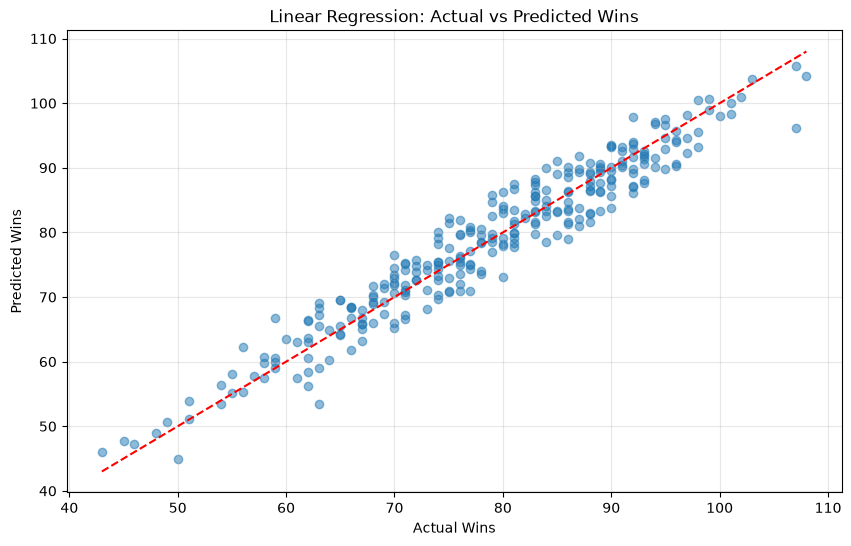

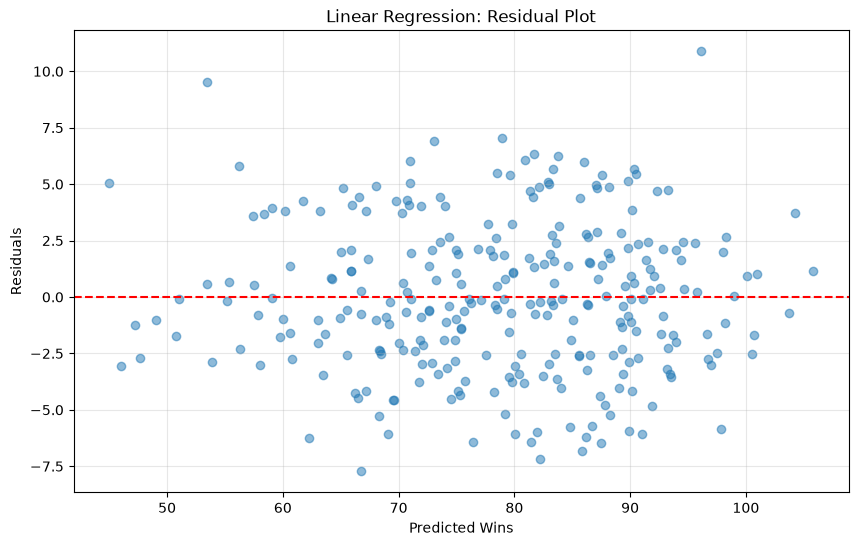

In [7]:
# Visualize actual vs predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, lr_test_preds, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Wins')
plt.ylabel('Predicted Wins')
plt.title('Linear Regression: Actual vs Predicted Wins')
plt.grid(True, alpha=0.3)

# Add residual plot
plt.figure(figsize=(10, 6))
residuals = y_test - lr_test_preds
plt.scatter(lr_test_preds, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Wins')
plt.ylabel('Residuals')
plt.title('Linear Regression: Residual Plot')
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
# Prepare Submission

# Align features and scale using the previously fitted scaler
predict_scaled = predict_df[available_features].copy()
predict_scaled[other_cols] = scaler.transform(predict_scaled[other_cols])

# Predict wins for the new dataset (replace `lr` with your final model if you change it)
predict_preds = lr.predict(predict_scaled)

# Build submission in the same format as submission.csv
submission_df = pd.DataFrame({
    'ID': predict_df['ID'],
    'W': np.round(predict_preds).astype(int)
})

submission_path = 'sample_submission.csv'
submission_df.to_csv(submission_path, index=False)
print(f"Kaggle submission saved to {submission_path}")

Kaggle submission saved to sample_submission.csv


## Next steps: how to improve your model

You now have a working baseline (linear regression on the raw team stats). Use the three areas below as starting points to explore on your own. Judge every change with the **same validation approach** (see the tuning section) so you know whether it really helped.

### 1. Feature engineering

The raw columns are only a starting point. Think about what actually makes a baseball team win, and whether you can turn the existing columns into new ones that describe it better.


- **Adjust for context:** seasons differ in the number of games played, and the amount of scoring has changed over baseball's history. For example, the average team scored about 3.4 runs per game in 1908 but about 5.5 in 1930, so 700 runs would be an excellent season in one era and an average one in the other. How could you adjust the stats so teams from different seasons can be compared fairly?
- **Combine columns:** differences, ratios or totals of existing stats can say more than each one on its own. For example, a ratio like hits divided by at-bats (`H / AB`) tells you how often a team gets a hit, not just how many it got. Two teams can both record 1,400 hits, but if one needed far more at-bats to get there, it was less effective at the plate. The ratio puts the raw count in the context of the opportunities behind it.
- **Look beyond straight lines:** does the relationship between a stat and wins always look the same?
- **Remove or reduce:** are some columns telling you the same thing? Would fewer features work just as well?


The feature-selection cell above uses every numeric column shared by both files, so any new column needs to be added to **both** `data_df` and `predict_df` before that cell runs.


### 2. Try different ML models

Swap the model while keeping the same features and the same train/test split, then compare MAE, RMSE and R² (ideally using the cross-validation approach described in the tuning section below). This list is **not exhaustive**: treat it as a set of starting points, and feel free to try other models.

- **Regularised linear models:** `Ridge`, `Lasso`, `ElasticNet`. Plain linear regression chooses whatever coefficients fit the training data best, which can make them large and unstable when features overlap or there are many of them. Regularised versions add a penalty on large coefficients, accepting a slightly worse fit on the training data in return for a simpler model that often generalises better. `Ridge` shrinks all coefficients, `Lasso` can shrink some to exactly zero (effectively dropping those features), and `ElasticNet` mixes the two.
- **Tree ensembles:** `RandomForestRegressor`, `GradientBoostingRegressor`, `HistGradientBoostingRegressor`. Instead of one formula, these combine many decision trees (series of yes/no splits on the features). They can pick up curved relationships and interactions between features without you creating them. A random forest builds many trees independently and averages them, while gradient boosting builds trees one after another, each trying to fix the mistakes of the ones before.
- **Gradient boosting libraries:** `XGBoost`, `LightGBM`. Faster, more heavily optimised versions of the boosting idea above, with many more settings to tune. They are popular in data science competitions.
- **Other families:** `SVR` fits a flexible curve while tolerating small errors, and `KNeighborsRegressor` predicts by averaging the most similar teams in the training data. Both are sensitive to the scale of the features, so use the scaled data from earlier (tree-based models do not need it).
- **Stacking:** combine several different models, since their mistakes often partly cancel out. `StackingRegressor` trains another model (the "final estimator") to learn the best way to combine the predictions of the models you give it. `VotingRegressor` is a simpler alternative that just averages their predictions.

Things to look out for: compare **training vs test error** to spot overfitting (a large gap means the model is memorising), and remember that a more complex model is not automatically better. Check whether it beats the linear baseline by enough to matter.



### 3. Hyperparameter tuning

Hyperparameters (settings you choose before training, such as tree depth or regularisation strength) can change performance.

- **Use cross-validation, not one split:** `KFold` / `cross_val_score` give a more reliable estimate than a single `train_test_split`, which can be lucky or unlucky. Wrap the scaler and model in a `Pipeline` so scaling is refit inside each fold.
- **Grid search:** `GridSearchCV` tries every combination you list (good for small search spaces).
- **Random search:** `RandomizedSearchCV` samples combinations (more efficient for larger spaces).
- **What to tune** (examples only, not an exhaustive list):
  - Ridge / Lasso: `alpha`
  - Random Forest: `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`
  - XGBoost / LightGBM: `learning_rate`, `n_estimators`, `max_depth`, `subsample`, `colsample_bytree`, `reg_lambda`

A good workflow: set a baseline, change **one thing at a time**, record the cross-validated score, and keep only the changes that clearly help.

In [9]:
# =====================================================
# E1 — Baseline Lasso Regression (44 Original Features)
# =====================================================

import numpy as np

from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Step 1 — Use original 44 features
X_train_e1_44 = X_train.copy()
X_test_e1_44 = X_test.copy()

# Step 2 — Identify numerical features
scale_cols_e1_44 = [
    col for col in X_train_e1_44.columns
    if not col.startswith(("era_", "decade_"))
]

# Step 3 — Standardize numerical features
preprocessor_e1_44 = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), scale_cols_e1_44)
    ],
    remainder="passthrough"
)

# Step 4 — Create baseline Lasso
lasso_e1_44 = Pipeline([
    ("preprocessing", preprocessor_e1_44),
    ("lasso", Lasso(alpha=1.0, max_iter=100000))
])

# Step 5 — Train model
lasso_e1_44.fit(X_train_e1_44, y_train)

# Step 6 — Predictions
e1_44_train_preds = lasso_e1_44.predict(X_train_e1_44)
e1_44_test_preds = lasso_e1_44.predict(X_test_e1_44)

# Step 7 — Evaluate model
print("E1 — Baseline Lasso Regression (44 Features)")
print("-------------------------------------------")

print("Original features:", X_train_e1_44.shape[1])
print("Alpha:", 1.0)

print("\nTraining")
print("MAE :", round(mean_absolute_error(y_train, e1_44_train_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train, e1_44_train_preds)), 4))
print("R²  :", round(r2_score(y_train, e1_44_train_preds), 4))

print("\nTesting")
print("MAE :", round(mean_absolute_error(y_test, e1_44_test_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, e1_44_test_preds)), 4))
print("R²  :", round(r2_score(y_test, e1_44_test_preds), 4))

# Step 8 — Feature selection
e1_44_coefs = lasso_e1_44.named_steps["lasso"].coef_

selected_features = np.sum(np.abs(e1_44_coefs) > 1e-6)

print("\nFeature Selection")
print("Total features   :", len(e1_44_coefs))
print("Selected features:", selected_features)
print("Zero coefficients:", len(e1_44_coefs) - selected_features)

E1 — Baseline Lasso Regression (44 Features)
-------------------------------------------
Original features: 44
Alpha: 1.0

Training
MAE : 3.3834
RMSE: 4.2713
R²  : 0.8991

Testing
MAE : 3.3231
RMSE: 3.9909
R²  : 0.9003

Feature Selection
Total features   : 44
Selected features: 5
Zero coefficients: 39


In [10]:
# ============================================================
# RESTORE — LASSO 44 FEATURES
# GridSearchCV + Predictions + Evaluation
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split, GridSearchCV, KFold
)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# STEP 1 — Load original data
DATA_DIR = Path.home() / "MLB"

data_44 = pd.read_csv(DATA_DIR / "data.csv")
predict_44 = pd.read_csv(DATA_DIR / "predict.csv")

exclude = {
    "W", "ID", "yearID", "teamID",
    "year_label", "decade_label", "win_bins"
}

features_44 = [
    c for c in data_44.columns
    if c in predict_44.columns
    and c not in exclude
    and pd.api.types.is_numeric_dtype(data_44[c])
]

X_44 = data_44[features_44].copy()
y_44 = data_44["W"].copy()

assert len(features_44) == 44

# STEP 2 — Same train/test split
X_train_44, X_test_44, y_train, y_test = train_test_split(
    X_44,
    y_44,
    test_size=0.2,
    random_state=42
)

# STEP 3 — Prepare preprocessing
scale_cols_44 = [
    c for c in features_44
    if not c.startswith(("era_", "decade_"))
]

preprocessor_44 = ColumnTransformer(
    [("scale", StandardScaler(), scale_cols_44)],
    remainder="passthrough"
)

# STEP 4 — Lasso pipeline
pipeline_44 = Pipeline([
    ("preprocessing", preprocessor_44),
    ("lasso", Lasso(max_iter=100000))
])

# STEP 5 — Five-fold CV alpha tuning
cv_44 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_44 = GridSearchCV(
    pipeline_44,
    {
        "lasso__alpha": [
            1.0, 0.5, 0.1, 0.05, 0.01, 0.001
        ]
    },
    cv=cv_44,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_44.fit(X_train_44, y_train)

# STEP 6 — Restore trained model and predictions
lasso_44 = grid_44.best_estimator_

train_preds_44 = lasso_44.predict(X_train_44)
test_preds_44 = lasso_44.predict(X_test_44)

# STEP 7 — Display results
print("LASSO — 44 FEATURES RESTORED")
print("===========================")

print("Best Alpha:", grid_44.best_params_["lasso__alpha"])
print("CV MAE:", round(-grid_44.best_score_, 4))

print("\nTRAINING")
print("MAE :", round(mean_absolute_error(
    y_train, train_preds_44), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(
    y_train, train_preds_44)), 4))
print("R²  :", round(r2_score(
    y_train, train_preds_44), 4))

print("\nTESTING")
print("MAE :", round(mean_absolute_error(
    y_test, test_preds_44), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(
    y_test, test_preds_44)), 4))
print("R²  :", round(r2_score(
    y_test, test_preds_44), 4))

print("\nRESTORED VARIABLES")
for name in [
    "grid_44",
    "lasso_44",
    "train_preds_44",
    "test_preds_44"
]:
    print("OK:", name)

LASSO — 44 FEATURES RESTORED
Best Alpha: 0.01
CV MAE: 2.819

TRAINING
MAE : 2.6956
RMSE: 3.4084
R²  : 0.9357

TESTING
MAE : 2.6898
RMSE: 3.3248
R²  : 0.9308

RESTORED VARIABLES
OK: grid_44
OK: lasso_44
OK: train_preds_44
OK: test_preds_44


In [11]:
# ============================================================
# E2 — Alpha Tuning Results (44 Original Features)
# ============================================================

import pandas as pd

# Retrieve results from existing GridSearchCV
cv_results_44 = pd.DataFrame(grid_44.cv_results_)

# Create alpha comparison table
alpha_results_44 = pd.DataFrame({
    "Alpha": cv_results_44["param_lasso__alpha"].astype(float),
    "CV_MAE": -cv_results_44["mean_test_score"],
    "CV_STD": cv_results_44["std_test_score"],
    "Rank": cv_results_44["rank_test_score"]
})

# Show results from each of the five folds
for i in range(5):
    alpha_results_44[f"Fold_{i+1}_MAE"] = (
        -cv_results_44[f"split{i}_test_score"]
    )

alpha_results_44 = alpha_results_44.sort_values(
    "Alpha", ascending=False
)

print("E2 — Lasso Alpha Tuning (44 Features)")
print("------------------------------------")
print(alpha_results_44.round(4).to_string(index=False))

# Display best alpha
print("\nBest Alpha:", grid_44.best_params_["lasso__alpha"])
print("Best CV MAE:", round(-grid_44.best_score_, 4))

E2 — Lasso Alpha Tuning (44 Features)
------------------------------------
 Alpha  CV_MAE  CV_STD  Rank  Fold_1_MAE  Fold_2_MAE  Fold_3_MAE  Fold_4_MAE  Fold_5_MAE
 1.000  3.4147  0.2216     6      3.5179      3.0160      3.5372      3.3494      3.6529
 0.500  3.1482  0.1064     5      3.1293      2.9560      3.2658      3.1712      3.2186
 0.100  2.9490  0.0777     4      2.8971      2.9296      3.0576      3.0158      2.8446
 0.050  2.8729  0.0892     3      2.8595      2.8223      2.9703      2.9723      2.7399
 0.010  2.8190  0.0864     1      2.8015      2.7355      2.8711      2.9578      2.7290
 0.001  2.8226  0.0944     2      2.7957      2.7114      2.8552      2.9868      2.7639

Best Alpha: 0.01
Best CV MAE: 2.819


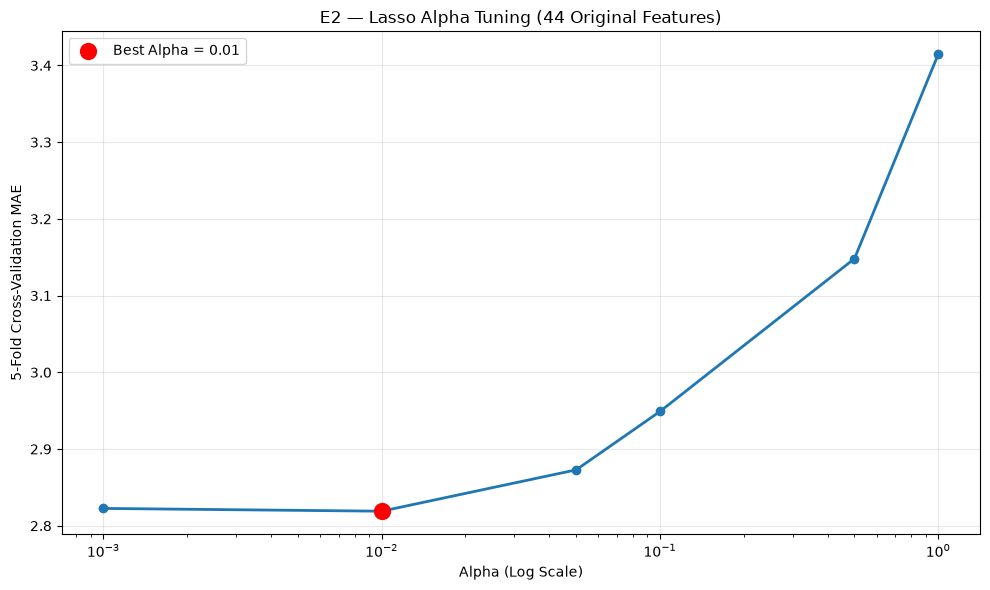

In [12]:
# ============================================================
# E2 — Visualize Alpha Tuning (44 Features)
# ============================================================

import matplotlib.pyplot as plt

plot_df = alpha_results_44.sort_values("Alpha")

best_alpha = float(grid_44.best_params_["lasso__alpha"])
best_mae = -grid_44.best_score_

plt.figure(figsize=(10, 6))

plt.plot(
    plot_df["Alpha"],
    plot_df["CV_MAE"],
    marker="o",
    linewidth=2
)

plt.scatter(
    best_alpha,
    best_mae,
    color="red",
    s=130,
    zorder=5,
    label=f"Best Alpha = {best_alpha}"
)

plt.xscale("log")

plt.xlabel("Alpha (Log Scale)")
plt.ylabel("5-Fold Cross-Validation MAE")
plt.title("E2 — Lasso Alpha Tuning (44 Original Features)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# Step 3 — Tuned Lasso Regression (44 Original Features)
# ============================================================

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the existing trained 44-feature Lasso model
train_pred = lasso_44.predict(X_train_44)
test_pred = lasso_44.predict(X_test_44)

# Display model configuration
print("Tuned Lasso Regression — 44 Features")
print("------------------------------------")
print("Features:", X_train_44.shape[1])
print("Best Alpha:", grid_44.best_params_["lasso__alpha"])

# Training results
print("\nTraining")
print("MAE :", round(mean_absolute_error(y_train, train_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train, train_pred)), 4))
print("R²  :", round(r2_score(y_train, train_pred), 4))

# Testing results
print("\nTesting")
print("MAE :", round(mean_absolute_error(y_test, test_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, test_pred)), 4))
print("R²  :", round(r2_score(y_test, test_pred), 4))

# Feature selection
coefficients = lasso_44.named_steps["lasso"].coef_

selected = np.sum(np.abs(coefficients) > 1e-6)
zero = len(coefficients) - selected

print("\nFeature Selection")
print("Total Features   :", len(coefficients))
print("Selected Features:", selected)
print("Zero Coefficients:", zero)

Tuned Lasso Regression — 44 Features
------------------------------------
Features: 44
Best Alpha: 0.01

Training
MAE : 2.6956
RMSE: 3.4084
R²  : 0.9357

Testing
MAE : 2.6898
RMSE: 3.3248
R²  : 0.9308

Feature Selection
Total Features   : 44
Selected Features: 33
Zero Coefficients: 11


In [14]:
# ============================================================
# Compare Baseline vs Tuned Lasso — 44 Features
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

comparison_44 = pd.DataFrame({
    "Metric": [
        "Features",
        "Alpha",
        "Testing MAE",
        "Testing RMSE",
        "Testing R²",
        "Selected Features",
        "Zero Coefficients"
    ],
    "E1_Baseline": [
        44,
        1.0,
        mean_absolute_error(y_test, e1_44_test_preds),
        np.sqrt(mean_squared_error(y_test, e1_44_test_preds)),
        r2_score(y_test, e1_44_test_preds),
        np.sum(np.abs(lasso_e1_44.named_steps["lasso"].coef_) > 1e-6),
        np.sum(np.abs(lasso_e1_44.named_steps["lasso"].coef_) <= 1e-6)
    ],
    "E5_Tuned": [
        44,
        grid_44.best_params_["lasso__alpha"],
        mean_absolute_error(y_test, test_preds_44),
        np.sqrt(mean_squared_error(y_test, test_preds_44)),
        r2_score(y_test, test_preds_44),
        np.sum(np.abs(lasso_44.named_steps["lasso"].coef_) > 1e-6),
        np.sum(np.abs(lasso_44.named_steps["lasso"].coef_) <= 1e-6)
    ]
})

print("Baseline vs Tuned Lasso (44 Features)")
print("------------------------------------")
print(comparison_44.round(4).to_string(index=False))

Baseline vs Tuned Lasso (44 Features)
------------------------------------
           Metric  E1_Baseline  E5_Tuned
         Features      44.0000   44.0000
            Alpha       1.0000    0.0100
      Testing MAE       3.3231    2.6898
     Testing RMSE       3.9909    3.3248
       Testing R²       0.9003    0.9308
Selected Features       5.0000   33.0000
Zero Coefficients      39.0000   11.0000


## Step 3 — Tuned Lasso Regression (44 Original Features)

### 1. Objective

Evaluate the performance of Lasso Regression using the original 44 features and the optimal alpha selected through five-fold cross-validation.

The objective is to determine whether hyperparameter tuning improves prediction accuracy compared with the baseline Lasso model (alpha = 1.0).

### 2. Model Configuration

- **Algorithm:** Lasso Regression (L1 Regularization)
- **Input features:** 44 original features
- **Training observations:** 1,129
- **Testing observations:** 283
- **Best alpha:** 0.01
- **Best cross-validation MAE:** 2.8190
- **Evaluation metrics:** MAE, RMSE and R²

### 3. Tuned Model Results

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 2.6956 | 2.6898 |
| RMSE | 3.4084 | 3.3248 |
| R² | 0.9357 | 0.9308 |

### 4. Feature Selection

| Description | Number |
|---|---:|
| Total original features | 44 |
| Selected features | 33 |
| Zero coefficients | 11 |

Lasso applied L1 regularization and reduced 11 feature coefficients to zero, leaving 33 active features contributing directly to predictions.

### 5. Comparison — Baseline vs Tuned Lasso

| Metric | Baseline Lasso | Tuned Lasso |
|---|---:|---:|
| Alpha | 1.0 | 0.01 |
| Training MAE | 3.3834 | 2.6956 |
| Testing MAE | 3.3231 | 2.6898 |
| Testing RMSE | 3.9909 | 3.3248 |
| Testing R² | 0.9003 | 0.9308 |
| Active Features | 5 | 33 |
| Zero Coefficients | 39 | 11 |

### 6. Key Findings

**Finding 1 — Alpha tuning improved prediction accuracy.**

Reducing alpha from 1.0 to 0.01 decreased testing MAE from 3.3231 to 2.6898 wins.

This represents an improvement of approximately **19.1%** in testing MAE.

**Finding 2 — Weaker regularization retained more useful predictors.**

The baseline model retained only 5 active features, while the tuned model retained 33.

This suggests that alpha = 1.0 imposed excessive regularization and removed useful predictive information.

**Finding 3 — Training and testing performance were comparable.**

The tuned model achieved training MAE of 2.6956 and testing MAE of 2.6898.

The small difference suggests no substantial generalization gap on this particular train-test split. However, performance on other datasets may differ.

**Finding 4 — The model explained a high proportion of variation in wins.**

The testing R² of 0.9308 indicates that the tuned model explained approximately 93.08% of the variation in season wins within the testing dataset.

### 7. Conclusion

Five-fold cross-validation identified alpha = 0.01 as the best tested regularization parameter for the original 44-feature Lasso Regression model.

The tuned model substantially outperformed the baseline model, reducing testing MAE by approximately 19.1% while retaining 33 active features.

**The results demonstrate that appropriate alpha tuning improved predictive accuracy by reducing excessive regularization.**

---

## Step 4 — Actual vs Predicted Wins Visualization

### Objective

Visualize the relationship between actual MLB season wins and the wins predicted by the tuned 44-feature Lasso Regression model.

### Graph Interpretation

- **X-axis:** Actual season wins
- **Y-axis:** Predicted season wins
- **Red diagonal line:** Perfect predictions
- **Points close to the diagonal:** Smaller prediction errors
- **Points above the diagonal:** Overprediction of wins
- **Points below the diagonal:** Underprediction of wins

The visualization is used to assess prediction accuracy, identify large errors, and investigate whether the model systematically overpredicts or underpredicts wins.

The tuned model's testing MAE of 2.6898 indicates an average absolute prediction error of approximately 2.69 wins.

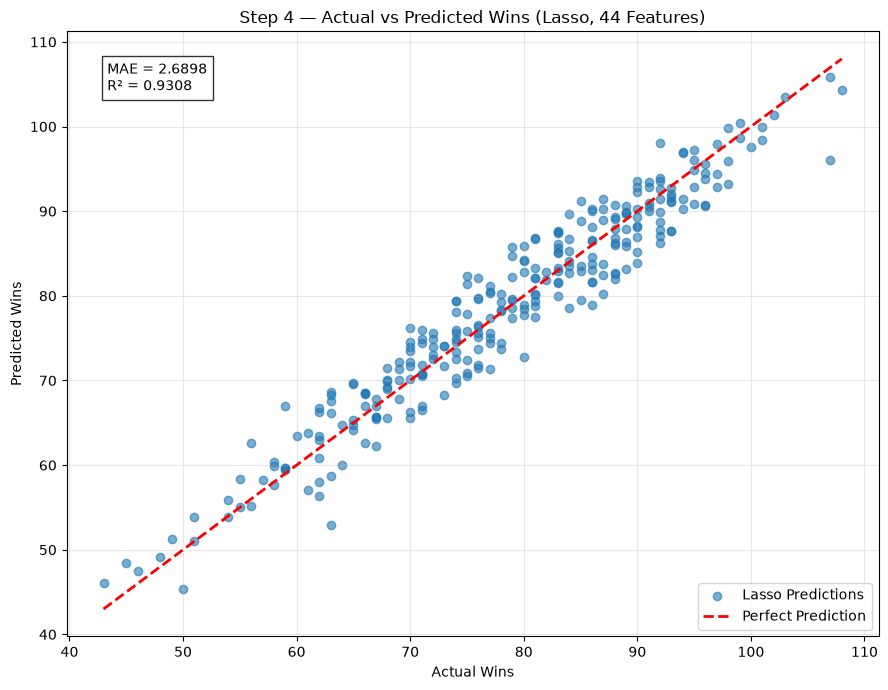

Step 4 — Actual vs Predicted Wins
---------------------------------
Test Observations: 283
Testing MAE: 2.6898
Testing R² : 0.9308


In [15]:
# ============================================================
# Step 4 — Actual vs Predicted Wins
# Tuned Lasso Regression (44 Original Features)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

# Step 1 — Get actual and predicted wins
actual_wins = np.asarray(y_test)
predicted_wins = lasso_44.predict(X_test_44)

# Step 2 — Calculate performance
mae = mean_absolute_error(actual_wins, predicted_wins)
r2 = r2_score(actual_wins, predicted_wins)

# Step 3 — Create scatter plot
plt.figure(figsize=(9, 7))

plt.scatter(
    actual_wins,
    predicted_wins,
    alpha=0.6,
    label="Lasso Predictions"
)

# Step 4 — Perfect prediction line
min_wins = min(actual_wins.min(), predicted_wins.min())
max_wins = max(actual_wins.max(), predicted_wins.max())

plt.plot(
    [min_wins, max_wins],
    [min_wins, max_wins],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

# Step 5 — Labels and title
plt.xlabel("Actual Wins")
plt.ylabel("Predicted Wins")
plt.title("Step 4 — Actual vs Predicted Wins (Lasso, 44 Features)")

# Step 6 — Display performance on graph
plt.text(
    0.05, 0.95,
    f"MAE = {mae:.4f}\nR² = {r2:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 7 — Print model results
print("Step 4 — Actual vs Predicted Wins")
print("---------------------------------")
print("Test Observations:", len(actual_wins))
print("Testing MAE:", round(mae, 4))
print("Testing R² :", round(r2, 4))

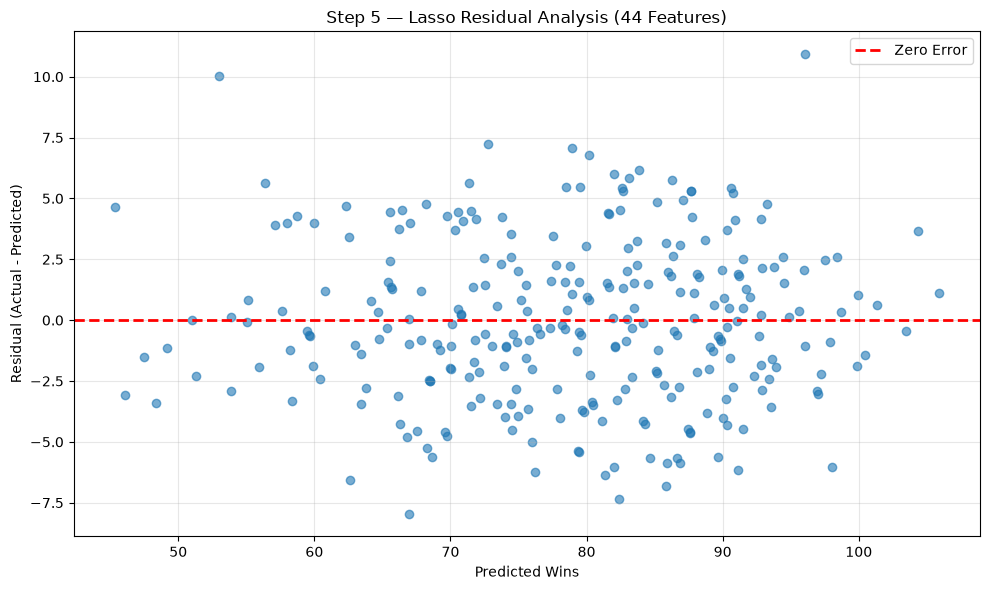

Step 5 — Residual Analysis
--------------------------
Mean Residual: -0.0692
Underpredicted: 134
Overpredicted : 149
Total Observations: 283


In [16]:
# ============================================================
# Step 5 — Residual Analysis
# Tuned Lasso Regression (44 Original Features)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Step 1 — Calculate residuals
# Residual = Actual Wins - Predicted Wins

residuals_44 = actual_wins - predicted_wins

# Step 2 — Plot residuals
plt.figure(figsize=(10, 6))

plt.scatter(
    predicted_wins,
    residuals_44,
    alpha=0.6
)

# Zero-error reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.xlabel("Predicted Wins")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Step 5 — Lasso Residual Analysis (44 Features)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 3 — Calculate prediction bias
mean_residual = np.mean(residuals_44)

underpredicted = np.sum(residuals_44 > 0)
overpredicted = np.sum(residuals_44 < 0)

print("Step 5 — Residual Analysis")
print("--------------------------")
print("Mean Residual:", round(mean_residual, 4))
print("Underpredicted:", underpredicted)
print("Overpredicted :", overpredicted)
print("Total Observations:", len(residuals_44))

## Step 5 — Residual Analysis (Tuned Lasso Regression, 44 Features)

### 1. Objective

Evaluate the prediction errors of the tuned Lasso Regression model to determine whether it systematically overpredicts or underpredicts MLB team-season wins.

Residual analysis helps assess prediction bias and provides additional information beyond MAE, RMSE and R².

### 2. Methodology

Residuals were calculated using the difference between actual and predicted wins.

**Residual = Actual Wins − Predicted Wins**

- **Positive residual:** The model underpredicts actual wins.
- **Negative residual:** The model overpredicts actual wins.
- **Zero residual:** The predicted wins equal the actual wins.

A residual scatterplot was generated with predicted wins on the X-axis and residuals on the Y-axis. A horizontal reference line at zero represents perfect predictions.

### 3. Residual Analysis Results

| Measurement | Result |
|---|---:|
| Model | Tuned Lasso Regression |
| Input Features | 44 |
| Alpha | 0.01 |
| Testing Observations | 283 |
| Testing MAE | 2.6898 |
| Mean Residual | -0.0692 |
| Underpredicted Observations | 134 |
| Overpredicted Observations | 149 |

### 4. Key Findings

**Finding 1 — Minimal average prediction bias**

The mean residual was -0.0692 wins, indicating that the model overpredicted actual wins by approximately 0.07 wins on average.

Because the mean residual is close to zero, the model demonstrates minimal overall signed prediction bias on the testing dataset.

**Finding 2 — Overpredictions and underpredictions were relatively balanced**

Out of 283 testing observations:

- 149 observations were overpredicted (52.7%).
- 134 observations were underpredicted (47.3%).

The relatively balanced distribution suggests that neither overprediction nor underprediction overwhelmingly dominated the testing observations.

**Finding 3 — Mean residual and MAE measure different aspects of prediction error**

The mean residual measures the direction of prediction bias, whereas MAE measures the average absolute magnitude of prediction errors.

Although the mean residual was close to zero, the testing MAE was 2.6898 wins.

This occurs because positive and negative residuals can cancel each other when calculating the mean residual.

Therefore, a small mean residual does not necessarily mean that individual prediction errors are small.

### 5. Limitations

A mean residual close to zero does not guarantee that predictions are unbiased for every team or across different win ranges.

The residual scatterplot should also be inspected for systematic patterns, unusually large errors and changes in error variability.

The reported results describe performance on the current testing dataset and do not guarantee identical behaviour on unseen observations.

### 6. Conclusion

Residual analysis of the tuned 44-feature Lasso Regression model identified a mean residual of -0.0692 wins, indicating minimal average prediction bias.

The model overpredicted 149 observations and underpredicted 134 observations, showing relatively balanced prediction directions.

Together with a testing MAE of 2.6898 and R² of 0.9308, the results indicate strong predictive performance on the testing dataset.

**Overall, the tuned Lasso model demonstrates low average signed bias, although individual prediction errors remain and should be evaluated separately.**


Step 6 — Lasso Feature Selection
--------------------------------
Total Features: 44
Selected Features: 33
Zero Coefficients: 11

Selected Features:
    Feature  Coefficient
          R     8.886136
         RA    -6.473553
         AB    -5.058800
     IPouts     5.005925
         SV     4.028472
         CG     3.265506
      era_1    -2.672911
          H     2.569764
decade_1940     1.828959
decade_1920    -1.022628
        SHO     0.808565
        BBA    -0.709607
decade_1930     0.574604
          E    -0.539698
      era_6    -0.491767
decade_1990    -0.460389
decade_1950     0.455893
        SOA     0.453516
         HA    -0.401591
         HR     0.365876
         BB    -0.356628
          G    -0.354976
    mlb_rpg     0.295843
         3B     0.259226
         ER    -0.227618
         SB    -0.201912
         2B     0.186842
decade_1970     0.184824
         DP     0.067834
decade_1910    -0.054032
         SO     0.026202
      era_7    -0.014640
      era_4     0.007296



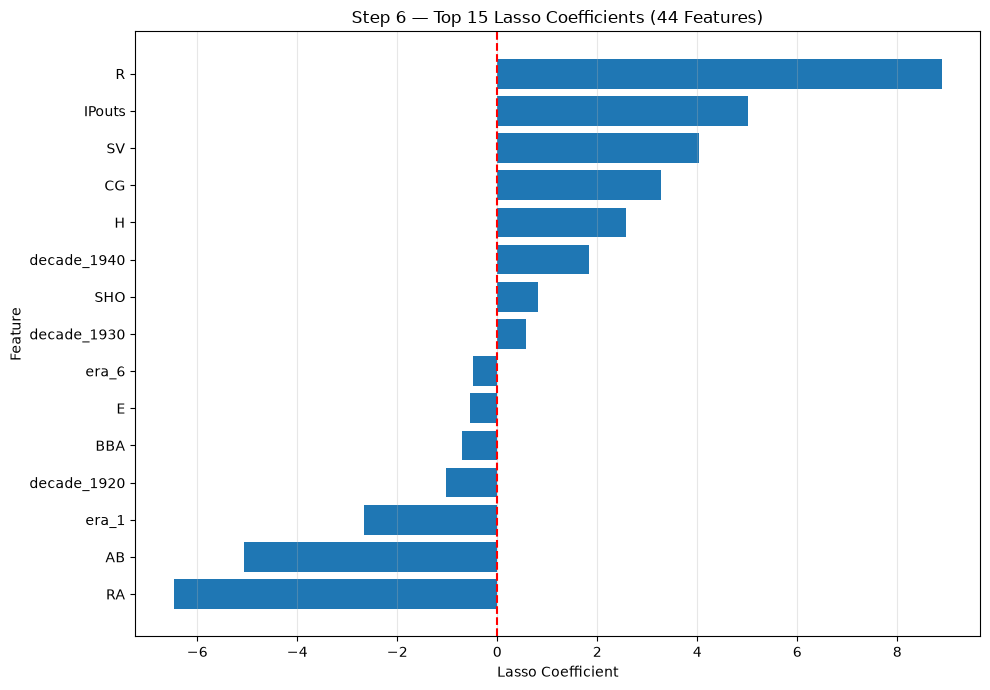

In [17]:
# ============================================================
# Step 6 — Lasso Feature Selection (44 Original Features)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Get feature names in the same order used by the pipeline
feature_names = (
    lasso_44.named_steps["preprocessing"]
    .get_feature_names_out()
)

# Remove preprocessing prefixes from names
feature_names = [
    name.split("__", 1)[-1]
    for name in feature_names
]

# Get Lasso coefficients
coefficients = lasso_44.named_steps["lasso"].coef_

# Create coefficient table
feature_df_44 = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_df_44["Absolute_Coefficient"] = (
    feature_df_44["Coefficient"].abs()
)

# Separate selected and zero-coefficient features
selected_df_44 = feature_df_44[
    feature_df_44["Absolute_Coefficient"] > 1e-6
].sort_values("Absolute_Coefficient", ascending=False)

zero_df_44 = feature_df_44[
    feature_df_44["Absolute_Coefficient"] <= 1e-6
]

print("Step 6 — Lasso Feature Selection")
print("--------------------------------")
print("Total Features:", len(feature_df_44))
print("Selected Features:", len(selected_df_44))
print("Zero Coefficients:", len(zero_df_44))

print("\nSelected Features:")
print(selected_df_44[["Feature", "Coefficient"]].to_string(index=False))

print("\nZero-Coefficient Features:")
print(zero_df_44["Feature"].to_string(index=False))

# Plot top 15 coefficients
top15 = selected_df_44.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top15["Feature"],
    top15["Coefficient"]
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Lasso Coefficient")
plt.ylabel("Feature")
plt.title("Step 6 — Top 15 Lasso Coefficients (44 Features)")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Step 7 — Permutation Feature Importance
---------------------------------------
Model: Tuned Lasso Regression
Features: 44
Alpha: 0.01

Feature Importance Results:
    Feature  Importance_Mean  Importance_STD
          R         6.919894        0.369933
         RA         4.708178        0.214511
     IPouts         3.839526        0.148085
         AB         3.551904        0.105283
         SV         2.420093        0.169055
         CG         1.881524        0.104375
          H         1.242220        0.072594
        SHO         0.161708        0.039764
decade_1940         0.087170        0.018533
      era_1         0.084328        0.023593
          G         0.053278        0.010364
         HA         0.042662        0.019303
          E         0.041665        0.021361
        BBA         0.037390        0.034102
         3B         0.026853        0.011352
decade_1930         0.024815        0.007760
decade_1920         0.024027        0.018596
    mlb_rpg         0.0168

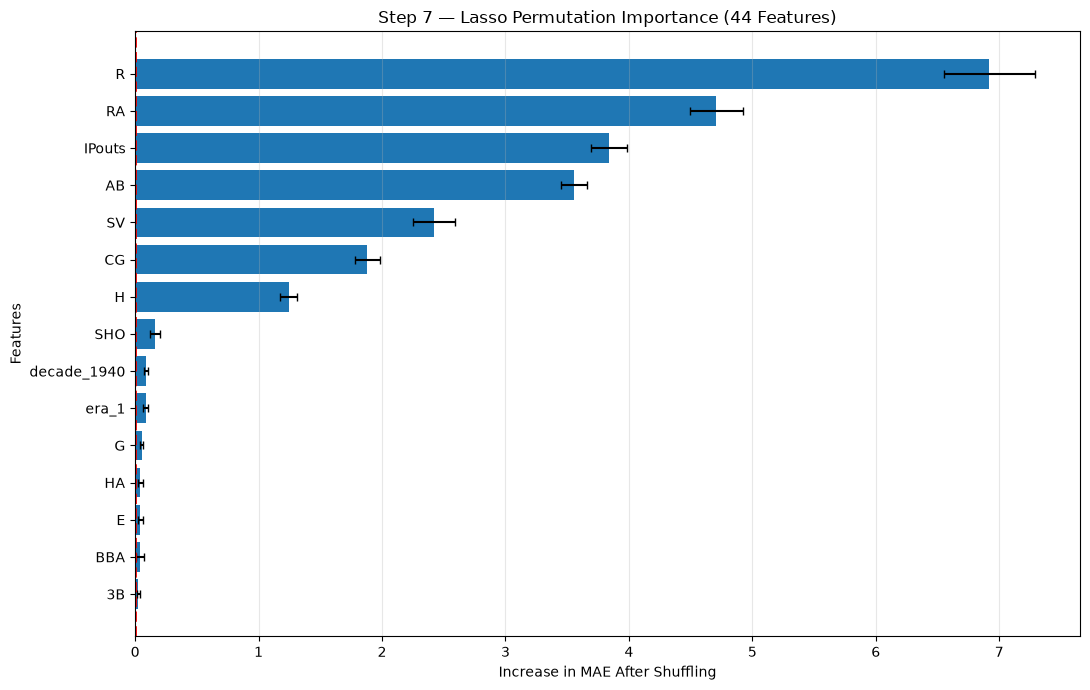

In [18]:
# ============================================================
# Step 7 — Permutation Feature Importance
# Tuned Lasso Regression (44 Original Features)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# Step 1 — Calculate permutation importance
step7_perm = permutation_importance(
    lasso_44,
    X_test_44,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Step 2 — Create feature importance table
step7_importance_df = pd.DataFrame({
    "Feature": X_test_44.columns,
    "Importance_Mean": step7_perm.importances_mean,
    "Importance_STD": step7_perm.importances_std
})

# Step 3 — Rank features
step7_importance_df = step7_importance_df.sort_values(
    "Importance_Mean",
    ascending=False
)

print("Step 7 — Permutation Feature Importance")
print("---------------------------------------")
print("Model: Tuned Lasso Regression")
print("Features: 44")
print("Alpha:", grid_44.best_params_["lasso__alpha"])

print("\nFeature Importance Results:")
print(step7_importance_df.round(6).to_string(index=False))

# Step 4 — Plot Top 15 Features
top15_step7 = step7_importance_df.head(15).sort_values(
    "Importance_Mean"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top15_step7["Feature"],
    top15_step7["Importance_Mean"],
    xerr=top15_step7["Importance_STD"],
    capsize=3
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Increase in MAE After Shuffling")
plt.ylabel("Features")
plt.title("Step 7 — Lasso Permutation Importance (44 Features)")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Feature Engineering — Step 1: Adjust for Season Length

### Objective
Create a new feature to account for differences in the number of games played across MLB seasons.

### Business Rationale
MLB teams played different numbers of games across historical seasons. Comparing total runs scored may not provide a fair measure of offensive performance.

### Feature Engineering
Create a new feature called `R_per_game`:

**Formula:**

`R_per_game = R / G`

Where:
- `R` = Total runs scored
- `G` = Number of games played

### Expected Benefit
This feature measures average runs scored per game, allowing teams with different season lengths to be compared more consistently.

Whether this feature improves prediction accuracy will be evaluated later.

In [19]:
# Step 1 — Feature Engineering: Runs per Game

# Training dataset
data_df["R_per_game"] = data_df["R"] / data_df["G"]

# Kaggle prediction dataset
predict_df["R_per_game"] = predict_df["R"] / predict_df["G"]

# Verify new feature
print(data_df[["R", "G", "R_per_game"]].head())

     R    G  R_per_game
0  718  154    4.662338
1  835  162    5.154321
2  768  162    4.740741
3  713  154    4.629870
4  928  162    5.728395


Why do we update both datasets?
Because data.csv is used to train the model, while predict.csv is used to generate the Kaggle predictions. Both must contain the same engineered feature.

## Feature Engineering — Step 2: Runs Allowed per Game

### Objective
Create a feature to measure the average number of runs allowed per game.

### Rationale
MLB teams played different numbers of games across seasons. Total runs allowed (`RA`) may therefore be affected by season length.

Dividing runs allowed by games played allows a more consistent comparison of defensive performance.

### Formula
`RA_per_game = RA / G`

Where:
- `RA` = Total runs allowed
- `G` = Games played

### Expected Benefit
This feature measures run prevention per game instead of total runs allowed. Lower values generally indicate better defensive performance.

Its contribution to prediction accuracy will be evaluated during model training.

In [20]:
# Step 2 — Feature Engineering: Runs Allowed per Game

# Training dataset
data_df["RA_per_game"] = data_df["RA"] / data_df["G"]

# Kaggle prediction dataset
predict_df["RA_per_game"] = predict_df["RA"] / predict_df["G"]

# Verify new feature
print(data_df[["RA", "G", "RA_per_game"]].head())

    RA    G  RA_per_game
0  732  154     4.753247
1  751  162     4.635802
2  707  162     4.364198
3  598  154     3.883117
4  921  162     5.685185


## Feature Engineering — Step 3: Run Differential

### 1. Objective
Create a new feature, `Run_Differential`, to measure the difference between runs scored and runs allowed during an MLB season.

### 2. Rationale
Baseball teams win games by scoring more runs than their opponents.

Runs scored (`R`) measures offensive performance, while runs allowed (`RA`) measures run prevention.

Combining these two statistics provides a measure of overall scoring advantage.

### 3. Formula

`Run_Differential = R - RA`

Where:
- `R` = Total runs scored
- `RA` = Total runs allowed
- `Run_Differential` = Net runs scored during the season

### 4. Interpretation
- Positive value: The team scored more runs than it allowed.
- Negative value: The team allowed more runs than it scored.
- Zero: The team scored and allowed the same number of runs.

### 5. Expected Benefit
Run differential combines offensive and run-prevention performance into one feature that may help predict total season wins (`W`).

Its actual contribution to prediction accuracy will be evaluated later.

In [21]:
# Step 3 — Feature Engineering: Run Differential

# Training dataset
data_df["Run_Differential"] = data_df["R"] - data_df["RA"]

# Kaggle prediction dataset
predict_df["Run_Differential"] = predict_df["R"] - predict_df["RA"]

# Verify new feature
print(data_df[["R", "RA", "Run_Differential"]].head())

     R   RA  Run_Differential
0  718  732               -14
1  835  751                84
2  768  707                61
3  713  598               115
4  928  921                 7


In [22]:
# =====================================================
# LASSO — Prepare Separate Feature Dataset
# =====================================================

# Copy the original 44 features
X_lasso = X.copy()

# Add the 3 engineered features
engineered_features = [
    "R_per_game",
    "RA_per_game",
    "Run_Differential"
]

for col in engineered_features:
    X_lasso[col] = data_df[col]

# Verify feature counts
print("Original features:", X.shape[1])
print("Lasso features:", X_lasso.shape[1])

# Verify engineered features
print("\nEngineered features:")
print(X_lasso[engineered_features].head())

Original features: 44
Lasso features: 47

Engineered features:
   R_per_game  RA_per_game  Run_Differential
0    4.662338     4.753247               -14
1    5.154321     4.635802                84
2    4.740741     4.364198                61
3    4.629870     3.883117               115
4    5.728395     5.685185                 7


## Lasso Regression — Step 1: Prepare Training and Testing Data

### Objective
Prepare the Lasso dataset using 47 features while preserving the instructor's original 44-feature Linear Regression model.

### Method
Reuse the original training and testing row indices to ensure both models are evaluated on the same observations.

### Rationale
- Maintain consistency with the original 80/20 train/test split.
- Prevent changing the instructor's existing Linear Regression results.
- Prepare the engineered features for Lasso model training.

The target variable remains `W` (season wins).

In [23]:
# =====================================================
# Lasso — Step 1: Train/Test Preparation
# =====================================================

# Use the original training and testing row indices
X_lasso_train = X_lasso.loc[X_train.index].copy()
X_lasso_test = X_lasso.loc[X_test.index].copy()

# Keep the original target variable
y_lasso_train = y_train.copy()
y_lasso_test = y_test.copy()

# Verify dataset dimensions
print("Original features:", X.shape[1])
print("Lasso features:", X_lasso.shape[1])

print("\nLasso training shape:", X_lasso_train.shape)
print("Lasso testing shape:", X_lasso_test.shape)

Original features: 44
Lasso features: 47

Lasso training shape: (1129, 47)
Lasso testing shape: (283, 47)


## Lasso Regression — Step 2: Feature Scaling

### Objective
Standardize the numerical features in the Lasso dataset before model training.

### Rationale
Lasso Regression uses L1 regularization, which penalizes the absolute values of model coefficients.

Baseball statistics such as runs scored, earned run average and run differential have different numerical scales.

Standardization allows the L1 penalty to be applied more consistently across numerical features.

### Method
Use `StandardScaler` to standardize numerical features while retaining the original values of binary era and decade indicators.

The scaler is fitted using training data only and then applied to testing data to prevent data leakage.

A separate scaler is used to preserve the instructor's original Linear Regression preprocessing.

In [24]:
# =====================================================
# Lasso — Step 2: Feature Scaling
# =====================================================

from sklearn.preprocessing import StandardScaler

# Identify columns to scale
lasso_scale_cols = [
    col for col in X_lasso_train.columns
    if not col.startswith(("era_", "decade_"))
]

# Create separate scaler
lasso_scaler = StandardScaler()

# Copy datasets
X_lasso_train_scaled = X_lasso_train.copy()
X_lasso_test_scaled = X_lasso_test.copy()

# Fit scaler on training data only
X_lasso_train_scaled[lasso_scale_cols] = (
    lasso_scaler.fit_transform(
        X_lasso_train[lasso_scale_cols]
    )
)

# Apply same scaler to testing data
X_lasso_test_scaled[lasso_scale_cols] = (
    lasso_scaler.transform(
        X_lasso_test[lasso_scale_cols]
    )
)

# Verify
print("Lasso training:", X_lasso_train_scaled.shape)
print("Lasso testing:", X_lasso_test_scaled.shape)
print("Scaled features:", len(lasso_scale_cols))

Lasso training: (1129, 47)
Lasso testing: (283, 47)
Scaled features: 28


## Lasso Regression — Step 3: Model Training (E1)

### Objective
Train a Lasso Regression model to predict MLB season wins (`W`) using 47 features, including three engineered features.

### Rationale
Lasso Regression applies L1 regularization to reduce coefficient magnitudes and potentially remove redundant features by shrinking their coefficients to zero.

### Model Configuration

- **Algorithm:** Lasso Regression
- **Alpha:** 1.0 (initial value)
- **Maximum iterations:** 100,000
- **Training observations:** 1,129
- **Testing observations:** 283
- **Input features:** 47

### Expected Outcome
Train the model and generate predictions for both training and testing datasets. Model accuracy will be evaluated in the next step.

In [25]:
# =====================================================
# E1 — Lasso Regression: Model Training
# =====================================================

from sklearn.linear_model import Lasso

# Step 1 — Create Lasso model
lasso_e1 = Lasso(
    alpha=1.0,
    max_iter=100000
)

# Step 2 — Train model
lasso_e1.fit(X_lasso_train_scaled, y_lasso_train)

# Step 3 — Generate predictions
lasso_e1_train_preds = lasso_e1.predict(X_lasso_train_scaled)
lasso_e1_test_preds = lasso_e1.predict(X_lasso_test_scaled)

# Confirm training
print("E1 — Lasso Regression trained successfully!")
print("Alpha:", lasso_e1.alpha)
print("Training predictions:", len(lasso_e1_train_preds))
print("Testing predictions:", len(lasso_e1_test_preds))

E1 — Lasso Regression trained successfully!
Alpha: 1.0
Training predictions: 1129
Testing predictions: 283


## Lasso Regression — Step 4: Model Evaluation (E1)

### Objective
Evaluate the predictive performance of the Lasso Regression model using 47 features, including three engineered features.

### Evaluation Metrics

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted wins. Lower is better.
- **RMSE (Root Mean Squared Error):** Penalizes larger prediction errors more heavily. Lower is better.
- **R² (Coefficient of Determination):** Measures the proportion of variation in season wins explained by the model. Higher is generally better.

### Rationale
Compare training and testing performance to assess generalization and identify potential overfitting.

The official Kaggle competition metric is MAE, making it the primary metric for assessing model performance.

### Baseline Reference
The original 44-feature Linear Regression model achieved a test MAE of **2.7025 wins**.

This will serve as a reference, although the Lasso model uses three additional engineered features.

In [26]:
# =====================================================
# E1 — Step 4: Lasso Model Evaluation
# =====================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Training metrics
train_mae = mean_absolute_error(
    y_lasso_train, lasso_e1_train_preds
)

train_rmse = np.sqrt(mean_squared_error(
    y_lasso_train, lasso_e1_train_preds
))

train_r2 = r2_score(
    y_lasso_train, lasso_e1_train_preds
)

# Testing metrics
test_mae = mean_absolute_error(
    y_lasso_test, lasso_e1_test_preds
)

test_rmse = np.sqrt(mean_squared_error(
    y_lasso_test, lasso_e1_test_preds
))

test_r2 = r2_score(
    y_lasso_test, lasso_e1_test_preds
)

# Display results
print("E1 — Lasso Regression (alpha=1.0)")
print("----------------------------------")

print("\nTraining")
print(f"MAE : {train_mae:.4f}")
print(f"RMSE: {train_rmse:.4f}")
print(f"R²  : {train_r2:.4f}")

print("\nTesting")
print(f"MAE : {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R²  : {test_r2:.4f}")

print("\nGeneralization Gap")
print(f"MAE gap: {test_mae - train_mae:.4f}")

# Feature selection
selected = np.sum(np.abs(lasso_e1.coef_) > 1e-8)

print("\nFeature Selection")
print(f"Total features   : {len(lasso_e1.coef_)}")
print(f"Selected features: {selected}")
print(f"Zero coefficients: {len(lasso_e1.coef_) - selected}")

E1 — Lasso Regression (alpha=1.0)
----------------------------------

Training
MAE : 3.2763
RMSE: 4.1409
R²  : 0.9051

Testing
MAE : 3.1609
RMSE: 3.8578
R²  : 0.9069

Generalization Gap
MAE gap: -0.1153

Feature Selection
Total features   : 47
Selected features: 3
Zero coefficients: 44


In [27]:
# ============================================================
# E2 — Compare Lasso Regularization Strengths
# Adapted from instructor's L1 regularization example
# ============================================================

from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Step 1 — Try different alpha values
alphas = [1.0, 0.5, 0.1, 0.05, 0.01, 0.001]

# Step 2 — Use 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Step 3 — Keep scaling inside each CV fold
preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), lasso_scale_cols)
    ],
    remainder="passthrough"
)

# Step 4 — Compare alpha values
records = []

for alpha in alphas:

    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", Lasso(
            alpha=alpha,
            max_iter=100000
        ))
    ])

    # Cross-validation using MAE
    cv_mae = -cross_val_score(
        pipe,
        X_lasso_train,
        y_lasso_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    ).mean()

    # Train on full training dataset
    pipe.fit(X_lasso_train, y_lasso_train)

    # Count coefficients reduced to zero
    coefs = pipe.named_steps["model"].coef_

    n_zero = int(np.sum(np.abs(coefs) < 1e-6))

    # Store results
    records.append((
        alpha,
        cv_mae,
        len(coefs) - n_zero,
        n_zero,
        len(coefs)
    ))

# Step 5 — Display results
results_df = pd.DataFrame(
    records,
    columns=[
        "alpha",
        "CV_MAE",
        "Selected_Features",
        "Zero_Coefficients",
        "Total_Features"
    ]
)

print("E2 — Lasso Regularization Comparison")
print("-------------------------------------")
print(results_df.to_string(index=False))

# Step 6 — Find best alpha based on CV MAE
best_row = results_df.loc[results_df["CV_MAE"].idxmin()]

print("\nBest alpha:", best_row["alpha"])
print("Best CV MAE:", round(best_row["CV_MAE"], 4))

E2 — Lasso Regularization Comparison
-------------------------------------
 alpha   CV_MAE  Selected_Features  Zero_Coefficients  Total_Features
 1.000 3.299952                  3                 44              47
 0.500 3.137302                  6                 41              47
 0.100 2.959856                 13                 34              47
 0.050 2.875153                 18                 29              47
 0.010 2.819452                 32                 15              47
 0.001 2.824372                 43                  4              47

Best alpha: 0.01
Best CV MAE: 2.8195


## E3 — Tuned Lasso Regression (Alpha = 0.01)

### Objective

Evaluate the Lasso Regression model using the best alpha identified through five-fold cross-validation.

### Rationale

The E2 experiment compared six regularization strengths. Alpha = 0.01 achieved the lowest cross-validation MAE of 2.8195 and retained 32 out of 47 features.

### Methodology

- Model: Lasso Regression
- Alpha: 0.01
- Training observations: 1,129
- Testing observations: 283
- Input features: 47
- Feature scaling: StandardScaler fitted on training data

### Evaluation

Evaluate training and testing MAE, RMSE and R² to assess prediction accuracy and generalization.

The tuned model will be compared with the initial Lasso E1 model and the original Linear Regression baseline.

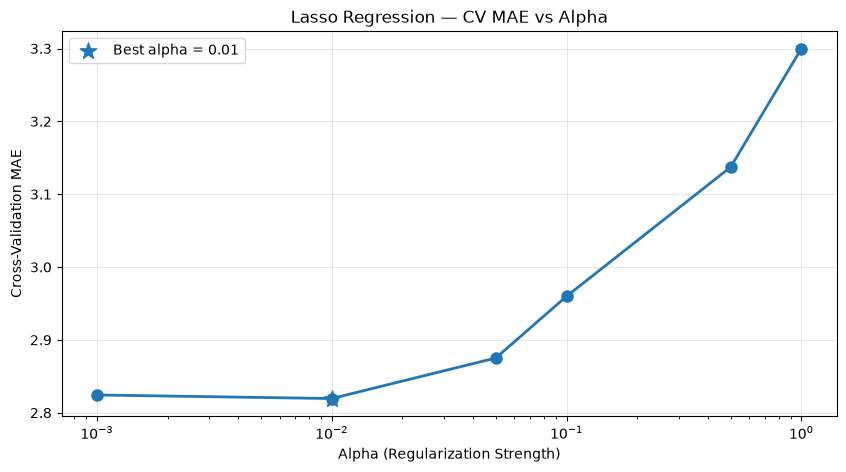

Best alpha: 0.01
Best CV MAE: 2.8195


In [28]:
# =====================================================
# E2 — Visualize Lasso Alpha Tuning
# =====================================================

import matplotlib.pyplot as plt

# Sort alpha values for plotting
plot_df = results_df.sort_values("alpha")

# Plot alpha vs cross-validation MAE
fig, ax = plt.subplots(figsize=(10, 5))

ax.semilogx(
    plot_df["alpha"],
    plot_df["CV_MAE"],
    "o-",
    linewidth=2,
    markersize=8
)

# Highlight best alpha
best_idx = plot_df["CV_MAE"].idxmin()
best_alpha = plot_df.loc[best_idx, "alpha"]
best_mae = plot_df.loc[best_idx, "CV_MAE"]

ax.scatter(
    best_alpha,
    best_mae,
    s=150,
    marker="*",
    zorder=5,
    label=f"Best alpha = {best_alpha}"
)

ax.set_xlabel("Alpha (Regularization Strength)")
ax.set_ylabel("Cross-Validation MAE")
ax.set_title("Lasso Regression — CV MAE vs Alpha")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

print(f"Best alpha: {best_alpha}")
print(f"Best CV MAE: {best_mae:.4f}")

### E2 — Lasso Hyperparameter Tuning: Graph Interpretation

**Objective:** Identify the regularization strength (`alpha`) that minimizes cross-validation Mean Absolute Error (MAE).

**Results:**
- Best tested alpha: **0.01**
- Lowest cross-validation MAE: **2.8195 wins**
- Selected features at alpha = 0.01: **32 out of 47**
- Zero coefficients: **15**

**Interpretation:**

The graph shows that increasing alpha beyond 0.01 leads to higher cross-validation MAE. At alpha = 1.0, the MAE reaches approximately 3.30, indicating poorer predictive performance.

Reducing alpha from 1.0 to 0.01 improves prediction accuracy. However, further reducing alpha to 0.001 results in a slightly higher MAE of 2.8244.

**Conclusion:**

Alpha = 0.01 provides the lowest cross-validation MAE among the six tested values, suggesting a suitable balance between regularization and predictive accuracy.

This result will be validated using the held-out testing dataset.

In [29]:
# E3 — Evaluate Tuned Lasso Regression

from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train tuned Lasso
lasso_e3 = Lasso(alpha=0.01, max_iter=100000)
lasso_e3.fit(X_lasso_train_scaled, y_lasso_train)

# Predictions
e3_train_preds = lasso_e3.predict(X_lasso_train_scaled)
e3_test_preds = lasso_e3.predict(X_lasso_test_scaled)

# Evaluation
print("E3 — Tuned Lasso (alpha=0.01)")

for name, actual, predictions in [
    ("Training", y_lasso_train, e3_train_preds),
    ("Testing", y_lasso_test, e3_test_preds)
]:
    print(f"\n{name}")
    print(f"MAE : {mean_absolute_error(actual, predictions):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(actual, predictions)):.4f}")
    print(f"R²  : {r2_score(actual, predictions):.4f}")

print("\nSelected features:",
      np.sum(np.abs(lasso_e3.coef_) > 1e-6))

E3 — Tuned Lasso (alpha=0.01)

Training
MAE : 2.6970
RMSE: 3.4097
R²  : 0.9357

Testing
MAE : 2.6883
RMSE: 3.3242
R²  : 0.9308

Selected features: 32


## E3 — Tuned Lasso Regression: Results and Interpretation

### 1. Objective

Evaluate the tuned Lasso Regression model using the best alpha identified through five-fold cross-validation.

### 2. Model Configuration

- Algorithm: Lasso Regression (L1 regularization)
- Alpha: 0.01
- Input features: 47
- Training observations: 1,129
- Testing observations: 283

### 3. Model Performance

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 2.6970 | 2.6883 |
| RMSE | 3.4097 | 3.3242 |
| R² | 0.9357 | 0.9308 |

### 4. Feature Selection

- Total features: 47
- Selected features: 32
- Zero coefficients: 15

### 5. Interpretation

The tuned Lasso model achieved a test MAE of 2.6883 wins, compared with 3.1609 for the initial Lasso model.

The lower test MAE demonstrates improved prediction accuracy following alpha tuning.

The small difference between training and testing MAE suggests no substantial generalization gap on the current data split.

L1 regularization reduced the number of active features from 47 to 32.

### 6. Comparison with Original Linear Regression

The original Linear Regression model achieved a test MAE of 2.7025, compared with 2.6883 for the tuned Lasso.

The tuned Lasso achieved a slightly lower prediction error. However, because the two models used different feature sets, the improvement cannot be attributed solely to L1 regularization.

### 7. Conclusion

Alpha = 0.01 produced the best cross-validation performance among the six alpha values tested.

The tuned Lasso model achieved good predictive accuracy while eliminating 15 feature coefficients.

The results support Lasso Regression as a competitive model for predicting MLB season wins, although further validation would be needed to establish a consistent advantage over ordinary Linear Regression.

In [30]:
# E3 — Identify Selected Lasso Features

lasso_feature_results = pd.DataFrame({
    "Feature": X_lasso_train_scaled.columns,
    "Coefficient": lasso_e3.coef_
})

# Keep nonzero coefficients
selected_features = lasso_feature_results[
    lasso_feature_results["Coefficient"].abs() > 1e-6
].copy()

# Sort by absolute coefficient
selected_features = selected_features.reindex(
    selected_features["Coefficient"].abs()
    .sort_values(ascending=False).index
)

print("Selected features:", len(selected_features))
print(selected_features.to_string(index=False))

# Check our 3 engineered features
print("\nEngineered Feature Coefficients:")

print(lasso_feature_results[
    lasso_feature_results["Feature"].isin([
        "R_per_game",
        "RA_per_game",
        "Run_Differential"
    ])
].to_string(index=False))

Selected features: 32
         Feature  Coefficient
Run_Differential     8.028141
              AB    -5.029301
          IPouts     4.961442
              SV     4.016121
              CG     3.248602
           era_1    -2.603778
               H     2.560583
               R     2.072792
     decade_1940     1.789949
     decade_1920    -1.035706
             SHO     0.803270
             BBA    -0.681355
     decade_1930     0.542127
           era_6    -0.499370
     decade_1990    -0.467919
               E    -0.462434
             SOA     0.458157
     decade_1950     0.439460
              HR     0.377545
              BB    -0.350190
               G    -0.344143
              HA    -0.336922
         mlb_rpg     0.301098
              3B     0.259071
              SB    -0.200278
              2B     0.189950
     decade_1970     0.166975
     decade_1910    -0.078806
              DP     0.059329
              SO     0.020903
           era_7    -0.017864
           era_4  

## E3 — Lasso Feature Selection and Interpretation

### Objective

Identify the features retained by the tuned Lasso Regression model (`alpha=0.01`) and examine the contribution of the three engineered features.

### Results

- Total features: 47
- Selected features: 32
- Zero coefficients: 15

### Engineered Feature Selection

| Feature | Coefficient | Status |
|---|---:|---|
| `R_per_game` | 0.0000 | Eliminated |
| `RA_per_game` | 0.0000 | Eliminated |
| `Run_Differential` | +8.0281 | Selected |

### Interpretation

The tuned Lasso model retained `Run_Differential` with a positive coefficient of 8.0281, indicating a positive conditional relationship between standardized run differential and predicted season wins.

The coefficients of `R_per_game` and `RA_per_game` were reduced to zero.

These features contain overlapping information with existing baseball statistics, which may explain why Lasso did not retain them.

### Conclusion

Lasso reduced the original 47 candidate features to 32 active features.

Among the three engineered features, only `Run_Differential` was retained.

The tuned model achieved a test MAE of **2.6883 wins**, demonstrating competitive predictive performance while reducing the number of active features.

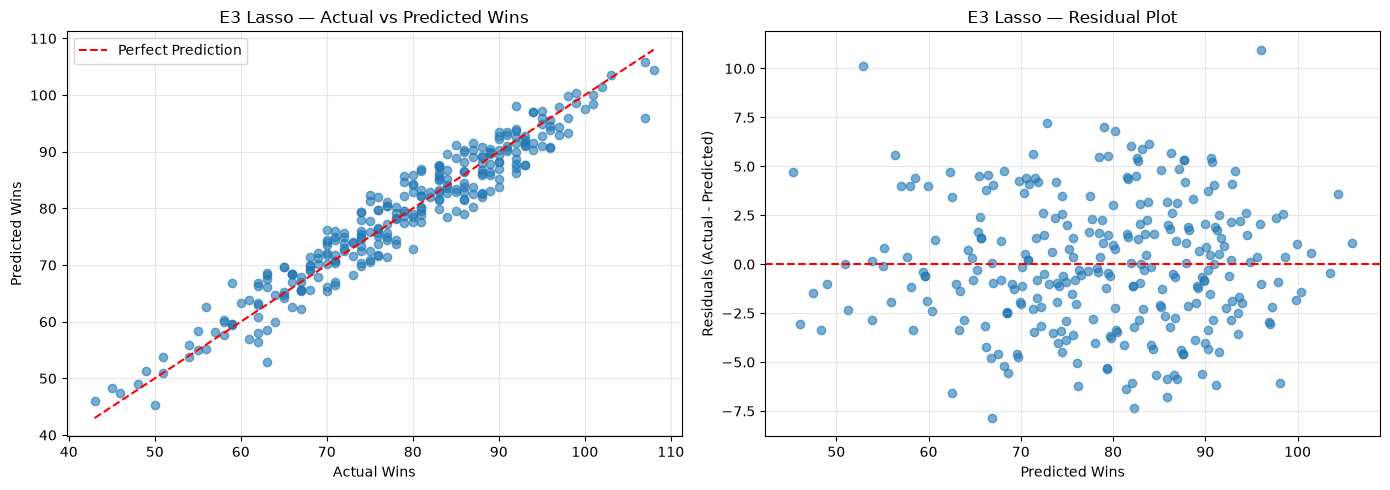

In [31]:
# =====================================================
# E3 — Tuned Lasso Regression: Model Visualization
# Alpha = 0.01
# =====================================================

import matplotlib.pyplot as plt
import numpy as np

# Calculate residuals
lasso_residuals = y_lasso_test - e3_test_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -----------------------------------------------------
# Graph 1 — Actual vs Predicted Wins
# -----------------------------------------------------

axes[0].scatter(
    y_lasso_test,
    e3_test_preds,
    alpha=0.6
)

# Perfect prediction reference line
min_val = min(y_lasso_test.min(), e3_test_preds.min())
max_val = max(y_lasso_test.max(), e3_test_preds.max())

axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

axes[0].set_title("E3 Lasso — Actual vs Predicted Wins")
axes[0].set_xlabel("Actual Wins")
axes[0].set_ylabel("Predicted Wins")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# -----------------------------------------------------
# Graph 2 — Residual Plot
# -----------------------------------------------------

axes[1].scatter(
    e3_test_preds,
    lasso_residuals,
    alpha=0.6
)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--"
)

axes[1].set_title("E3 Lasso — Residual Plot")
axes[1].set_xlabel("Predicted Wins")
axes[1].set_ylabel("Residuals (Actual - Predicted)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## E3 — Tuned Lasso Regression: Model Visualization

### Objective

Visualize the predictive performance of the tuned Lasso Regression model (`alpha=0.01`) using the held-out testing dataset.

### Graph 1 — Actual vs Predicted Wins

This scatter plot compares actual MLB season wins against predicted wins.

The diagonal reference line represents perfect predictions.

Points closer to the diagonal indicate smaller prediction errors.

### Graph 2 — Residual Plot

Residuals are calculated as:

`Residual = Actual Wins - Predicted Wins`

- Positive residual: Model underestimated actual wins.
- Negative residual: Model overestimated actual wins.
- Residual near zero: Prediction was close to the actual value.

### Model Performance

| Metric | E3 Tuned Lasso |
|---|---:|
| Alpha | 0.01 |
| Test MAE | 2.6883 |
| Test RMSE | 3.3242 |
| Test R² | 0.9308 |
| Selected features | 32 |
| Zero coefficients | 15 |

### Conclusion

The tuned Lasso model achieved a test MAE of 2.6883 wins and an R² of 0.9308.

The visualizations will be examined to determine whether predictions closely follow actual wins and whether residuals exhibit systematic patterns.

## E3 — Tuned Lasso Regression: Visualization Results

### 1. Actual vs Predicted Wins

The scatter plot shows that most predicted values are close to the diagonal reference line, indicating a strong agreement between actual and predicted MLB season wins.

Some deviations are observed, particularly among higher-win teams.

The model achieved a testing R² of 0.9308, indicating that approximately 93.08% of the variation in wins in the testing dataset was explained by the model.

### 2. Residual Analysis

The residual plot shows prediction errors distributed on both sides of zero, without an obvious strong nonlinear pattern.

Most residuals are relatively small, although a few larger errors are present.

The distribution suggests no major systematic bias is visually apparent, but the graph alone cannot confirm that all regression assumptions are satisfied.

### 3. Model Performance Summary

| Metric | Tuned Lasso (E3) |
|---|---:|
| Alpha | 0.01 |
| Training MAE | 2.6970 |
| Testing MAE | 2.6883 |
| Testing RMSE | 3.3242 |
| Testing R² | 0.9308 |
| Selected features | 32 |
| Zero coefficients | 15 |

### 4. Conclusion

The tuned Lasso Regression model demonstrates strong predictive performance on the held-out test dataset.

The close training and testing MAE values indicate no substantial generalization gap in this split.

The model also reduces the number of active features from 47 to 32 through L1 regularization.

Overall, the results support the tuned Lasso model as a suitable candidate for predicting MLB season wins.

## E3 — Kaggle Submission: Tuned Lasso Regression

### Objective
Generate predictions for the 400 unseen MLB team-season observations in `predict.csv` using the tuned Lasso Regression model.

### Model Configuration
- Model: Lasso Regression
- Alpha: 0.01
- Input features: 47 (44 original + 3 engineered)
- Selected features: 32
- Test MAE: 2.6883
- Test R²: 0.9308

### Methodology
1. Prepare the Kaggle prediction dataset with the same 47 features used during Lasso training.
2. Apply the previously fitted Lasso scaler.
3. Generate predictions using the tuned Lasso model.
4. Round predicted wins to whole numbers.
5. Save the predictions in the required Kaggle submission format.

### Submission Format
The submission contains two columns:

- `ID`: Unique team-season identifier
- `W`: Predicted number of season wins

The predicted wins must be whole numbers.

### Expected Outcome
Generate `lasso_submission.csv` containing 400 predictions, ready for upload to Kaggle.

In [32]:
# =====================================================
# E3 — Final Kaggle Submission: Tuned Lasso
# =====================================================

import numpy as np
import pandas as pd

# Step 1 — Prepare the original 44 features
X_lasso_predict = predict_df[X.columns].copy()

# Step 2 — Add the 3 engineered features
# Calculate directly from original columns
X_lasso_predict["R_per_game"] = (
    predict_df["R"] / predict_df["G"]
)

X_lasso_predict["RA_per_game"] = (
    predict_df["RA"] / predict_df["G"]
)

X_lasso_predict["Run_Differential"] = (
    predict_df["R"] - predict_df["RA"]
)

# Step 3 — Align with Lasso training features
X_lasso_predict = X_lasso_predict[
    X_lasso_train.columns
]

# Step 4 — Apply the fitted Lasso scaler
X_lasso_predict_scaled = X_lasso_predict.copy()

X_lasso_predict_scaled[lasso_scale_cols] = (
    lasso_scaler.transform(
        X_lasso_predict[lasso_scale_cols]
    )
)

# Step 5 — Predict using tuned Lasso
lasso_final_preds = lasso_e3.predict(
    X_lasso_predict_scaled
)

# Step 6 — Round predictions to whole numbers
lasso_final_preds = np.clip(
    np.rint(lasso_final_preds),
    0,
    predict_df["G"].to_numpy()
).astype(int)

# Step 7 — Create Kaggle submission
lasso_submission_df = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": lasso_final_preds
})

# Step 8 — Save to a separate file
lasso_submission_df.to_csv(
    "lasso_submission.csv",
    index=False
)

# Step 9 — Verify
print("Lasso Kaggle Submission")
print("-------------------------")
print(lasso_submission_df.head())

print("\nSubmission shape:", lasso_submission_df.shape)
print("Missing values:", lasso_submission_df.isna().sum().sum())
print("File saved: lasso_submission.csv")

Lasso Kaggle Submission
-------------------------
     ID   W
0  1649  77
1  1223  77
2   748  82
3  1735  85
4   794  79

Submission shape: (400, 2)
Missing values: 0
File saved: lasso_submission.csv


## 4. Lasso Regression — All 47 Feature Results

### 4.1 Objective

Examine how L1 regularization performs feature selection in the
tuned Lasso Regression model (`alpha=0.01`).

The model initially contained 47 features:
- 44 original features
- 3 engineered features

### 4.2 Feature Selection Summary

| Item | Result |
|---|---:|
| Total Input Features | 47 |
| Original Features | 44 |
| Engineered Features | 3 |
| Selected Features | 32 |
| Zero Coefficients | 15 |
| Best Alpha | 0.01 |
| Cross-Validation MAE | 2.8195 |
| Test MAE | 2.6883 |
| Test R² | 0.9308 |

### 4.3 Complete Feature Selection Results

The following table shows the coefficients obtained from E3 Tuned Lasso.

| No. | Feature | Lasso Coefficient | Status |
|---|---|---:|---|
| 1 | G | -0.3441 | Selected |
| 2 | R | 2.0728 | Selected |
| 3 | AB | -5.0293 | Selected |
| 4 | H | 2.5606 | Selected |
| 5 | 2B | 0.1900 | Selected |
| 6 | 3B | 0.2591 | Selected |
| 7 | HR | 0.3775 | Selected |
| 8 | BB | -0.3502 | Selected |
| 9 | SO | 0.0209 | Selected |
| 10 | SB | -0.2003 | Selected |
| 11 | RA | 0.0000 | Eliminated |
| 12 | ER | 0.0000 | Eliminated |
| 13 | ERA | 0.0000 | Eliminated |
| 14 | CG | 3.2486 | Selected |
| 15 | SHO | 0.8033 | Selected |
| 16 | SV | 4.0161 | Selected |
| 17 | IPouts | 4.9614 | Selected |
| 18 | HA | -0.3369 | Selected |
| 19 | HRA | 0.0000 | Eliminated |
| 20 | BBA | -0.6814 | Selected |
| 21 | SOA | 0.4582 | Selected |
| 22 | E | -0.4624 | Selected |
| 23 | DP | 0.0593 | Selected |
| 24 | FP | 0.0000 | Eliminated |
| 25 | mlb_rpg | 0.3011 | Selected |
| 26 | era_1 | -2.6038 | Selected |
| 27 | era_2 | 0.0000 | Eliminated |
| 28 | era_3 | 0.0000 | Eliminated |
| 29 | era_4 | 0.0051 | Selected |
| 30 | era_5 | 0.0000 | Eliminated |
| 31 | era_6 | -0.4994 | Selected |
| 32 | era_7 | -0.0179 | Selected |
| 33 | era_8 | 0.0000 | Eliminated |
| 34 | decade_1910 | -0.0788 | Selected |
| 35 | decade_1920 | -1.0357 | Selected |
| 36 | decade_1930 | 0.5421 | Selected |
| 37 | decade_1940 | 1.7899 | Selected |
| 38 | decade_1950 | 0.4395 | Selected |
| 39 | decade_1960 | 0.0000 | Eliminated |
| 40 | decade_1970 | 0.1670 | Selected |
| 41 | decade_1980 | 0.0000 | Eliminated |
| 42 | decade_1990 | -0.4679 | Selected |
| 43 | decade_2000 | 0.0000 | Eliminated |
| 44 | decade_2010 | 0.0000 | Eliminated |
| 45 | R_per_game | 0.0000 | Eliminated |
| 46 | RA_per_game | 0.0000 | Eliminated |
| 47 | Run_Differential | 8.0281 | Selected |

### 4.4 Engineered Feature Results

| Engineered Feature | Coefficient | Result |
|---|---:|---|
| R_per_game | 0.0000 | Eliminated |
| RA_per_game | 0.0000 | Eliminated |
| Run_Differential | 8.0281 | Selected |

**Interpretation:**

Among the three engineered features, only Run Differential
was retained by the tuned Lasso model.

The coefficients for Runs per Game and Runs Allowed per Game
were reduced to zero.

This may be due to overlapping information among the features.

### 4.5 Interpretation of Zero Coefficients

Lasso Regression uses L1 regularization to shrink coefficients.

A zero coefficient means that the corresponding feature does
not contribute directly to the fitted prediction equation.

However, a zero coefficient does not necessarily indicate that
a feature is unimportant in reality.

Correlated features may contain overlapping predictive information.

### 4.6 Key Findings

1. Lasso initially received 47 features.
2. L1 regularization retained 32 active features.
3. Fifteen feature coefficients were reduced to zero.
4. Run Differential was retained among the engineered features.
5. The tuned model achieved a test MAE of 2.6883 wins.
6. The testing R² was 0.9308.

### 4.7 Conclusion

The tuned Lasso Regression model (`alpha=0.01`) retained
32 of the original 47 input features.

Fifteen coefficients were reduced to zero through L1 regularization,
demonstrating automatic feature selection.

Among the engineered features, Run Differential was retained
with a positive coefficient of 8.0281.

The results demonstrate that Lasso can reduce the number
of active features while maintaining strong prediction accuracy.

Coefficient magnitudes should be interpreted cautiously because
the binary era and decade indicators were not standardized,
and several baseball statistics contain overlapping information.


In [33]:
# =====================================================
# Display MLB Teams and Predicted Season Wins
# =====================================================

# Combine team information with Lasso predictions
team_predictions = predict_df[
    ["ID", "teamID"]
].merge(
    lasso_submission_df,
    on="ID",
    how="left"
)

# Sort teams by predicted wins
team_predictions = team_predictions.sort_values(
    by="W",
    ascending=False
)

# Display top 10 predicted team-seasons
print("Top 10 Predicted MLB Team-Seasons")
print("--------------------------------")
print(team_predictions.head(10).to_string(index=False))

Top 10 Predicted MLB Team-Seasons
--------------------------------
  ID teamID   W
 398    CHN 110
1896    NY1 104
1433    NYA 103
1499    PHA 103
 680    CIN 103
  55    ARI 103
1771    PIT 102
1500    PHA 102
1402    NYA 102
1474    NYA 102


In [34]:
# =====================================================
# E3 — MLB Season Wins Prediction Results
# Tuned Lasso Regression (alpha = 0.01)
# =====================================================

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

# Step 1 — Get MLB team information from the test dataset
mlb_results = data_df.loc[
    X_lasso_test.index,
    ["yearID", "teamID", "G"]
].copy()

# Step 2 — Actual season wins
mlb_results["Actual_Wins"] = y_lasso_test.to_numpy()

# Step 3 — Predicted season wins using E3 Lasso
mlb_results["Predicted_Wins"] = np.clip(
    np.rint(e3_test_preds),
    0,
    mlb_results["G"].to_numpy()
).astype(int)

# Step 4 — Calculate prediction error
mlb_results["Absolute_Error"] = abs(
    mlb_results["Actual_Wins"] -
    mlb_results["Predicted_Wins"]
)

# Step 5 — Display results
print("MLB Season Wins — Actual vs Predicted")
print("--------------------------------------")

print(mlb_results.head(10).to_string(index=False))

# Step 6 — Evaluate original unrounded predictions
mae = mean_absolute_error(
    y_lasso_test,
    e3_test_preds
)

print(f"\nLasso Test MAE: {mae:.4f}")

MLB Season Wins — Actual vs Predicted
--------------------------------------
 yearID teamID   G  Actual_Wins  Predicted_Wins  Absolute_Error
   1966    ATL 163           85              91               6
   1986    SEA 162           67              68               1
   1976    SDN 162           73              68               5
   1931    CIN 154           58              58               0
   2002    CLE 162           74              70               4
   2003    PHI 162           86              87               1
   1951    BSN 155           76              82               6
   2004    ARI 162           51              54               3
   1989    PHI 163           67              66               1
   2009    SLN 162           91              90               1

Lasso Test MAE: 2.6883


## E3 — MLB Season Wins: Actual vs Predicted Results

### Objective
Evaluate how accurately the tuned Lasso Regression model predicts historical MLB season wins.

### Results
The model was evaluated on 283 held-out team-season observations.

- Test MAE: **2.6883 wins**
- Test RMSE: **3.3242 wins**
- Test R²: **0.9308**

### Sample Prediction Analysis

Among the first 10 testing observations:

- 5 predictions overestimated actual wins.
- 4 predictions underestimated actual wins.
- 1 prediction matched actual wins exactly.

### Interpretation
The tuned Lasso model predicts season wins with an average absolute error of approximately 2.69 games across the testing dataset.

The displayed sample includes both overestimations and underestimations, indicating that the model does not consistently predict in one direction within these observations.

However, the overall direction of prediction bias requires analysis of all 283 test observations.

### Conclusion
The tuned Lasso Regression model demonstrates strong predictive performance when estimating MLB season wins from completed season statistics.

The model achieved an R² of 0.9308 while retaining 32 active features through L1 regularization.

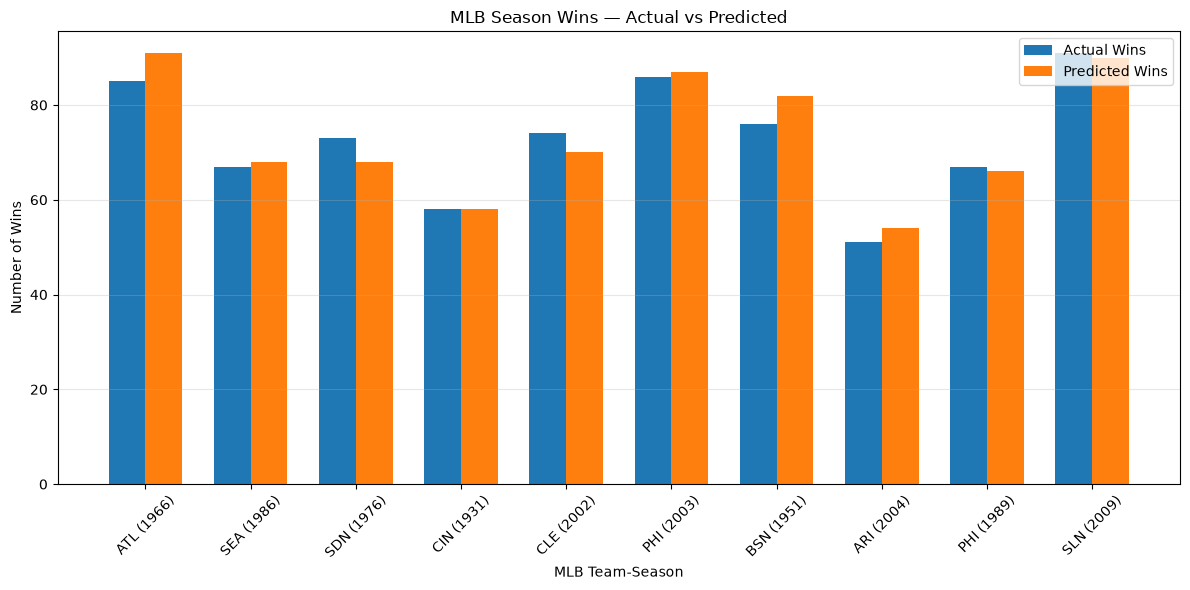

In [35]:
# =====================================================
# Chart — Actual vs Predicted MLB Season Wins
# =====================================================

import matplotlib.pyplot as plt
import numpy as np

# Copy the first 10 rows from your results
chart_df = mlb_results.head(10).copy()

# Create label: team + year
chart_df["Label"] = (
    chart_df["teamID"].astype(str) + " (" +
    chart_df["yearID"].astype(str) + ")"
)

# Plot settings
x = np.arange(len(chart_df))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    chart_df["Actual_Wins"],
    width,
    label="Actual Wins"
)

plt.bar(
    x + width/2,
    chart_df["Predicted_Wins"],
    width,
    label="Predicted Wins"
)

plt.xticks(x, chart_df["Label"], rotation=45)
plt.xlabel("MLB Team-Season")
plt.ylabel("Number of Wins")
plt.title("MLB Season Wins — Actual vs Predicted")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
# E3 — Check Lasso Prediction Bias

import numpy as np

residuals = np.asarray(y_lasso_test) - e3_test_preds

mean_residual = np.mean(residuals)

underestimated = np.sum(residuals > 0)
overestimated = np.sum(residuals < 0)

print("E3 — Lasso Prediction Bias")
print("-------------------------")
print(f"Mean Residual: {mean_residual:.4f}")
print(f"Underestimated: {underestimated}")
print(f"Overestimated : {overestimated}")

if mean_residual > 0:
    print("\nOverall: Lasso tends to UNDERESTIMATE wins.")
elif mean_residual < 0:
    print("\nOverall: Lasso tends to OVERESTIMATE wins.")
else:
    print("\nOverall: No average prediction bias.")

E3 — Lasso Prediction Bias
-------------------------
Mean Residual: -0.0663
Underestimated: 135
Overestimated : 148

Overall: Lasso tends to OVERESTIMATE wins.


## E3 — Lasso Regression: Prediction Bias Analysis

### Objective
Evaluate whether the tuned Lasso Regression model
systematically underestimates or overestimates MLB season wins.

### Results

| Metric | Result |
|---|---:|
| Mean Residual | -0.0663 |
| Underestimated Predictions | 135 |
| Overestimated Predictions | 148 |
| Total Test Observations | 283 |
| Test MAE | 2.6883 |

### Interpretation

The model slightly overestimated season wins, with a
mean residual of -0.0663 wins.

Out of 283 testing observations, 148 were overestimated
and 135 were underestimated.

The mean residual is close to zero, suggesting minimal
overall prediction bias on the testing dataset.

### Conclusion

The tuned Lasso model demonstrates approximately balanced
prediction errors with no substantial overall directional bias.

Although the model slightly overestimates season wins,
the average signed error is small relative to its
test MAE of 2.6883 wins.

E4 — Permutation Feature Importance
-----------------------------------
         Feature  Importance_Mean  Importance_STD
Run_Differential         6.330565        0.379625
          IPouts         3.790457        0.146720
              AB         3.525530        0.104624
              SV         2.409056        0.168514
              CG         1.869033        0.103320
               H         1.233471        0.072055
               R         0.863883        0.064690
             SHO         0.160405        0.039293
     decade_1940         0.085162        0.018222
           era_1         0.081072        0.023394
               G         0.051272        0.009952
             BBA         0.033183        0.032421
              HA         0.031348        0.017022
               E         0.030547        0.018734
              3B         0.026872        0.011225
     decade_1920         0.024451        0.018858
     decade_1930         0.023092        0.007428
         mlb_rpg         0.0

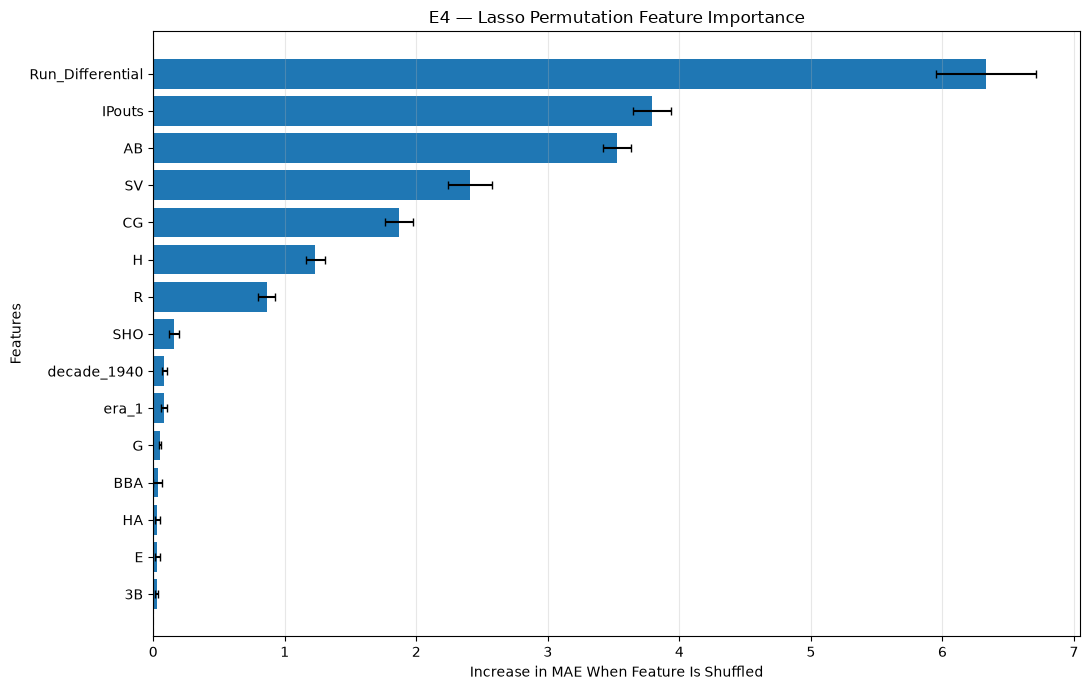

In [37]:
# =====================================================
# E4 — Permutation Feature Importance
# Tuned Lasso Regression (alpha = 0.01)
# =====================================================

from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Step 1 — Calculate permutation importance
perm_result = permutation_importance(
    lasso_e3,
    X_lasso_test_scaled,
    y_lasso_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Step 2 — Create feature importance table
perm_df = pd.DataFrame({
    "Feature": X_lasso_test_scaled.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_STD": perm_result.importances_std
})

# Step 3 — Sort by importance
perm_df = perm_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

# Step 4 — Display all 47 features
print("E4 — Permutation Feature Importance")
print("-----------------------------------")
print(perm_df.to_string(index=False))

# Step 5 — Plot top 15 features
top15 = perm_df.head(15).sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top15["Feature"],
    top15["Importance_Mean"],
    xerr=top15["Importance_STD"],
    capsize=3
)

plt.axvline(0, linestyle="--", color="gray")

plt.xlabel("Increase in MAE When Feature Is Shuffled")
plt.ylabel("Features")
plt.title("E4 — Lasso Permutation Feature Importance")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## E4 — Permutation Feature Importance

### Objective

Evaluate the importance of individual features in the tuned Lasso Regression model by measuring changes in prediction accuracy when feature values are randomly shuffled.

### Methodology

Permutation importance is calculated using the held-out testing dataset.

- Model: Tuned Lasso Regression
- Alpha: 0.01
- Input features: 47
- Evaluation metric: Mean Absolute Error (MAE)
- Permutation repetitions: 10

### Interpretation

A higher positive permutation importance indicates that shuffling a feature produces a larger increase in prediction error.

Features with importance near zero have little measured effect when shuffled individually.

Negative values indicate that shuffling slightly improved prediction accuracy.

### Limitation

Correlated features may share predictive information. Therefore, individual permutation importance values may not fully represent their contribution.

Permutation importance describes model reliance rather than causal importance.

### Conclusion

The analysis will identify which features the tuned Lasso model relies on most strongly when predicting MLB season wins.

## E4 — Permutation Feature Importance: Results and Interpretation

### 1. Objective

Evaluate how strongly the tuned Lasso Regression model relies on each feature when predicting MLB season wins.

### 2. Methodology

Permutation Feature Importance was calculated using the held-out testing dataset.

- Model: Tuned Lasso Regression
- Alpha: 0.01
- Input features: 47
- Repetitions: 10
- Evaluation metric: MAE

### 3. Top Features

| Rank | Feature | Mean Importance |
|---|---|---:|
| 1 | Run_Differential | 6.3306 |
| 2 | IPouts | 3.7905 |
| 3 | AB | 3.5255 |
| 4 | SV | 2.4091 |
| 5 | CG | 1.8690 |
| 6 | H | 1.2335 |
| 7 | R | 0.8639 |

### 4. Key Findings

**Run Differential** recorded the highest permutation importance of 6.3306, indicating that the fitted model relies strongly on this engineered feature.

Pitching outs (`IPouts`) and at bats (`AB`) were the next most influential features according to the permutation analysis.

Among the three engineered features, `R_per_game` and `RA_per_game` recorded zero permutation importance, consistent with their zero Lasso coefficients.

### 5. Limitations

Permutation importance measures changes in model prediction accuracy when individual features are shuffled.

Correlated features can distort permutation importance because shuffling may produce unrealistic combinations of observations.

Therefore, the rankings represent model reliance rather than causal relationships or independently established baseball performance drivers.

### 6. Conclusion

Permutation Feature Importance supports the E3 coefficient analysis by identifying Run Differential as the feature with the largest measured impact on prediction accuracy when shuffled.

The tuned Lasso model achieved a test MAE of 2.6883 wins while retaining 32 active features.

The analysis provides additional interpretability but does not establish that the selected features cause teams to win more games.

In [38]:
# =====================================================
# E5 — Lasso Regression: Original 44 Features
# No Feature Engineering
# =====================================================

import numpy as np

from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Step 1 — Copy original 44 features
X_train_44 = X_train.copy()
X_test_44 = X_test.copy()

print("Original features:", X_train_44.shape[1])

# Step 2 — Identify numerical features
scale_cols_44 = [
    col for col in X_train_44.columns
    if not col.startswith(("era_", "decade_"))
]

# Step 3 — Create preprocessing
preprocessor_44 = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), scale_cols_44)
    ],
    remainder="passthrough"
)

# Step 4 — Create Lasso pipeline
pipeline_44 = Pipeline([
    ("preprocessing", preprocessor_44),
    ("lasso", Lasso(max_iter=100000))
])

# Step 5 — Alpha tuning
param_grid = {
    "lasso__alpha": [
        1.0, 0.5, 0.1, 0.05, 0.01, 0.001
    ]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_44 = GridSearchCV(
    pipeline_44,
    param_grid,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Step 6 — Train model
grid_44.fit(X_train_44, y_train)

# Step 7 — Best model
lasso_44 = grid_44.best_estimator_

# Step 8 — Predictions
train_preds_44 = lasso_44.predict(X_train_44)
test_preds_44 = lasso_44.predict(X_test_44)

# Step 9 — Evaluation
print("\nE5 — Lasso Regression (44 Features)")
print("----------------------------------")

print("Best alpha:", grid_44.best_params_["lasso__alpha"])
print("Best CV MAE:", round(-grid_44.best_score_, 4))

print("\nTraining")
print("MAE :", round(mean_absolute_error(y_train, train_preds_44), 4))

print("\nTesting")
print("MAE :", round(mean_absolute_error(y_test, test_preds_44), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, test_preds_44)), 4))
print("R²  :", round(r2_score(y_test, test_preds_44), 4))

# Step 10 — Feature selection
coefs_44 = lasso_44.named_steps["lasso"].coef_

selected_44 = np.sum(np.abs(coefs_44) > 1e-6)

print("\nFeature Selection")
print("Total features   :", len(coefs_44))
print("Selected features:", selected_44)
print("Zero coefficients:", len(coefs_44) - selected_44)

Original features: 44

E5 — Lasso Regression (44 Features)
----------------------------------
Best alpha: 0.01
Best CV MAE: 2.819

Training
MAE : 2.6956

Testing
MAE : 2.6898
RMSE: 3.3248
R²  : 0.9308

Feature Selection
Total features   : 44
Selected features: 33
Zero coefficients: 11


## E5 — Lasso Regression Using 44 Original Features

### 1. Objective

The objective of E5 is to evaluate Lasso Regression using the original 44 features without additional feature engineering.

This experiment compares E5 with E3, which uses 47 features, to determine whether the three engineered features improve predictive performance.

### 2. Methodology

- **Algorithm:** Lasso Regression (L1 Regularization)
- **Input features:** 44 original features
- **Training observations:** 1,129
- **Testing observations:** 283
- **Hyperparameter tuning:** GridSearchCV
- **Cross-validation:** 5-fold
- **Best alpha:** 0.01
- **Primary evaluation metric:** Mean Absolute Error (MAE)

The same training and testing observations were used in both E3 and E5 to ensure a consistent comparison.

### 3. E5 Model Results

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 2.6956 | 2.6898 |
| RMSE | — | 3.3248 |
| R² | — | 0.9308 |

**Cross-validation MAE:** 2.8190

**Feature Selection:**

- Original features: 44
- Selected features: 33
- Zero coefficients: 11

Lasso regularization reduced 11 feature coefficients to zero, leaving 33 active features contributing to the model predictions.

### 4. Comparison: E3 vs E5

| Metric | E3 — 47 Features | E5 — 44 Features |
|---|---:|---:|
| Best Alpha | 0.01 | 0.01 |
| CV MAE | 2.8195 | 2.8190 |
| Training MAE | 2.6970 | 2.6956 |
| Testing MAE | 2.6883 | 2.6898 |
| Testing RMSE | 3.3242 | 3.3248 |
| Testing R² | 0.9308 | 0.9308 |
| Selected Features | 32 | 33 |
| Zero Coefficients | 15 | 11 |

### 5. Key Findings

**Finding 1 — Feature engineering provided negligible improvement.**

E3 achieved a testing MAE of 2.6883, compared with 2.6898 for E5.

The difference was only 0.0015 wins, indicating that the three engineered features did not meaningfully improve predictive accuracy on the testing dataset.

**Finding 2 — Original features were sufficient for comparable performance.**

E5 achieved a slightly lower cross-validation MAE of 2.8190 compared with 2.8195 for E3.

Both models produced nearly identical prediction accuracy, suggesting that the original 44 features already contained sufficient predictive information for this task.

**Finding 3 — Lasso performed automatic feature selection.**

E5 retained 33 active features and assigned zero coefficients to 11 features through L1 regularization.

This demonstrates Lasso's ability to reduce feature complexity by excluding predictors that do not contribute directly to the fitted model.

**Finding 4 — High feature importance does not necessarily mean better model performance.**

E4 identified Run Differential as the most influential feature within E3.

However, Run Differential is calculated from Runs Scored (`R`) and Runs Allowed (`RA`), which were already included in the original dataset.

Therefore, its high permutation importance did not translate into a meaningful improvement over E5.

### 6. Conclusion

The comparison demonstrates that adding engineered features does not automatically improve machine learning performance.

Although E3 achieved a marginally lower testing MAE, E5 delivered nearly identical predictive accuracy using fewer input features and slightly better cross-validation performance.

**E5 — Lasso Regression with 44 original features is selected as the preferred simpler model**, while E3 is retained as a feature-engineering comparison.

The observed differences are extremely small, and neither experiment establishes that one feature set will consistently outperform the other on future data.

E5 — Permutation Feature Importance
-----------------------------------
    Feature  Importance_Mean  Importance_STD
          R         6.919894        0.369933
         RA         4.708178        0.214511
     IPouts         3.839526        0.148085
         AB         3.551904        0.105283
         SV         2.420093        0.169055
         CG         1.881524        0.104375
          H         1.242220        0.072594
        SHO         0.161708        0.039764
decade_1940         0.087170        0.018533
      era_1         0.084328        0.023593
          G         0.053278        0.010364
         HA         0.042662        0.019303
          E         0.041665        0.021361
        BBA         0.037390        0.034102
         3B         0.026853        0.011352
decade_1930         0.024815        0.007760
decade_1920         0.024027        0.018596
    mlb_rpg         0.016801        0.010178
        SOA         0.015624        0.022587
         HR         0.012881

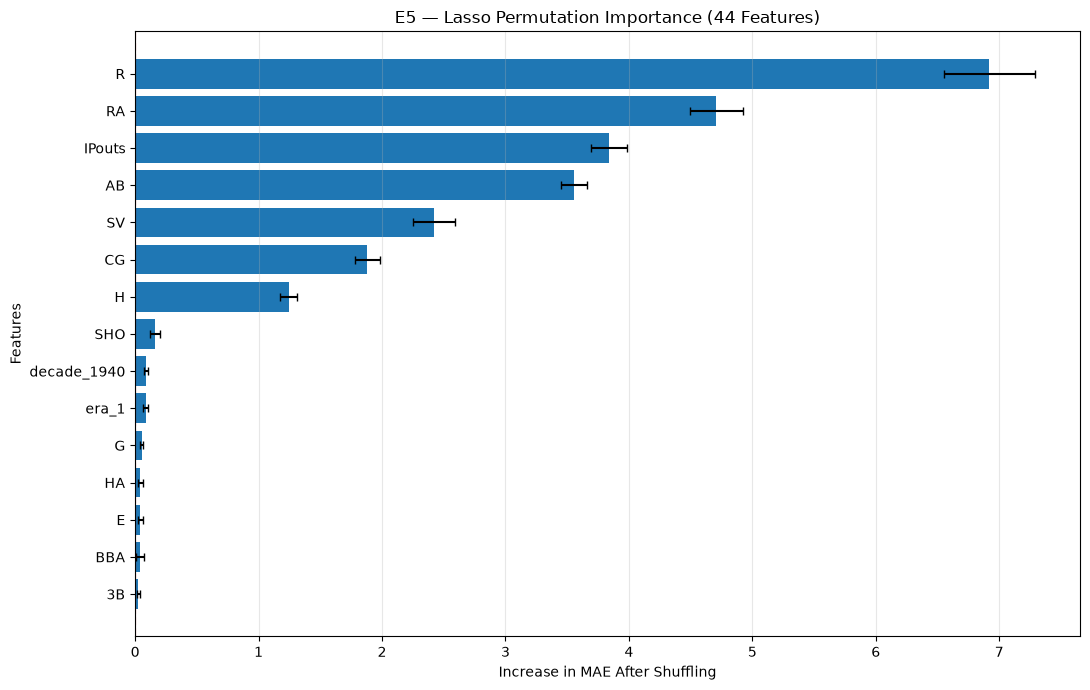

In [39]:
# =====================================================
# E5 — Permutation Feature Importance (44 Features)
# =====================================================

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Step 1 — Calculate permutation importance
perm_44 = permutation_importance(
    lasso_44,
    X_test_44,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Step 2 — Create importance table
perm_44_df = pd.DataFrame({
    "Feature": X_test_44.columns,
    "Importance_Mean": perm_44.importances_mean,
    "Importance_STD": perm_44.importances_std
}).sort_values("Importance_Mean", ascending=False)

print("E5 — Permutation Feature Importance")
print("-----------------------------------")
print(perm_44_df.to_string(index=False))

# Step 3 — Plot Top 15 Features
top15_44 = perm_44_df.head(15).sort_values(
    "Importance_Mean"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top15_44["Feature"],
    top15_44["Importance_Mean"],
    xerr=top15_44["Importance_STD"],
    capsize=3
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Increase in MAE After Shuffling")
plt.ylabel("Features")
plt.title("E5 — Lasso Permutation Importance (44 Features)")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### E5 — Permutation Feature Importance (44 Original Features)

**Objective**

To evaluate the relative importance of the 44 original features used in the tuned Lasso Regression model.

**Methodology**

Permutation Feature Importance was applied to the trained E5 Lasso pipeline using the testing dataset.

- Model: Lasso Regression
- Input features: 44
- Alpha: 0.01
- Testing MAE: 2.6898
- Permutation repetitions: 10
- Evaluation metric: Mean Absolute Error (MAE)

Each feature is randomly shuffled while the remaining features are unchanged. The resulting change in prediction error is used to estimate how strongly the fitted model relies on that feature.

**Interpretation**

- Positive importance: Shuffling increases MAE, indicating that the feature contributes to prediction accuracy.
- Near-zero importance: Shuffling has little measured effect on prediction accuracy.
- Negative importance: Shuffling slightly decreases MAE, potentially due to random variation or correlated features.

**Limitation**

Permutation importance reflects the model's reliance on individual features rather than causal effects. Correlations among baseball statistics may influence the rankings.

## E5 — Permutation Feature Importance (44 Original Features)

### 1. Objective

The objective of this analysis is to identify which of the 44 original features contribute most strongly to the predictive performance of the tuned Lasso Regression model.

The results are also compared with E4 (47 features) to evaluate how feature engineering changes model reliance on individual predictors.

### 2. Methodology

Permutation Feature Importance was applied to the trained E5 Lasso Regression model using the held-out testing dataset.

- **Model:** Lasso Regression
- **Input features:** 44 original features
- **Best alpha:** 0.01
- **Testing observations:** 283
- **Baseline testing MAE:** 2.6898 wins
- **Permutation repetitions:** 10
- **Evaluation metric:** Mean Absolute Error (MAE)

Each feature was randomly shuffled while all other features remained unchanged. Predictions were recalculated, and the resulting increase in MAE was used to estimate the model's reliance on that feature.

A larger positive importance indicates a greater deterioration in predictive accuracy when the feature is shuffled.

### 3. E5 — Top 7 Important Features

| Rank | Feature | Permutation Importance |
|---|---|---:|
| 1 | R — Runs Scored | 6.9199 |
| 2 | RA — Runs Allowed | 4.7082 |
| 3 | IPouts — Pitching Outs | 3.8395 |
| 4 | AB — At Bats | 3.5519 |
| 5 | SV — Saves | 2.4201 |
| 6 | CG — Complete Games | 1.8815 |
| 7 | H — Hits | 1.2422 |

**Interpretation:**

Runs Scored (`R`) recorded the highest permutation importance of 6.9199. Shuffling this feature increased the model's MAE from approximately 2.6898 to 9.6097 wins.

Runs Allowed (`RA`) recorded the second-highest importance of 4.7082.

These results indicate that the E5 model relies strongly on offensive scoring and defensive run prevention information when predicting total team-season wins.

### 4. Comparison — E4 (47 Features) vs E5 (44 Features)

| Feature | E4 — 47 Features | E5 — 44 Features |
|---|---:|---:|
| Run_Differential | 6.3306 | Not included |
| R — Runs Scored | 0.8639 | 6.9199 |
| RA — Runs Allowed | 0.0000 | 4.7082 |
| IPouts | 3.7905 | 3.8395 |
| AB | 3.5255 | 3.5519 |
| SV | 2.4091 | 2.4201 |
| CG | 1.8690 | 1.8815 |

### 5. Key Findings

**Finding 1 — Runs Scored and Runs Allowed are highly influential in E5.**

Without the engineered Run Differential feature, Runs Scored and Runs Allowed recorded the two highest permutation importance values.

This suggests that both variables provide important information for predicting MLB team-season wins.

**Finding 2 — Feature engineering changed the importance rankings.**

In E4, the engineered Run Differential feature recorded the highest importance.

Run Differential is calculated as:

**Run Differential = Runs Scored − Runs Allowed**

Because these variables are mathematically related, introducing Run Differential changed how Lasso distributed its coefficients and prediction reliance across the available features.

**Finding 3 — Other important features remained relatively stable.**

Pitching Outs (`IPouts`), At Bats (`AB`), Saves (`SV`), and Complete Games (`CG`) retained similar permutation importance values in both experiments.

This indicates relatively stable model reliance on these variables across the two feature sets.

**Finding 4 — Feature engineering did not meaningfully improve model accuracy.**

| Metric | E3 — 47 Features | E5 — 44 Features |
|---|---:|---:|
| Best Alpha | 0.01 | 0.01 |
| Cross-validation MAE | 2.8195 | 2.8190 |
| Testing MAE | 2.6883 | 2.6898 |
| Testing RMSE | 3.3242 | 3.3248 |
| Testing R² | 0.9308 | 0.9308 |
| Selected Features | 32 | 33 |

The difference in testing MAE was only 0.0015 wins, which is practically negligible.

Although the three engineered features changed the model's feature importance rankings, they did not produce a meaningful improvement in predictive accuracy.

### 6. Limitations

Permutation Feature Importance measures the impact of independently shuffling individual features rather than their causal influence on MLB team wins.

Because several baseball statistics are strongly correlated, independently shuffling a feature can create unrealistic combinations of observations and distort the importance estimates.

Furthermore, permutation importance was evaluated on one held-out testing dataset. The results may vary across different data splits or seasons.

Therefore, the importance rankings should be interpreted as measures of model reliance rather than causal relationships.

### 7. Conclusion

The E5 permutation importance analysis identified Runs Scored (`R`) and Runs Allowed (`RA`) as the two most influential features in the 44-feature Lasso Regression model.

The comparison with E4 demonstrated that introducing Run Differential substantially changed the importance rankings of related predictors without meaningfully improving prediction accuracy.

**E5 is preferred as the simpler model**, achieving comparable predictive performance using the original 44 features.

Overall, the findings demonstrate that feature engineering can change model interpretation without necessarily improving predictive performance.

In [40]:
# ============================================================
# STEP 9 — RETRAIN LASSO USING 33 SELECTED FEATURES
# Compare: 44 Original Features vs 33 Selected Features
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import KFold, cross_val_score

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — Retrieve 33 features selected by tuned 44 Lasso
# ------------------------------------------------------------

original_lasso = lasso_44.named_steps["lasso"]
preprocessor = lasso_44.named_steps["preprocessing"]

# Coefficients from the trained 44-feature model
coefficients = original_lasso.coef_

# Feature names in transformed column order
feature_names = preprocessor.get_feature_names_out()

# Remove transformer prefixes, e.g. "scale__R" -> "R"
feature_names = [
    name.split("__", 1)[-1]
    for name in feature_names
]

# Keep features whose coefficients are not zero
selected_features_33 = [
    name
    for name, coef in zip(feature_names, coefficients)
    if abs(coef) > 1e-6
]

print("FEATURE SELECTION")
print("-----------------")
print("Original features:", X_train_44.shape[1])
print("Selected features:", len(selected_features_33))

assert len(selected_features_33) == 33
assert all(c in X_train_44.columns for c in selected_features_33)

# ------------------------------------------------------------
# STEP 2 — Prepare selected feature dataset
# ------------------------------------------------------------

X_train_33 = X_train_44[selected_features_33].copy()
X_test_33 = X_test_44[selected_features_33].copy()

# ------------------------------------------------------------
# STEP 3 — Refit Lasso using only 33 features
# ------------------------------------------------------------

scale_cols_33 = [
    c for c in selected_features_33
    if not c.startswith(("era_", "decade_"))
]

lasso_33 = Pipeline([
    ("preprocessing", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols_33)],
        remainder="passthrough"
    )),
    ("lasso", Lasso(alpha=0.01, max_iter=100000))
])

lasso_33.fit(X_train_33, y_train)

# ------------------------------------------------------------
# STEP 4 — Predictions
# ------------------------------------------------------------

train_preds_33 = lasso_33.predict(X_train_33)
test_preds_33 = lasso_33.predict(X_test_33)

# ------------------------------------------------------------
# STEP 5 — 5-Fold CV with feature selection inside each fold
# ------------------------------------------------------------

# The 33 features above were selected from the full training set.
# For valid CV, repeat selection within each CV training fold.

cv_model_33 = Pipeline([
    ("preprocessing", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols_44)],
        remainder="passthrough"
    )),
    ("selection", SelectFromModel(
        Lasso(alpha=0.01, max_iter=100000),
        threshold=1e-6
    )),
    ("lasso", Lasso(alpha=0.01, max_iter=100000))
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_mae_33 = -cross_val_score(
    cv_model_33,
    X_train_44,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
).mean()

# ------------------------------------------------------------
# STEP 6 — Evaluation function
# ------------------------------------------------------------

def metrics(y_true, y_pred):
    return (
        mean_absolute_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        r2_score(y_true, y_pred)
    )

# Original 44-feature model
train_44 = metrics(y_train, train_preds_44)
test_44 = metrics(y_test, test_preds_44)

# Retrained 33-feature model
train_33 = metrics(y_train, train_preds_33)
test_33 = metrics(y_test, test_preds_33)

# ------------------------------------------------------------
# STEP 7 — Compare both models
# ------------------------------------------------------------

comparison_33 = pd.DataFrame({
    "Metric": [
        "Input Features",
        "CV MAE",
        "Training MAE",
        "Testing MAE",
        "Training RMSE",
        "Testing RMSE",
        "Training R2",
        "Testing R2"
    ],
    "Original Lasso (44)": [
        44,
        -grid_44.best_score_,
        train_44[0],
        test_44[0],
        train_44[1],
        test_44[1],
        train_44[2],
        test_44[2]
    ],
    "Retrained Lasso (33)": [
        len(selected_features_33),
        cv_mae_33,
        train_33[0],
        test_33[0],
        train_33[1],
        test_33[1],
        train_33[2],
        test_33[2]
    ]
})

print("\n44 vs 33 FEATURES — LASSO COMPARISON")
print("===================================")

print(comparison_33.round(4).to_string(index=False))

print("\n33-feature model evaluation")
print("---------------------------")
print(f"Training MAE : {train_33[0]:.4f}")
print(f"Testing MAE  : {test_33[0]:.4f}")
print(f"Training RMSE: {train_33[1]:.4f}")
print(f"Testing RMSE : {test_33[1]:.4f}")
print(f"Training R2  : {train_33[2]:.4f}")
print(f"Testing R2   : {test_33[2]:.4f}")
print(f"CV MAE       : {cv_mae_33:.4f}")

FEATURE SELECTION
-----------------
Original features: 44
Selected features: 33

44 vs 33 FEATURES — LASSO COMPARISON
        Metric  Original Lasso (44)  Retrained Lasso (33)
Input Features              44.0000               33.0000
        CV MAE               2.8190                2.8190
  Training MAE               2.6956                2.6957
   Testing MAE               2.6898                2.6895
 Training RMSE               3.4084                3.4085
  Testing RMSE               3.3248                3.3245
   Training R2               0.9357                0.9357
    Testing R2               0.9308                0.9308

33-feature model evaluation
---------------------------
Training MAE : 2.6957
Testing MAE  : 2.6895
Training RMSE: 3.4085
Testing RMSE : 3.3245
Training R2  : 0.9357
Testing R2   : 0.9308
CV MAE       : 2.8190


## Step 9 — Lasso Feature Selection and Retraining Analysis (44 vs 33 Features)

### 1. Objective

The objective of this experiment is to investigate whether retraining Lasso Regression using only the features selected through L1 regularization can maintain or improve predictive performance.

Two models are compared:

- **Model A:** Tuned Lasso Regression using 44 original features.
- **Model B:** Retrained Lasso Regression using 33 Lasso-selected features.

The original model identified 33 active features and eliminated 11 features by assigning their coefficients to zero.

The retrained model uses only these 33 selected features, with the same regularization parameter (alpha = 0.01).

### 2. Model Performance Comparison

| Metric | Tuned Lasso (44) | Retrained Lasso (33) |
|---|---:|---:|
| Input Features | 44 | 33 |
| Alpha | 0.01 | 0.01 |
| 5-Fold CV MAE | 2.8190 | 2.8190 |
| Training MAE | 2.6956 | 2.6957 |
| Testing MAE | 2.6898 | 2.6895 |
| Training RMSE | 3.4084 | 3.4085 |
| Testing RMSE | 3.3248 | 3.3245 |
| Training R² | 0.9357 | 0.9357 |
| Testing R² | 0.9308 | 0.9308 |

**Observation:** Both models demonstrated nearly identical predictive performance across MAE, RMSE, and R².

### 3. Feature Selection Results

The original Lasso model used 44 input features. After L1 regularization:

- 33 features retained nonzero coefficients.
- 11 features received zero coefficients.
- Approximately 25% of the original features were eliminated.

The model was subsequently retrained using only the 33 selected features.

The retrained model achieved comparable performance despite using fewer input variables.

### 4. Testing MAE Comparison

The original Lasso model achieved a testing MAE of **2.6898 wins**.

The retrained 33-feature model achieved a testing MAE of **2.6895 wins**.

The reduction in testing MAE was:

**2.6898 − 2.6895 = 0.0003 wins**

This improvement is negligible and does not demonstrate a meaningful increase in predictive accuracy.

However, the experiment confirms that reducing the number of input features did not materially affect prediction accuracy.

### 5. RMSE and R² Comparison

**RMSE**

- Original 44-feature Lasso: 3.3248
- Retrained 33-feature Lasso: 3.3245

The RMSE decreased by 0.0003 wins, indicating virtually identical sensitivity to larger prediction errors.

**R²**

Both models achieved:

- Training R²: 0.9357
- Testing R²: 0.9308

This indicates that both models explain approximately 93.08% of the variation in wins within the held-out testing dataset.

The small training–testing performance differences provide no clear evidence of substantial overfitting on the current dataset split.

### 6. Cross-Validation Assessment

Both models achieved a reported five-fold CV MAE of approximately **2.8190**.

For the 33-feature experiment, feature selection was repeated within each cross-validation training fold to avoid feature-selection leakage.

However, the retrained model was not independently tuned. It reused alpha = 0.01 from the original tuned Lasso model.

Therefore, the experiment evaluates the effect of feature selection and retraining at a fixed alpha, rather than comparing two independently optimized models.

### 7. Key Findings

**Finding 1 — Feature selection reduced input complexity.**

The number of input features decreased from 44 to 33, a reduction of 25%.

**Finding 2 — Predictive accuracy was maintained.**

The retrained model achieved nearly identical MAE, RMSE and R² values compared with the original Lasso model.

**Finding 3 — Retraining provided negligible improvement.**

The testing MAE improved by only 0.0003 wins, which is too small to establish a meaningful performance advantage.

**Finding 4 — Lasso already performed automatic feature selection.**

The original Lasso assigned zero coefficients to 11 features. Therefore, these features did not contribute to its predictions even before explicit removal.

This explains why retraining with only the 33 active features produced almost identical results.

### 8. Limitations

The comparison used a single held-out test split, and the performance differences were extremely small.

The selected features were identified using the original training dataset, while cross-validation repeated feature selection independently within each fold.

The 33-feature retrained model reused alpha = 0.01 rather than conducting a separate hyperparameter search.

Further evaluation with repeated cross-validation or independent test datasets would be necessary to determine whether any small performance differences are consistent.

### 9. Conclusion

The experiment demonstrates that **Lasso-based feature selection can reduce the number of input variables without materially compromising predictive accuracy**.

Reducing the input features from 44 to 33 produced nearly identical training, cross-validation, and testing performance.

The retrained 33-feature model achieved a testing MAE of 2.6895, RMSE of 3.3245 and R² of 0.9308.

Although the retrained model achieved marginally lower testing errors, the improvements were negligible.

**Overall, the experiment supports the effectiveness of L1 regularization for obtaining a more compact feature set while maintaining predictive performance.**

The original tuned 44-feature Lasso remains the benchmark, while the retrained 33-feature model provides evidence that explicit feature reduction does not significantly affect model accuracy.

In [41]:
# ============================================================
# STEP 10 — LASSO FEATURE SELECTION: 47 vs 32 FEATURES
# Compare Original Tuned Lasso vs Retrained Selected Features
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# STEP 1 — Load original dataset
# ------------------------------------------------------------

DATA_DIR = Path.home() / "MLB"

data_47exp = pd.read_csv(DATA_DIR / "data.csv")
predict_47exp = pd.read_csv(DATA_DIR / "predict.csv")

exclude_cols = {
    "W", "ID", "yearID", "teamID",
    "year_label", "decade_label", "win_bins"
}

shared_cols = [
    c for c in data_47exp.columns
    if c in predict_47exp.columns
]

features_44 = [
    c for c in data_47exp[shared_cols]
        .select_dtypes(include=["number", "bool"]).columns
    if c not in exclude_cols
]

# ------------------------------------------------------------
# STEP 2 — Prepare 47 features
# ------------------------------------------------------------

X_47exp = data_47exp[features_44].copy()

X_47exp["R_per_game"] = X_47exp["R"] / X_47exp["G"]
X_47exp["RA_per_game"] = X_47exp["RA"] / X_47exp["G"]
X_47exp["Run_Differential"] = X_47exp["R"] - X_47exp["RA"]

y_47exp = data_47exp["W"].copy()

X_train_47exp, X_test_47exp, y_train_47exp, y_test_47exp = (
    train_test_split(
        X_47exp,
        y_47exp,
        test_size=0.20,
        random_state=42
    )
)

assert X_47exp.shape[1] == 47

# ------------------------------------------------------------
# STEP 3 — Scale original 47 features
# ------------------------------------------------------------

scale_cols_47exp = [
    c for c in X_train_47exp.columns
    if not c.startswith(("era_", "decade_"))
]

scaler_47exp = StandardScaler()

X_train_47_scaled = X_train_47exp.copy()
X_test_47_scaled = X_test_47exp.copy()

X_train_47_scaled[scale_cols_47exp] = (
    scaler_47exp.fit_transform(X_train_47exp[scale_cols_47exp])
)

X_test_47_scaled[scale_cols_47exp] = (
    scaler_47exp.transform(X_test_47exp[scale_cols_47exp])
)

# ------------------------------------------------------------
# STEP 4 — Train original 47-feature Lasso
# ------------------------------------------------------------

lasso_47exp = Lasso(alpha=0.01, max_iter=100000)

lasso_47exp.fit(X_train_47_scaled, y_train_47exp)

# ------------------------------------------------------------
# STEP 5 — Identify the selected 32 features
# ------------------------------------------------------------

selected_features_32 = [
    feature
    for feature, coef in zip(
        X_train_47_scaled.columns,
        lasso_47exp.coef_
    )
    if abs(coef) > 1e-6
]

print("FEATURE SELECTION")
print("-----------------")
print("Original features:", X_train_47exp.shape[1])
print("Selected features:", len(selected_features_32))
print("Eliminated features:",
      X_train_47exp.shape[1] - len(selected_features_32))

assert len(selected_features_32) == 32

# ------------------------------------------------------------
# STEP 6 — Prepare selected 32-feature dataset
# ------------------------------------------------------------

X_train_32 = X_train_47exp[selected_features_32].copy()
X_test_32 = X_test_47exp[selected_features_32].copy()

# ------------------------------------------------------------
# STEP 7 — Scale selected features
# ------------------------------------------------------------

scale_cols_32 = [
    c for c in selected_features_32
    if not c.startswith(("era_", "decade_"))
]

scaler_32 = StandardScaler()

X_train_32_scaled = X_train_32.copy()
X_test_32_scaled = X_test_32.copy()

X_train_32_scaled[scale_cols_32] = (
    scaler_32.fit_transform(X_train_32[scale_cols_32])
)

X_test_32_scaled[scale_cols_32] = (
    scaler_32.transform(X_test_32[scale_cols_32])
)

# ------------------------------------------------------------
# STEP 8 — Retrain Lasso using 32 features
# ------------------------------------------------------------

lasso_32 = Lasso(
    alpha=0.01,
    max_iter=100000
)

lasso_32.fit(X_train_32_scaled, y_train_47exp)

# ------------------------------------------------------------
# STEP 9 — Generate predictions
# ------------------------------------------------------------

train_preds_47exp = lasso_47exp.predict(X_train_47_scaled)
test_preds_47exp = lasso_47exp.predict(X_test_47_scaled)

train_preds_32 = lasso_32.predict(X_train_32_scaled)
test_preds_32 = lasso_32.predict(X_test_32_scaled)

# ------------------------------------------------------------
# STEP 10 — 5-Fold Cross-Validation
# Feature selection happens INSIDE each fold
# ------------------------------------------------------------

cv_47exp = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_preprocessor = ColumnTransformer(
    [("scale", StandardScaler(), scale_cols_47exp)],
    remainder="passthrough"
)

# Original 47-feature CV model
cv_model_47 = Pipeline([
    ("preprocessing", cv_preprocessor),
    ("lasso", Lasso(alpha=0.01, max_iter=100000))
])

cv_mae_47 = -cross_val_score(
    cv_model_47,
    X_train_47exp,
    y_train_47exp,
    cv=cv_47exp,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
).mean()

# Selected-feature CV model
cv_model_32 = Pipeline([
    ("preprocessing", cv_preprocessor),
    ("selection", SelectFromModel(
        Lasso(alpha=0.01, max_iter=100000),
        threshold=1e-6
    )),
    ("lasso", Lasso(alpha=0.01, max_iter=100000))
])

cv_mae_32 = -cross_val_score(
    cv_model_32,
    X_train_47exp,
    y_train_47exp,
    cv=cv_47exp,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
).mean()

# ------------------------------------------------------------
# STEP 11 — Evaluation function
# ------------------------------------------------------------

def evaluate_47exp(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

train_47 = evaluate_47exp(y_train_47exp, train_preds_47exp)
test_47 = evaluate_47exp(y_test_47exp, test_preds_47exp)

train_32 = evaluate_47exp(y_train_47exp, train_preds_32)
test_32 = evaluate_47exp(y_test_47exp, test_preds_32)

# ------------------------------------------------------------
# STEP 12 — Final comparison table
# ------------------------------------------------------------

comparison_47_32 = pd.DataFrame({
    "Metric": [
        "Input Features",
        "CV MAE",
        "Training MAE",
        "Testing MAE",
        "Training RMSE",
        "Testing RMSE",
        "Training R2",
        "Testing R2"
    ],
    "Original Lasso (47)": [
        47,
        cv_mae_47,
        train_47["MAE"],
        test_47["MAE"],
        train_47["RMSE"],
        test_47["RMSE"],
        train_47["R2"],
        test_47["R2"]
    ],
    "Retrained Lasso (32)": [
        32,
        cv_mae_32,
        train_32["MAE"],
        test_32["MAE"],
        train_32["RMSE"],
        test_32["RMSE"],
        train_32["R2"],
        test_32["R2"]
    ]
})

print("\n47 vs 32 FEATURES — LASSO COMPARISON")
print("===================================")

print(comparison_47_32.round(4).to_string(index=False))

print("\n32-FEATURE MODEL EVALUATION")
print("---------------------------")
print(f"Training MAE : {train_32['MAE']:.4f}")
print(f"Testing MAE  : {test_32['MAE']:.4f}")
print(f"Training RMSE: {train_32['RMSE']:.4f}")
print(f"Testing RMSE : {test_32['RMSE']:.4f}")
print(f"Training R2  : {train_32['R2']:.4f}")
print(f"Testing R2   : {test_32['R2']:.4f}")
print(f"CV MAE       : {cv_mae_32:.4f}")

print("\nSELECTED 32 FEATURES")
print("--------------------")
print(selected_features_32)

FEATURE SELECTION
-----------------
Original features: 47
Selected features: 32
Eliminated features: 15

47 vs 32 FEATURES — LASSO COMPARISON
        Metric  Original Lasso (47)  Retrained Lasso (32)
Input Features              47.0000               32.0000
        CV MAE               2.8195                2.8194
  Training MAE               2.6970                2.6971
   Testing MAE               2.6883                2.6883
 Training RMSE               3.4097                3.4098
  Testing RMSE               3.3242                3.3243
   Training R2               0.9357                0.9357
    Testing R2               0.9308                0.9308

32-FEATURE MODEL EVALUATION
---------------------------
Training MAE : 2.6971
Testing MAE  : 2.6883
Training RMSE: 3.4098
Testing RMSE : 3.3243
Training R2  : 0.9357
Testing R2   : 0.9308
CV MAE       : 2.8194

SELECTED 32 FEATURES
--------------------
['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB', 'CG', 'SHO', 'SV', 'IPou

## Step 10 — Lasso Feature Selection and Retraining Analysis (47 vs 32 Features)

### 1. Objective

The objective of this experiment is to evaluate whether retraining Lasso Regression using only the 32 features selected through L1 regularization can maintain or improve predictive accuracy.

Two models were compared:

- **Model A:** Original tuned Lasso Regression using 47 features, including three engineered features.
- **Model B:** Retrained Lasso Regression using 32 Lasso-selected features.

Both models used alpha = 0.01. This parameter was originally selected through five-fold cross-validation for the 47-feature model and reused for the 32-feature model.

### 2. Feature Selection Results

The original Lasso model was trained using 47 input features.

After applying L1 regularization:

- **Original features:** 47
- **Selected features:** 32
- **Eliminated features:** 15
- **Feature reduction:** 31.9%
- **Regularization parameter (alpha):** 0.01

Lasso automatically assigned zero coefficients to 15 features, meaning these features did not directly contribute to the fitted model's predictions.

The model was subsequently retrained using only the 32 selected features.

### 3. Model Performance Comparison

| Metric | Original Lasso (47) | Retrained Lasso (32) |
|---|---:|---:|
| Input Features | 47 | 32 |
| Alpha | 0.01 | 0.01 |
| 5-Fold CV MAE | 2.8195 | 2.8194 |
| Training MAE | 2.6970 | 2.6971 |
| Testing MAE | 2.6883 | 2.6883 |
| Training RMSE | 3.4097 | 3.4098 |
| Testing RMSE | 3.3242 | 3.3243 |
| Training R² | 0.9357 | 0.9357 |
| Testing R² | 0.9308 | 0.9308 |

**Observation:** Both models achieved nearly identical predictive performance despite the reduction from 47 to 32 input features.

### 4. MAE Analysis

The original 47-feature Lasso model achieved:

- Training MAE: 2.6970
- Testing MAE: 2.6883

The retrained 32-feature model achieved:

- Training MAE: 2.6971
- Testing MAE: 2.6883

The testing MAE remained identical when rounded to four decimal places.

This indicates that eliminating 15 zero-coefficient features did not materially affect the model's average prediction error.

The retrained model preserved predictive accuracy while using fewer input variables.

### 5. RMSE Analysis

The original Lasso model achieved a testing RMSE of **3.3242 wins**, compared with **3.3243 wins** for the retrained model.

The difference of 0.0001 wins is negligible.

This indicates that retraining the model using only the selected features did not materially change its sensitivity to larger prediction errors.

### 6. R² Analysis

Both models achieved:

- **Training R²:** 0.9357
- **Testing R²:** 0.9308

The testing R² of 0.9308 indicates that the models explain approximately 93.08% of the variation in wins within the held-out testing dataset.

The similarity between training and testing R² suggests that neither model exhibited substantial deterioration in explanatory performance on the test split.

However, a small performance gap does not guarantee generalization to future MLB seasons.

### 7. Cross-Validation Analysis

The five-fold cross-validation results were:

| Model | CV MAE |
|---|---:|
| Original Lasso (47) | 2.8195 |
| Retrained Lasso (32) | 2.8194 |

The retrained model achieved a marginally lower CV MAE of 2.8194.

The difference of 0.0001 wins is negligible and does not establish a meaningful improvement in predictive performance.

For the selected-feature cross-validation procedure, feature selection was repeated independently within each training fold to avoid validation leakage. Therefore, the number and identity of selected features could differ across folds.

**Important methodological distinction:** The 32-feature model was retrained using alpha = 0.01, inherited from the original 47-feature model. It was not independently tuned through a new hyperparameter search.

### 8. Analysis of Selected Features

The 32 selected features were:

**Season and offensive statistics**

- G, R, AB, H, 2B, 3B, HR, BB, SO, SB

**Pitching and defensive statistics**

- CG, SHO, SV, IPouts, HA, BBA, SOA, E, DP

**League context**

- mlb_rpg

**Era indicators**

- era_1, era_4, era_6, era_7

**Decade indicators**

- decade_1910, decade_1920, decade_1930, decade_1940, decade_1950, decade_1970, decade_1990

**Engineered feature**

- Run_Differential

Among the three engineered features, only **Run_Differential** retained a nonzero coefficient.

The two other engineered features, R_per_game and RA_per_game, received zero coefficients.

Run_Differential represents:

**Run_Differential = Runs Scored − Runs Allowed**

This feature captures the balance between offensive production and defensive performance.

However, because Run_Differential is mathematically derived from R and RA, it does not introduce independent information. Its selection reflects how Lasso distributes coefficients among correlated predictors, rather than establishing that it is inherently more important.

### 9. Comparison with the 44-to-33 Feature Experiment

Both feature-selection experiments produced similar findings.

| Metric | Original 44 | Selected 33 | Original 47 | Selected 32 |
|---|---:|---:|---:|---:|
| Input Features | 44 | 33 | 47 | 32 |
| CV MAE | 2.8190 | 2.8190 | 2.8195 | 2.8194 |
| Training MAE | 2.6956 | 2.6957 | 2.6970 | 2.6971 |
| Testing MAE | 2.6898 | 2.6895 | 2.6883 | 2.6883 |
| Testing RMSE | 3.3248 | 3.3245 | 3.3242 | 3.3243 |
| Testing R² | 0.9308 | 0.9308 | 0.9308 | 0.9308 |

The 44-feature experiment reduced the number of input features by 25%.

The 47-feature experiment reduced the number of input features by approximately 31.9%.

In both experiments, predictive accuracy remained essentially unchanged after retraining.

### 10. Key Findings

**Finding 1 — Feature selection reduced model inputs.**

Lasso reduced the feature count from 47 to 32, eliminating approximately 31.9% of the original inputs.

**Finding 2 — Predictive accuracy was maintained.**

The retrained 32-feature model achieved nearly identical training, cross-validation and testing results compared with the original 47-feature model.

**Finding 3 — Retraining did not meaningfully improve accuracy.**

The differences in MAE, RMSE and R² were negligible.

**Finding 4 — Run Differential was the only engineered feature retained.**

Among the three engineered features, Run_Differential received a nonzero coefficient, while R_per_game and RA_per_game were eliminated by Lasso.

**Finding 5 — Feature selection did not substantially affect generalization.**

Training and testing performance remained similar, with no clear evidence of substantial overfitting on the current dataset split.

### 11. Limitations

The analysis used a single 80/20 train-test split with random_state = 42.

Although cross-validation was performed, the final results may depend on the particular observations assigned to training and testing.

The retrained model reused alpha = 0.01 rather than being independently tuned.

Furthermore, selected features may differ under alternative samples, alpha values or cross-validation partitions.

The results therefore demonstrate performance stability under the current experimental configuration rather than proving that 32 features are universally optimal.

### 12. Conclusion

The 47-feature Lasso Regression model selected 32 active features through L1 regularization, eliminating 15 features and reducing the input feature count by approximately 31.9%.

After retraining using only the selected features, the model achieved:

- **CV MAE:** 2.8194
- **Training MAE:** 2.6971
- **Testing MAE:** 2.6883
- **Training RMSE:** 3.4098
- **Testing RMSE:** 3.3243
- **Training R²:** 0.9357
- **Testing R²:** 0.9308

These results were almost identical to those of the original 47-feature model.

**Overall, the experiment demonstrates that Lasso-based feature selection reduced the number of input variables without materially compromising predictive performance.**

The findings support the use of L1 regularization as a feature-selection technique. However, retraining on the selected subset did not produce a meaningful improvement in prediction accuracy.

The original tuned 47-feature model remains the benchmark for this experiment, while the retrained 32-feature model provides a more compact alternative with comparable performance.

In [42]:
# ============================================================
# Investigate Why Lasso Selected Certain Engineered Features
# ============================================================

import pandas as pd
import numpy as np

features_to_check = [
    "R",
    "RA",
    "G",
    "R_per_game",
    "RA_per_game",
    "Run_Differential"
]

# Retrieve coefficients from the trained 47-feature Lasso
coef_df = pd.DataFrame({
    "Feature": X_train_47_scaled.columns,
    "Coefficient": lasso_47exp.coef_
})

# Examine the selected features
result = coef_df[
    coef_df["Feature"].isin(features_to_check)
].copy()

result["Status"] = np.where(
    result["Coefficient"].abs() > 1e-6,
    "SELECTED",
    "ELIMINATED"
)

print("LASSO FEATURE SELECTION ANALYSIS")
print("--------------------------------")
print(result.to_string(index=False))

# Check correlations between features
print("\nFEATURE CORRELATION MATRIX")
print("--------------------------")

correlation = X_train_47exp[
    features_to_check
].corr()

print(correlation.round(3).to_string())

LASSO FEATURE SELECTION ANALYSIS
--------------------------------
         Feature  Coefficient     Status
               G    -0.344143   SELECTED
               R     2.072792   SELECTED
              RA    -0.000000 ELIMINATED
      R_per_game     0.000000 ELIMINATED
     RA_per_game    -0.000000 ELIMINATED
Run_Differential     8.028141   SELECTED

FEATURE CORRELATION MATRIX
--------------------------
                      R     RA      G  R_per_game  RA_per_game  Run_Differential
R                 1.000  0.302  0.118       0.987        0.284             0.593
RA                0.302  1.000  0.135       0.280        0.987            -0.589
G                 0.118  0.135  1.000      -0.040       -0.023            -0.014
R_per_game        0.987  0.280 -0.040       1.000        0.287             0.601
RA_per_game       0.284  0.987 -0.023       0.287        1.000            -0.593
Run_Differential  0.593 -0.589 -0.014       0.601       -0.593             1.000


## Step 11 — Feature Engineering, Correlation and Lasso Feature Selection Analysis

### 1. Objective

The objective of this analysis is to investigate why adding three engineered features did not significantly improve Lasso Regression performance in the Moneyball prediction project.

The analysis examines:

- Relationships between original and engineered baseball statistics.
- Feature redundancy and multicollinearity.
- How L1 regularization affects feature selection.
- Why Run Differential was selected while Runs per Game and Runs Allowed per Game were eliminated.
- The effect of feature engineering on predictive accuracy.

### 2. Engineered Features

Three features were created from existing baseball statistics.

| Engineered Feature | Formula | Purpose |
|---|---|---|
| Runs per Game | `R / G` | Measures average offensive production per game |
| Runs Allowed per Game | `RA / G` | Measures average runs conceded per game |
| Run Differential | `R - RA` | Measures the difference between runs scored and allowed |

Where:

- **R:** Total runs scored.
- **RA:** Total runs allowed.
- **G:** Total games played.

All three features are relevant to baseball performance. However, they are calculated from existing predictors rather than independent new data.

### 3. Correlation Analysis

Pearson correlation was calculated to examine relationships between the original and engineered features.

| Feature Pair | Correlation | Interpretation |
|---|---:|---|
| R vs R_per_game | 0.987 | Very strong positive correlation |
| RA vs RA_per_game | 0.987 | Very strong positive correlation |
| R vs Run_Differential | 0.593 | Moderate positive correlation |
| RA vs Run_Differential | -0.589 | Moderate negative correlation |
| G vs Run_Differential | -0.014 | Negligible linear correlation |

**Key observation:**

Runs Scored (`R`) and Runs per Game (`R_per_game`) have a correlation of 0.987.

Similarly, Runs Allowed (`RA`) and Runs Allowed per Game (`RA_per_game`) have a correlation of 0.987.

These extremely high correlations indicate that the paired variables contain highly overlapping information.

Because most seasons contain similar numbers of games, converting season totals into per-game averages does not substantially change the statistical information available to the model.

### 4. Lasso Coefficient and Feature Selection Analysis

The tuned 47-feature Lasso model used:

**Alpha = 0.01**

The following coefficients were obtained:

| Feature | Coefficient | Selection Status |
|---|---:|---|
| G | -0.344143 | Selected |
| R | +2.072792 | Selected |
| RA | 0.000000 | Eliminated |
| R_per_game | 0.000000 | Eliminated |
| RA_per_game | 0.000000 | Eliminated |
| Run_Differential | +8.028141 | Selected |

The results show that Lasso retained Runs Scored and Run Differential but assigned zero coefficients to Runs Allowed, Runs per Game and Runs Allowed per Game.

The numerical coefficients were estimated using standardized features. Therefore, their magnitudes should not be interpreted as the number of additional wins associated with a one-unit increase in the original baseball statistics.

Furthermore, coefficient selection reflects conditional predictive relationships rather than causal effects.

### 5. Why Were Runs per Game and Runs Allowed per Game Eliminated?

Lasso Regression uses L1 regularization, which penalizes the absolute values of model coefficients.

This penalty encourages some coefficients to become exactly zero.

When two predictors contain highly similar information, Lasso may retain one predictor and eliminate another to produce a sparser model.

For example:

**R_per_game = R / G**

Because R and R_per_game have a correlation of 0.987, retaining both may provide limited additional predictive benefit.

Similarly:

**RA_per_game = RA / G**

The correlation between RA and RA_per_game is also 0.987.

This helps explain why Lasso assigned zero coefficients to both engineered per-game features.

**Important:** A zero coefficient does not mean a statistic is unimportant in baseball. It means the fitted Lasso model did not require that predictor's separate contribution under the current regularization settings.

### 6. Why Was Run Differential Selected?

Run Differential is calculated as:

**Run Differential = R - RA**

A positive value indicates that a team scored more runs than it allowed over the season.

For example:

- Runs Scored = 800
- Runs Allowed = 700
- Run Differential = +100

A positive Run Differential generally reflects favorable team performance.

In the tuned Lasso model, Run Differential received a positive coefficient of +8.028141, while Runs Allowed received a zero coefficient.

This suggests that Run Differential provided a useful representation of the relationship between offensive production, defensive performance and season wins.

However, Run Differential is mathematically determined by R and RA.

Therefore, it does not introduce independent information when both original statistics are already included.

Because these predictors are linearly dependent, Lasso can distribute their combined predictive effects across different coefficients.

**Consequently, the selection of Run Differential should not be interpreted as proof that it provides entirely new predictive information.**

### 7. Understanding Feature Redundancy and Multicollinearity

**Feature redundancy** occurs when multiple predictors provide overlapping information.

**Multicollinearity** occurs when predictors are strongly linearly related.

Two forms of redundancy are present in this experiment.

**A. High correlation**

- R and R_per_game: 0.987
- RA and RA_per_game: 0.987

These pairs provide highly similar information.

**B. Exact mathematical dependency**

Run Differential is calculated directly from R and RA:

**Run_Differential = R - RA**

Although Run Differential has only moderate individual correlations with R and RA, it is completely determined by their combination.

This demonstrates why correlation coefficients alone cannot identify every form of feature redundancy.

Lasso's L1 regularization encourages coefficient sparsity, helping the model retain a compact set of predictors when substantial overlap exists.

### 8. Impact on Model Performance

The original and engineered Lasso models produced the following results.

| Metric | Original 44 Features | Engineered 47 Features | Selected 32 Features |
|---|---:|---:|---:|
| Input Features | 44 | 47 | 32 |
| Alpha | 0.01 | 0.01 | 0.01 |
| CV MAE | 2.8190 | 2.8195 | 2.8194 |
| Testing MAE | 2.6898 | 2.6883 | 2.6883 |
| Testing RMSE | 3.3248 | 3.3242 | 3.3243 |
| Testing R² | 0.9308 | 0.9308 | 0.9308 |

Adding three engineered features reduced testing MAE from 2.6898 to 2.6883.

The improvement was:

**2.6898 - 2.6883 = 0.0015 wins**

This improvement is negligible.

The CV MAE increased slightly from 2.8190 to 2.8195, suggesting that the engineered model did not consistently outperform the original model under cross-validation.

The retrained 32-feature model also produced nearly identical prediction accuracy.

These findings indicate that the engineered features provided limited incremental predictive value to the existing linear Lasso model.

### 9. Implications for Feature Engineering

The experiment provides several important insights.

**Finding 1 — More features do not necessarily improve prediction accuracy.**

Increasing the input count from 44 to 47 did not produce a meaningful reduction in prediction error.

**Finding 2 — Domain-relevant features may still be redundant.**

Runs per Game, Runs Allowed per Game and Run Differential are meaningful baseball statistics, but their information overlaps with the original predictors.

**Finding 3 — Lasso can automatically eliminate redundant predictors.**

L1 regularization eliminated 15 features from the 47-feature model, leaving 32 active predictors.

**Finding 4 — Run Differential was retained as an alternative representation.**

Although Run Differential does not introduce independent information, Lasso retained it as part of its fitted predictive equation.

**Finding 5 — Feature reduction preserved model accuracy.**

Retraining the model with only 32 selected features maintained almost identical MAE, RMSE and R² values.

### 10. Recommendation for Further Experimentation

Future experiments could evaluate baseball-specific nonlinear features rather than relying only on linear combinations or highly correlated ratios.

One possible candidate is **Pythagorean Expected Wins**:

**Expected Wins = G × R² / (R² + RA²)**

This formula estimates a team's expected season wins from its runs scored and runs allowed.

Unlike the simple Run Differential formula, it introduces a nonlinear relationship that standard linear Lasso cannot directly construct from the original inputs.

A new experiment could compare:

- 44 original features.
- 47 features with the existing three engineered variables.
- 48 features including Pythagorean Expected Wins.

All preprocessing and model tuning should be conducted using training data only, with cross-validation used to assess whether the additional feature improves predictive accuracy.

Any improvement would need to be demonstrated empirically rather than assumed.

### 11. Limitations

The conclusions are based on the current historical MLB dataset, an 80/20 random train-test split and the evaluated Lasso regularization settings.

Feature correlations and coefficients may differ under other datasets, training partitions or alpha values.

Highly correlated predictors can also produce unstable coefficient selections, even when their combined predictions remain relatively stable.

Therefore, the selected features should not automatically be interpreted as the most important causal drivers of baseball wins.

The evaluation also relies on full-season statistics. Consequently, the results demonstrate the ability to estimate wins from season-level performance rather than validate predictions made before the season begins.

### 12. Conclusion

The feature engineering analysis explains why adding three new baseball statistics did not materially improve Lasso Regression performance.

Runs per Game and Runs Allowed per Game exhibited extremely high correlations of 0.987 with their corresponding original season totals, indicating substantial information overlap.

Lasso eliminated both per-game engineered features while retaining Run Differential.

Although Run Differential was selected, it is mathematically derived from Runs Scored and Runs Allowed and therefore does not introduce independent predictive information.

The engineered 47-feature model achieved a testing MAE of 2.6883 compared with 2.6898 for the original 44-feature model, representing a negligible improvement of 0.0015 wins.

**Overall, the findings demonstrate that meaningful feature engineering requires consideration of both domain knowledge and incremental predictive information.**

The results support the effectiveness of L1 regularization in handling overlapping predictors and reducing model complexity without materially compromising prediction accuracy.

Future experiments may investigate nonlinear baseball-specific features to determine whether alternative transformations can provide additional predictive value.

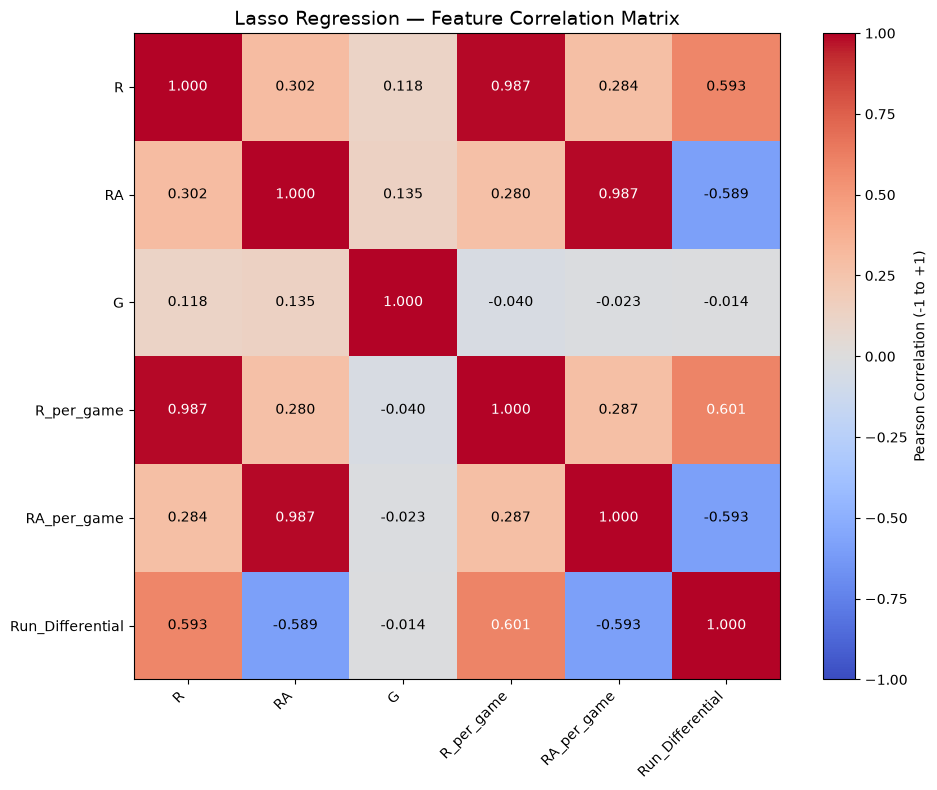

In [43]:
# ============================================================
# STEP 11A — CORRELATION MATRIX HEATMAP
# Original and Engineered Baseball Features
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Load original data
df = pd.read_csv(Path.home() / "MLB" / "data.csv")

# Select original baseball statistics
features = [
    "R", "RA", "G",
    "R_per_game",
    "RA_per_game",
    "Run_Differential"
]

# Recreate the three engineered features
df["R_per_game"] = df["R"] / df["G"]
df["RA_per_game"] = df["RA"] / df["G"]
df["Run_Differential"] = df["R"] - df["RA"]

# Use same training split as Lasso experiments
train_df, _ = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

# Calculate Pearson correlation matrix
corr_matrix = train_df[features].corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 8))

heatmap = ax.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))

ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticklabels(features)

# Show correlation values in each cell
for i in range(len(features)):
    for j in range(len(features)):
        value = corr_matrix.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.3f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.6 else "black"
        )

plt.colorbar(
    heatmap,
    ax=ax,
    label="Pearson Correlation (-1 to +1)"
)

plt.title(
    "Lasso Regression — Feature Correlation Matrix",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [44]:
# ============================================================
# STEP 12 — PYTHAGOREAN EXPECTED WINS
# New Feature Engineering Experiment
# ============================================================

# Copy existing 47-feature datasets
X_train_48 = X_train_47exp.copy()
X_test_48 = X_test_47exp.copy()

# Add the new nonlinear feature
for df in [X_train_48, X_test_48]:

    df["Pythagorean_Expected_Wins"] = (
        df["G"] * (df["R"] ** 2)
        / ((df["R"] ** 2) + (df["RA"] ** 2))
    )

# Verify
print("Original features:", X_train_47exp.shape[1])
print("New features:", X_train_48.shape[1])

print("\nExample Expected Wins:")
print(
    X_train_48[
        ["R", "RA", "G", "Pythagorean_Expected_Wins"]
    ].head()
)

Original features: 47
New features: 48

Example Expected Wins:
       R   RA    G  Pythagorean_Expected_Wins
629  505  627  162                  63.741102
439  749  801  162                  75.571271
485  511  559  156                  71.015924
48   768  705  162                  87.916066
155  765  726  163                  85.760666


In [45]:
# ============================================================
# STEP 13 — TUNED LASSO REGRESSION (48 FEATURES)
# Feature: Pythagorean Expected Wins
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — Identify features for scaling
# ------------------------------------------------------------

scale_cols_48 = [
    c for c in X_train_48.columns
    if not c.startswith(("era_", "decade_"))
]

# ------------------------------------------------------------
# STEP 2 — Build Lasso pipeline
# ------------------------------------------------------------

pipeline_48 = Pipeline([
    ("preprocessing", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols_48)],
        remainder="passthrough"
    )),
    ("lasso", Lasso(max_iter=100000))
])

# ------------------------------------------------------------
# STEP 3 — Alpha tuning with 5-fold CV
# ------------------------------------------------------------

alpha_grid_48 = {
    "lasso__alpha": [
        1.0, 0.5, 0.1, 0.05, 0.01, 0.001
    ]
}

cv_48 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_48 = GridSearchCV(
    pipeline_48,
    alpha_grid_48,
    cv=cv_48,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_48.fit(X_train_48, y_train_47exp)

# ------------------------------------------------------------
# STEP 4 — Best trained model
# ------------------------------------------------------------

lasso_48 = grid_48.best_estimator_

train_preds_48 = lasso_48.predict(X_train_48)
test_preds_48 = lasso_48.predict(X_test_48)

# ------------------------------------------------------------
# STEP 5 — Calculate training and testing metrics
# ------------------------------------------------------------

train_mae_48 = mean_absolute_error(
    y_train_47exp, train_preds_48
)

test_mae_48 = mean_absolute_error(
    y_test_47exp, test_preds_48
)

train_rmse_48 = np.sqrt(mean_squared_error(
    y_train_47exp, train_preds_48
))

test_rmse_48 = np.sqrt(mean_squared_error(
    y_test_47exp, test_preds_48
))

train_r2_48 = r2_score(
    y_train_47exp, train_preds_48
)

test_r2_48 = r2_score(
    y_test_47exp, test_preds_48
)

cv_mae_48 = -grid_48.best_score_

# ------------------------------------------------------------
# STEP 6 — Feature selection
# ------------------------------------------------------------

coefficients_48 = lasso_48.named_steps["lasso"].coef_

selected_count_48 = np.sum(
    np.abs(coefficients_48) > 1e-6
)

feature_names_48 = [
    name.split("__", 1)[-1]
    for name in lasso_48.named_steps[
        "preprocessing"
    ].get_feature_names_out()
]

coef_table_48 = pd.DataFrame({
    "Feature": feature_names_48,
    "Coefficient": coefficients_48
})

pythagorean_coef = coef_table_48.loc[
    coef_table_48["Feature"] == "Pythagorean_Expected_Wins",
    "Coefficient"
].iloc[0]

# ------------------------------------------------------------
# STEP 7 — Display all results
# ------------------------------------------------------------

print("E6 — TUNED LASSO (48 FEATURES)")
print("================================")

print("Best Alpha:", grid_48.best_params_["lasso__alpha"])
print(f"CV MAE: {cv_mae_48:.4f}")

print("\nTRAINING PERFORMANCE")
print("--------------------")
print(f"MAE : {train_mae_48:.4f}")
print(f"RMSE: {train_rmse_48:.4f}")
print(f"R²  : {train_r2_48:.4f}")

print("\nTESTING PERFORMANCE")
print("--------------------")
print(f"MAE : {test_mae_48:.4f}")
print(f"RMSE: {test_rmse_48:.4f}")
print(f"R²  : {test_r2_48:.4f}")

print("\nFEATURE SELECTION")
print("--------------------")
print("Original features:", X_train_48.shape[1])
print("Selected features:", selected_count_48)
print("Eliminated features:",
      X_train_48.shape[1] - selected_count_48)

print("\nPYTHAGOREAN EXPECTED WINS")
print("-------------------------")
print(f"Coefficient: {pythagorean_coef:.6f}")

if abs(pythagorean_coef) > 1e-6:
    print("Status: SELECTED")
else:
    print("Status: ELIMINATED")

# ------------------------------------------------------------
# STEP 8 — Compare 44, 47 and 48 features
# ------------------------------------------------------------

comparison_48 = pd.DataFrame({
    "Model": [
        "Lasso 44 Features",
        "Lasso 47 Features",
        "Lasso 48 Features"
    ],
    "CV MAE": [
        2.8190,
        2.8195,
        cv_mae_48
    ],
    "Test MAE": [
        2.6898,
        2.6883,
        test_mae_48
    ],
    "Test RMSE": [
        3.3248,
        3.3242,
        test_rmse_48
    ],
    "Test R2": [
        0.9308,
        0.9308,
        test_r2_48
    ]
})

print("\nFINAL MODEL COMPARISON")
print("======================")
print(comparison_48.round(4).to_string(index=False))

E6 — TUNED LASSO (48 FEATURES)
Best Alpha: 0.01
CV MAE: 2.7628

TRAINING PERFORMANCE
--------------------
MAE : 2.6485
RMSE: 3.3283
R²  : 0.9387

TESTING PERFORMANCE
--------------------
MAE : 2.6904
RMSE: 3.3029
R²  : 0.9317

FEATURE SELECTION
--------------------
Original features: 48
Selected features: 32
Eliminated features: 16

PYTHAGOREAN EXPECTED WINS
-------------------------
Coefficient: 6.410727
Status: SELECTED

FINAL MODEL COMPARISON
            Model  CV MAE  Test MAE  Test RMSE  Test R2
Lasso 44 Features  2.8190    2.6898     3.3248   0.9308
Lasso 47 Features  2.8195    2.6883     3.3242   0.9308
Lasso 48 Features  2.7628    2.6904     3.3029   0.9317


## Step 13 — Lasso Regression with Pythagorean Expected Wins (48 Features)

### 1. Objective

The objective of this experiment is to investigate whether adding a baseball-specific nonlinear engineered feature, **Pythagorean Expected Wins**, improves Lasso Regression performance.

Three feature configurations were compared:

- **Model A:** 44 original baseball features.
- **Model B:** 47 features, including three engineered features.
- **Model C:** 48 features, including Pythagorean Expected Wins.

The analysis evaluates cross-validation performance, training and testing accuracy, feature selection, and model generalization.

### 2. Motivation for Additional Feature Engineering

Previous experiments introduced three engineered features:

- Runs per Game (`R_per_game`)
- Runs Allowed per Game (`RA_per_game`)
- Run Differential (`Run_Differential`)

However, correlation analysis revealed that:

| Feature Pair | Pearson Correlation |
|---|---:|
| R and R_per_game | 0.987 |
| RA and RA_per_game | 0.987 |

These strong correlations suggest substantial information overlap between the original and engineered features.

Furthermore, Run Differential is a linear combination of Runs Scored and Runs Allowed.

Consequently, the three engineered features provided limited additional predictive information to the linear Lasso model.

To investigate whether nonlinear feature engineering could improve performance, Pythagorean Expected Wins was introduced.

### 3. Pythagorean Expected Wins

Pythagorean Expected Wins is a baseball performance measure that estimates the number of games a team would be expected to win based on runs scored and runs allowed.

The formula used was:

\[
\text{Pythagorean Expected Wins}
=
G \times \frac{R^2}{R^2+RA^2}
\]

Where:

- **G:** Games played.
- **R:** Runs scored.
- **RA:** Runs allowed.

Unlike Run Differential, this feature introduces a nonlinear mathematical relationship between offensive and defensive performance.

It remains derived from existing inputs, but it creates a transformation that ordinary linear Lasso cannot directly represent using only separate linear coefficients for R and RA.

### 4. Feature Engineering Results

The dataset was expanded from 47 to 48 input features.

Examples of calculated Pythagorean Expected Wins are shown below.

| Runs Scored | Runs Allowed | Games Played | Expected Wins |
|---|---|---|---:|
| 505 | 627 | 162 | 63.74 |
| 749 | 801 | 162 | 75.57 |
| 511 | 559 | 156 | 71.02 |
| 768 | 705 | 162 | 87.92 |
| 765 | 726 | 163 | 85.76 |

These values represent estimated wins based on scoring performance rather than actual season wins.

The engineered feature was added to both training and testing datasets using the same formula.

### 5. Model Training and Hyperparameter Tuning

The 48-feature Lasso Regression model was trained using the existing 80/20 train-test split.

The following settings were applied:

| Parameter | Configuration |
|---|---|
| Model | Lasso Regression |
| Features | 48 |
| Regularization | L1 |
| Cross-validation | 5-Fold KFold |
| Shuffle | True |
| Random State | 42 |
| Alpha Candidates | 1.0, 0.5, 0.1, 0.05, 0.01, 0.001 |
| Best Alpha | **0.01** |
| Optimization Metric | CV MAE |

Numerical features were standardized within the preprocessing pipeline, while era and decade indicator features were passed through without scaling.

Preprocessing was fitted independently within each cross-validation training fold to prevent scaling-related data leakage.

### 6. Final Model Performance Comparison

| Metric | Lasso 44 Features | Lasso 47 Features | Lasso 48 Features |
|---|---:|---:|---:|
| Best Alpha | 0.01 | 0.01 | 0.01 |
| **CV MAE ↓** | 2.8190 | 2.8195 | **2.7628** |
| Training MAE ↓ | 2.6956 | 2.6970 | **2.6485** |
| Testing MAE ↓ | 2.6898 | **2.6883** | 2.6904 |
| Training RMSE ↓ | 3.4084 | 3.4097 | **3.3283** |
| Testing RMSE ↓ | 3.3248 | 3.3242 | **3.3029** |
| Training R² ↑ | 0.9357 | 0.9357 | **0.9387** |
| Testing R² ↑ | 0.9308 | 0.9308 | **0.9317** |
| Selected Features | 33 | 32 | 32 |

**Observation:** The 48-feature model achieved the lowest CV MAE, training MAE, testing RMSE, and highest testing R². However, the 47-feature model retained a marginally lower testing MAE.

### 7. Cross-Validation MAE Analysis

The five-fold CV MAE values were:

| Model | CV MAE |
|---|---:|
| 44 Features | 2.8190 |
| 47 Features | 2.8195 |
| 48 Features | **2.7628** |

Compared with the original 44-feature model:

\[
\text{CV MAE Improvement}
=2.8190-2.7628
=0.0562
\]

Percentage improvement:

\[
\frac{0.0562}{2.8190}\times100
\approx1.99\%
\]

The 48-feature model achieved approximately **1.99% lower CV MAE** than the original 44-feature model.

This provides encouraging evidence that the nonlinear engineered feature may improve predictive performance.

However, the reported CV MAE is the best score obtained during alpha tuning and may be slightly optimistic as an estimate of future performance.

### 8. Testing MAE Analysis

The testing MAE results were:

| Model | Testing MAE |
|---|---:|
| 44 Features | 2.6898 |
| 47 Features | **2.6883** |
| 48 Features | 2.6904 |

The 48-feature model achieved a slightly higher testing MAE than the other two models.

Compared with the 47-feature model:

\[
2.6904-2.6883=0.0021
\]

The increase of 0.0021 wins is negligible.

Therefore, although the 48-feature model improved cross-validation MAE, it did not meaningfully improve held-out testing MAE.

This highlights the importance of comparing both cross-validation and testing results rather than relying on a single metric.

### 9. RMSE and R² Analysis

**Testing RMSE**

| Model | RMSE |
|---|---:|
| 44 Features | 3.3248 |
| 47 Features | 3.3242 |
| 48 Features | **3.3029** |

The 48-feature model achieved the lowest testing RMSE.

Since RMSE penalizes larger prediction errors more heavily than MAE, this result suggests that the new model may have reduced some larger prediction errors.

However, examination of individual residuals would be required to confirm this explanation.

**Testing R²**

| Model | R² |
|---|---:|
| 44 Features | 0.9308 |
| 47 Features | 0.9308 |
| 48 Features | **0.9317** |

The 48-feature model achieved a testing R² of 0.9317.

This means the model explains approximately **93.17% of the variation in season wins** within the held-out testing dataset.

The improvement over the previous models was small.

### 10. Feature Selection Analysis

The tuned 48-feature Lasso model produced:

| Feature Selection Metric | Result |
|---|---:|
| Initial Features | 48 |
| Selected Features | **32** |
| Eliminated Features | 16 |
| Feature Reduction | 33.3% |
| Pythagorean Expected Wins Coefficient | +6.410727 |
| Selection Status | **Selected** |

The new Pythagorean Expected Wins feature received a nonzero coefficient of +6.410727.

This indicates that Lasso retained the new engineered feature under the selected regularization strength.

The coefficient was estimated using standardized numerical features and should not be interpreted as a causal effect or as the number of additional actual wins associated with a one-unit increase in the original feature.

Although the feature was retained, coefficient selection alone does not prove that it independently improved prediction accuracy.

### 11. Overfitting and Generalization Assessment

The 48-feature model achieved:

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 2.6485 | 2.6904 |
| RMSE | 3.3283 | 3.3029 |
| R² | 0.9387 | 0.9317 |

The MAE generalization gap was:

\[
2.6904-2.6485=0.0419
\]

The RMSE testing error was slightly lower than the training error.

The R² generalization gap was:

\[
0.9387-0.9317=0.0070
\]

These differences are relatively small.

Therefore, the results provide **no clear evidence of substantial overfitting** on the current training and testing split.

Nevertheless, additional validation would be required to determine whether similar performance can be achieved on future MLB seasons.

### 12. Key Findings

**Finding 1 — Nonlinear feature engineering improved cross-validation MAE.**

Adding Pythagorean Expected Wins reduced CV MAE from 2.8190 to 2.7628 compared with the original 44-feature model.

**Finding 2 — The new engineered feature was retained by Lasso.**

Pythagorean Expected Wins received a nonzero coefficient of +6.410727.

**Finding 3 — Testing MAE did not meaningfully improve.**

The 48-feature model achieved a testing MAE of 2.6904, compared with 2.6883 for the 47-feature model.

**Finding 4 — Testing RMSE and R² improved slightly.**

The 48-feature model achieved the lowest testing RMSE of 3.3029 and highest testing R² of 0.9317.

**Finding 5 — Lasso maintained a sparse model.**

The model selected 32 of 48 features and eliminated 16, representing a reduction of approximately 33.3%.

**Finding 6 — No substantial overfitting was observed.**

Training and testing errors remained similar under the evaluated split.

### 13. Limitations

The model evaluation used one 80/20 random train-test split.

The same held-out test dataset was examined across several feature-engineering experiments. Consequently, repeated comparisons may introduce model-selection bias if the test results are used to choose the final model.

The improvement in CV MAE has not yet been assessed using repeated or nested cross-validation.

Furthermore, the five individual cross-validation fold scores have not been separately examined to assess whether the improvement is consistent across folds.

Pythagorean Expected Wins was calculated from full-season statistics. Therefore, this analysis estimates wins using completed-season performance information and does not establish the ability to predict wins before a season begins.

### 14. Recommendation for Further Evaluation

The next step is to assess the robustness of the 48-feature model's improvement.

Recommended evaluation includes:

- Comparing the MAE across the five individual cross-validation folds.
- Conducting repeated or nested cross-validation to obtain a more reliable estimate of generalization performance.
- Comparing residual distributions to investigate differences between MAE and RMSE.
- Evaluating performance on an independent dataset or chronological holdout, where feasible.

These additional analyses would help determine whether the improvement associated with Pythagorean Expected Wins is stable across different training and validation samples.

### 15. Conclusion

The introduction of Pythagorean Expected Wins provided a promising improvement in the Lasso Regression experiment.

The 48-feature model achieved a five-fold CV MAE of 2.7628, representing an approximately 1.99% reduction compared with the original 44-feature model.

The engineered feature was retained by Lasso with a nonzero coefficient of +6.410727.

The model also achieved the lowest testing RMSE of 3.3029 and highest testing R² of 0.9317.

However, the testing MAE of 2.6904 was marginally higher than that of the 47-feature model.

**Overall, the findings suggest that baseball-informed nonlinear feature engineering may provide additional predictive value beyond simple linear transformations of existing statistics.**

The improvement in cross-validation performance is encouraging, but the negligible differences in held-out testing performance indicate that additional validation is needed before concluding that the 48-feature model is consistently superior.

The original 44-feature Lasso remains the benchmark, while the 48-feature model represents a promising nonlinear feature-engineering experiment.

FEATURE VERIFICATION
--------------------
44 Features: (1129, 44)
47 Features: (1129, 47)
48 Features: (1129, 48)

FIVE-FOLD CV MAE COMPARISON
 Fold  Lasso 44  Lasso 47  Lasso 48
    1    2.8015    2.8025    2.7503
    2    2.7355    2.7417    2.6603
    3    2.8711    2.8692    2.7632
    4    2.9578    2.9575    2.9386
    5    2.7290    2.7263    2.7014

CROSS-VALIDATION SUMMARY
   Model  Mean CV MAE  CV Std
Lasso 44       2.8190  0.0966
Lasso 47       2.8195  0.0956
Lasso 48       2.7628  0.1065

48-FEATURE MODEL PERFORMANCE
48 beats 44 in: 5 out of 5 folds
48 beats 47 in: 5 out of 5 folds


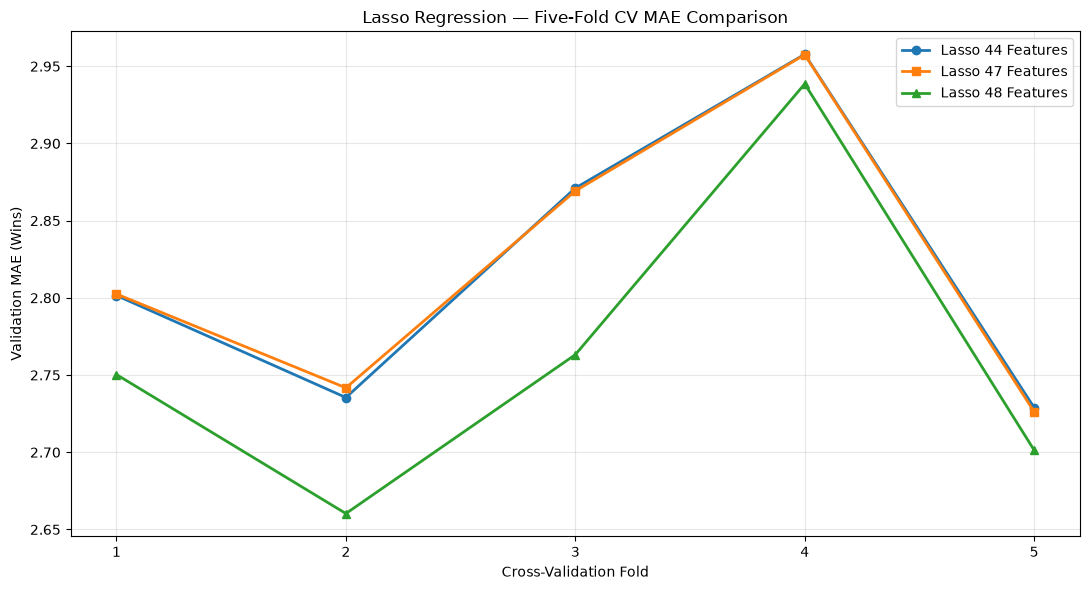

In [46]:
# ============================================================
# STEP 14 — FIVE-FOLD CV MAE COMPARISON
# Lasso: 44 vs 47 vs 48 Features
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_val_score

# ------------------------------------------------------------
# STEP 1 — Prepare feature sets
# ------------------------------------------------------------

X_cv_48 = X_train_48.copy()

X_cv_47 = X_cv_48.drop(
    columns=["Pythagorean_Expected_Wins"]
)

X_cv_44 = X_cv_47.drop(
    columns=[
        "R_per_game",
        "RA_per_game",
        "Run_Differential"
    ]
)

y_cv = y_train_47exp.copy()

print("FEATURE VERIFICATION")
print("--------------------")
print("44 Features:", X_cv_44.shape)
print("47 Features:", X_cv_47.shape)
print("48 Features:", X_cv_48.shape)

# ------------------------------------------------------------
# STEP 2 — Define the same CV folds
# ------------------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# STEP 3 — Build evaluation function
# ------------------------------------------------------------

def get_cv_scores(X, y):

    scale_cols = [
        col for col in X.columns
        if not col.startswith(("era_", "decade_"))
    ]

    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer(
            [("scale", StandardScaler(), scale_cols)],
            remainder="passthrough"
        )),
        ("lasso", Lasso(
            alpha=0.01,
            max_iter=100000
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    return -scores

# ------------------------------------------------------------
# STEP 4 — Calculate CV MAE for each model
# ------------------------------------------------------------

scores_44 = get_cv_scores(X_cv_44, y_cv)
scores_47 = get_cv_scores(X_cv_47, y_cv)
scores_48 = get_cv_scores(X_cv_48, y_cv)

# ------------------------------------------------------------
# STEP 5 — Compare individual folds
# ------------------------------------------------------------

fold_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Lasso 44": scores_44,
    "Lasso 47": scores_47,
    "Lasso 48": scores_48
})

print("\nFIVE-FOLD CV MAE COMPARISON")
print("===========================")
print(fold_results.round(4).to_string(index=False))

# ------------------------------------------------------------
# STEP 6 — Compare mean and standard deviation
# ------------------------------------------------------------

summary = pd.DataFrame({
    "Model": [
        "Lasso 44",
        "Lasso 47",
        "Lasso 48"
    ],
    "Mean CV MAE": [
        scores_44.mean(),
        scores_47.mean(),
        scores_48.mean()
    ],
    "CV Std": [
        scores_44.std(ddof=1),
        scores_47.std(ddof=1),
        scores_48.std(ddof=1)
    ]
})

print("\nCROSS-VALIDATION SUMMARY")
print("========================")
print(summary.round(4).to_string(index=False))

# ------------------------------------------------------------
# STEP 7 — Count which model wins each fold
# ------------------------------------------------------------

wins_48_vs_44 = np.sum(scores_48 < scores_44)
wins_48_vs_47 = np.sum(scores_48 < scores_47)

print("\n48-FEATURE MODEL PERFORMANCE")
print("===========================")

print(
    "48 beats 44 in:",
    wins_48_vs_44,
    "out of 5 folds"
)

print(
    "48 beats 47 in:",
    wins_48_vs_47,
    "out of 5 folds"
)

# ------------------------------------------------------------
# STEP 8 — Visualize fold-by-fold CV MAE
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    fold_results["Fold"],
    scores_44,
    marker="o",
    linewidth=2,
    label="Lasso 44 Features"
)

plt.plot(
    fold_results["Fold"],
    scores_47,
    marker="s",
    linewidth=2,
    label="Lasso 47 Features"
)

plt.plot(
    fold_results["Fold"],
    scores_48,
    marker="^",
    linewidth=2,
    label="Lasso 48 Features"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("Validation MAE (Wins)")

plt.title(
    "Lasso Regression — Five-Fold CV MAE Comparison"
)

plt.xticks([1, 2, 3, 4, 5])

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 14 — Five-Fold Cross-Validation Analysis: Lasso Regression (44 vs 47 vs 48 Features)

### 1. Objective

The objective of this experiment is to evaluate whether the improvement observed after introducing **Pythagorean Expected Wins** is consistent across the five cross-validation folds.

Three Lasso Regression models were compared:

- **Model A:** 44 original features.
- **Model B:** 47 features, including three engineered features.
- **Model C:** 48 features, including Pythagorean Expected Wins.

All three models used alpha = 0.01 and the same five-fold cross-validation partitions.

The primary evaluation metric was **Mean Absolute Error (MAE)**, where lower values indicate better predictive performance.

### 2. Cross-Validation Methodology

Five-fold cross-validation was conducted using the training portion of the dataset.

The training dataset contained **1,129 observations**.

| Parameter | Configuration |
|---|---|
| Cross-validation | 5-Fold KFold |
| Shuffle | True |
| Random State | 42 |
| Lasso Alpha | 0.01 |
| Evaluation Metric | Negative MAE (converted to positive MAE) |
| Training Observations | 1,129 |
| Feature Sets | 44, 47 and 48 |

The same cross-validation partitions were used across all three feature configurations to ensure comparability.

Numerical features were standardized independently within each training fold using a preprocessing pipeline, helping prevent scaling-related data leakage.

### 3. Five-Fold CV MAE Results

| Fold | Lasso 44 Features | Lasso 47 Features | Lasso 48 Features |
|---|---:|---:|---:|
| Fold 1 | 2.8015 | 2.8025 | **2.7503** |
| Fold 2 | 2.7355 | 2.7417 | **2.6603** |
| Fold 3 | 2.8711 | 2.8692 | **2.7632** |
| Fold 4 | 2.9578 | 2.9575 | **2.9386** |
| Fold 5 | 2.7290 | 2.7263 | **2.7014** |
| **Mean CV MAE** | 2.8190 | 2.8195 | **2.7628** |
| **CV Standard Deviation** | 0.0966 | 0.0956 | 0.1065 |

**Observation:** The 48-feature model achieved the lowest validation MAE in all five folds.

This indicates that its lower mean CV MAE was not driven by a single exceptionally favorable fold.

### 4. Mean CV MAE Comparison

The average cross-validation results were:

| Model | Mean CV MAE | Ranking |
|---|---:|---|
| Lasso 48 Features | **2.7628** | 1 |
| Lasso 44 Features | 2.8190 | 2 |
| Lasso 47 Features | 2.8195 | 3 |

Compared with the original 44-feature model:

\[
\text{MAE Reduction} = 2.8190 - 2.7628 = 0.0562
\]

The percentage reduction was:

\[
\frac{0.0562}{2.8190}\times100 \approx 1.99\%
\]

Therefore, the 48-feature model achieved approximately **1.99% lower mean CV MAE** than the original 44-feature Lasso model.

This represents an encouraging improvement in cross-validation predictive performance.

### 5. Fold-by-Fold Consistency

The following comparisons were obtained:

| Comparison | Folds Won by 48-Feature Model |
|---|---:|
| 48 Features vs 44 Features | **5 out of 5** |
| 48 Features vs 47 Features | **5 out of 5** |

The 48-feature model consistently achieved lower validation errors than both alternative models.

The improvement was largest in Fold 3 relative to the 44-feature model, while Fold 4 showed a smaller improvement.

For Fold 4:

- Lasso 44 MAE: 2.9578
- Lasso 48 MAE: 2.9386
- Improvement: 0.0192 wins

This demonstrates that the size of the improvement varied across folds, although its direction was consistent.

**Interpretation:** The new nonlinear feature appears to provide a useful predictive representation across the evaluated cross-validation partitions.

However, consistent improvements in these five folds do not by themselves establish statistical significance or guarantee improvements on independently collected data.

### 6. Cross-Validation Standard Deviation

The standard deviation measures how much validation MAE varies across folds.

| Model | CV MAE Standard Deviation |
|---|---:|
| Lasso 44 Features | 0.0966 |
| Lasso 47 Features | **0.0956** |
| Lasso 48 Features | 0.1065 |

The 48-feature model had a slightly higher standard deviation.

This indicates somewhat greater variability in its validation errors across folds.

Despite this, it achieved the lowest average MAE and outperformed the other two models in every fold.

The higher standard deviation does not automatically indicate overfitting because different validation folds can vary in prediction difficulty.

### 7. Cross-Validation vs Testing Performance

The results were compared with the previously obtained held-out testing metrics.

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| **CV MAE** | 2.8190 | 2.8195 | **2.7628** |
| Testing MAE | 2.6898 | **2.6883** | 2.6904 |
| Testing RMSE | 3.3248 | 3.3242 | **3.3029** |
| Testing R² | 0.9308 | 0.9308 | **0.9317** |

The 48-feature model achieved the best cross-validation MAE, testing RMSE and testing R².

However, the 47-feature model achieved a marginally lower testing MAE.

The difference between the 47-feature and 48-feature testing MAE values was:

\[
2.6904-2.6883=0.0021
\]

This difference is negligible.

Therefore, the fold-by-fold improvement supports the usefulness of Pythagorean Expected Wins, but the held-out test results do not show a meaningful improvement in average absolute prediction error.

### 8. Interpretation of Nonlinear Feature Engineering

The 48-feature model introduced **Pythagorean Expected Wins**, calculated as:

\[
\text{Expected Wins}
=
G\times\frac{R^2}{R^2+RA^2}
\]

Unlike the original engineered Run Differential feature, this formula captures a nonlinear relationship between runs scored and runs allowed.

Although Pythagorean Expected Wins is derived from existing baseball statistics, it provides a nonlinear transformation that ordinary Lasso Regression cannot express directly using only separate linear terms for R and RA.

The five-fold comparison suggests that this transformation may help the linear Lasso model represent relationships associated with team wins.

The improvement should be interpreted as evidence of better validation performance under the evaluated experimental configuration, rather than proof of an inherently superior model.

### 9. Key Findings

**Finding 1 — The 48-feature model achieved the lowest mean CV MAE.**

The average CV MAE decreased from 2.8190 to 2.7628 compared with the original 44-feature model.

**Finding 2 — Improvement occurred in all five folds.**

The 48-feature model outperformed both comparison models in every validation fold.

**Finding 3 — The improvement was approximately 1.99%.**

This reflects the reduction in mean CV MAE compared with the original 44-feature model.

**Finding 4 — Validation variability increased slightly.**

The 48-feature model recorded a CV standard deviation of 0.1065, compared with 0.0966 for the original 44-feature model.

**Finding 5 — Held-out testing MAE remained practically unchanged.**

Although CV MAE improved, the 48-feature model did not demonstrate a meaningful reduction in testing MAE.

**Finding 6 — Nonlinear feature engineering appears promising.**

The results suggest that domain-informed nonlinear transformations may provide predictive value beyond simple linear combinations of existing baseball statistics.

### 10. Limitations

The analysis used the same five cross-validation folds that had previously been used to select the Lasso regularization parameter.

Consequently, the reported CV MAE results are not independent estimates of the complete hyperparameter-selection procedure.

The folds were also generated from a single randomized training partition. Their performance cannot establish that similar improvements would occur across all possible training samples.

Furthermore, the held-out test set had already been examined during earlier feature-engineering experiments, making the overall analysis exploratory.

The observed fold-level improvement should therefore be supported by additional validation before claiming consistent superiority in future predictions.

### 11. Recommended Next Experiment

The next recommended step is **repeated or nested cross-validation**.

Repeated cross-validation would assess performance across several randomized fold partitions.

Nested cross-validation would provide a stronger evaluation by performing alpha tuning within each outer training fold and evaluating the selected model on a separate outer validation fold.

A suitable experiment would compare all three feature configurations using:

- Five outer folds.
- Multiple random repetitions, or a nested cross-validation framework.
- Alpha tuning performed using training observations only.
- MAE as the primary evaluation metric.
- RMSE and R² as secondary metrics.

This would help determine whether the observed improvement from Pythagorean Expected Wins remains reliable under different validation partitions.

### 12. Conclusion

The five-fold cross-validation comparison demonstrated that the 48-feature Lasso Regression model achieved consistently lower validation MAE than both the 44-feature and 47-feature alternatives.

Its mean CV MAE was **2.7628**, compared with 2.8190 and 2.8195 for the other models.

The 48-feature model achieved lower validation errors in all five folds, representing an approximately **1.99% reduction in mean CV MAE** relative to the original 44-feature model.

These findings provide encouraging evidence that adding Pythagorean Expected Wins improved Lasso's predictive performance during cross-validation.

However, the testing MAE remained almost unchanged, and the model exhibited slightly greater variation in validation errors across folds.

**Overall, the results suggest that baseball-informed nonlinear feature engineering can improve cross-validation performance, but additional independent validation is required before concluding that the 48-feature model generalizes better.**

The 48-feature model is therefore retained as a promising experimental candidate, while the original 44-feature Lasso remains the benchmark for further comparison.


Running Nested CV: Lasso 44
--------------------------------
Fold 1 | Alpha: 0.01 | MAE: 2.7605
Fold 2 | Alpha: 0.01 | MAE: 3.0280
Fold 3 | Alpha: 0.01 | MAE: 2.9244
Fold 4 | Alpha: 0.001 | MAE: 2.8317
Fold 5 | Alpha: 0.01 | MAE: 2.4173

Running Nested CV: Lasso 47
--------------------------------
Fold 1 | Alpha: 0.01 | MAE: 2.7600
Fold 2 | Alpha: 0.01 | MAE: 3.0274
Fold 3 | Alpha: 0.01 | MAE: 2.9254
Fold 4 | Alpha: 0.001 | MAE: 2.8395
Fold 5 | Alpha: 0.01 | MAE: 2.4212

Running Nested CV: Lasso 48
--------------------------------
Fold 1 | Alpha: 0.01 | MAE: 2.7122
Fold 2 | Alpha: 0.01 | MAE: 2.9888
Fold 3 | Alpha: 0.01 | MAE: 2.9441
Fold 4 | Alpha: 0.001 | MAE: 2.7162
Fold 5 | Alpha: 0.01 | MAE: 2.3972

NESTED CV — INDIVIDUAL FOLD RESULTS
   Model  Fold  Best Alpha    MAE   RMSE     R2
Lasso 44     1       0.010 2.7605 3.5442 0.9197
Lasso 44     2       0.010 3.0280 3.7016 0.9314
Lasso 44     3       0.010 2.9244 3.7347 0.9220
Lasso 44     4       0.001 2.8317 3.5918 0.9359
Lasso 44 

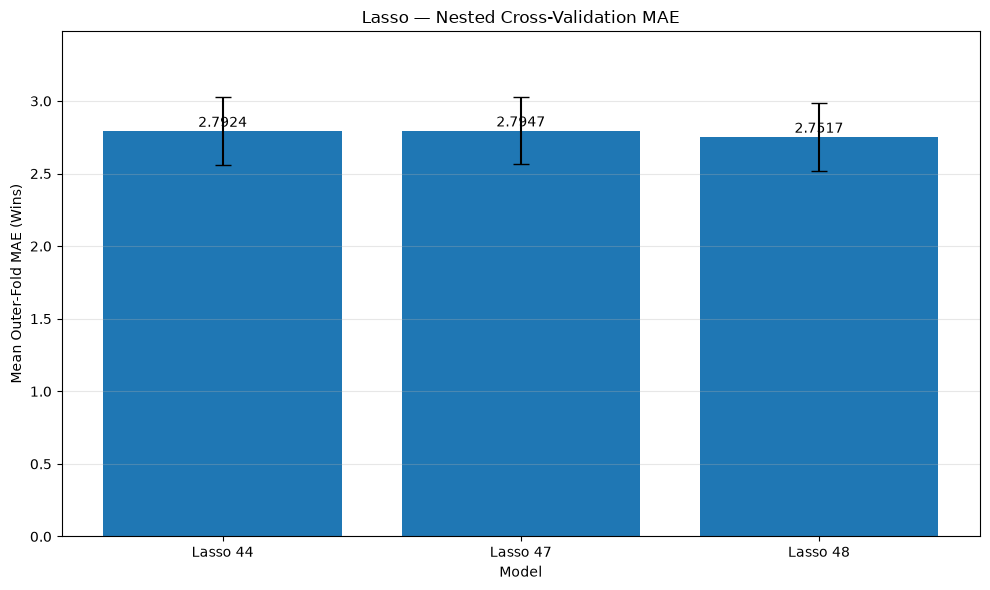

In [47]:
# ============================================================
# STEP 15 — NESTED CROSS-VALIDATION
# LASSO: 44 vs 47 vs 48 Features
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — Prepare the 3 feature sets
# ------------------------------------------------------------

X_nested_48 = X_train_48.copy()

X_nested_47 = X_nested_48.drop(
    columns=["Pythagorean_Expected_Wins"]
)

X_nested_44 = X_nested_47.drop(
    columns=[
        "R_per_game",
        "RA_per_game",
        "Run_Differential"
    ]
)

y_nested = y_train_47exp.copy()

feature_sets = {
    "Lasso 44": X_nested_44,
    "Lasso 47": X_nested_47,
    "Lasso 48": X_nested_48
}

assert [X.shape[1] for X in feature_sets.values()] == [
    44, 47, 48
]

# ------------------------------------------------------------
# STEP 2 — Define inner and outer cross-validation
# ------------------------------------------------------------

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

alpha_values = [1.0, 0.5, 0.1, 0.05, 0.01, 0.001]

# ------------------------------------------------------------
# STEP 3 — Run nested cross-validation
# ------------------------------------------------------------

nested_results = []

for model_name, X_data in feature_sets.items():

    # Identify numerical features for scaling
    scale_cols = [
        c for c in X_data.columns
        if not c.startswith(("era_", "decade_"))
    ]

    print(f"\nRunning Nested CV: {model_name}")
    print("--------------------------------")

    for fold, (train_idx, val_idx) in enumerate(
        outer_cv.split(X_data, y_nested), start=1
    ):

        X_tr = X_data.iloc[train_idx]
        X_val = X_data.iloc[val_idx]

        y_tr = y_nested.iloc[train_idx]
        y_val = y_nested.iloc[val_idx]

        # Pipeline prevents scaling leakage
        pipeline = Pipeline([
            ("preprocessing", ColumnTransformer(
                [("scale", StandardScaler(), scale_cols)],
                remainder="passthrough"
            )),
            ("lasso", Lasso(max_iter=100000))
        ])

        # Inner CV selects best alpha
        search = GridSearchCV(
            pipeline,
            {"lasso__alpha": alpha_values},
            cv=inner_cv,
            scoring="neg_mean_absolute_error",
            n_jobs=-1
        )

        search.fit(X_tr, y_tr)

        # Outer validation evaluates tuned model
        preds = search.best_estimator_.predict(X_val)

        mae = mean_absolute_error(y_val, preds)

        rmse = np.sqrt(
            mean_squared_error(y_val, preds)
        )

        r2 = r2_score(y_val, preds)

        nested_results.append({
            "Model": model_name,
            "Fold": fold,
            "Best Alpha": search.best_params_["lasso__alpha"],
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        print(
            f"Fold {fold} | "
            f"Alpha: {search.best_params_['lasso__alpha']} | "
            f"MAE: {mae:.4f}"
        )

# ------------------------------------------------------------
# STEP 4 — Show all fold results
# ------------------------------------------------------------

nested_df = pd.DataFrame(nested_results)

print("\nNESTED CV — INDIVIDUAL FOLD RESULTS")
print("===================================")

print(nested_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# STEP 5 — Summary statistics
# ------------------------------------------------------------

nested_summary = (
    nested_df.groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_R2=("R2", "mean")
    )
    .round(4)
)

print("\nNESTED CV — FINAL SUMMARY")
print("=========================")

print(nested_summary.to_string())

# ------------------------------------------------------------
# STEP 6 — Compare 48 features against alternatives
# ------------------------------------------------------------

fold_mae = nested_df.pivot(
    index="Fold",
    columns="Model",
    values="MAE"
)

print("\n48-FEATURE MODEL PERFORMANCE")
print("============================")

print(
    "48 beats 44:",
    int((fold_mae["Lasso 48"] < fold_mae["Lasso 44"]).sum()),
    "out of 5 folds"
)

print(
    "48 beats 47:",
    int((fold_mae["Lasso 48"] < fold_mae["Lasso 47"]).sum()),
    "out of 5 folds"
)

# ------------------------------------------------------------
# STEP 7 — Visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

models = nested_summary.index.tolist()

means = nested_summary["Mean_MAE"].values
stds = nested_summary["Std_MAE"].values

bars = plt.bar(
    models,
    means,
    yerr=stds,
    capsize=6
)

for bar, value in zip(bars, means):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.03,
        f"{value:.4f}",
        ha="center"
    )

plt.title("Lasso — Nested Cross-Validation MAE")
plt.ylabel("Mean Outer-Fold MAE (Wins)")
plt.xlabel("Model")
plt.ylim(0, max(means + stds) * 1.15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Step 15 — Nested Cross-Validation Analysis: Lasso Regression (44 vs 47 vs 48 Features)

### 1. Objective

The objective of this experiment is to evaluate whether the improved predictive performance of the **48-feature Lasso Regression model**, which incorporates Pythagorean Expected Wins, remains consistent under a more rigorous cross-validation procedure.

Three feature configurations were evaluated:

- **Model A:** 44 original baseball features.
- **Model B:** 47 features, including three engineered features.
- **Model C:** 48 features, including Pythagorean Expected Wins.

Nested cross-validation was applied to separate hyperparameter tuning from model performance evaluation.

The primary metric was **Mean Absolute Error (MAE)**, where lower values indicate better predictive performance.

Secondary evaluation metrics included Root Mean Squared Error (RMSE), R² and variability across validation folds.

### 2. Why Nested Cross-Validation?

In conventional cross-validation, the same validation results may be used to select the best hyperparameter and report model performance.

This can produce an optimistically biased estimate of generalization performance.

Nested cross-validation addresses this limitation by introducing two validation loops.

**Inner Cross-Validation — Hyperparameter Tuning**

The inner loop identifies the best Lasso regularization parameter (alpha) using GridSearchCV.

**Outer Cross-Validation — Model Evaluation**

The outer loop evaluates the tuned model using validation observations that were not used during the inner hyperparameter search.

This separation provides a more reliable estimate of the predictive performance of the model-tuning procedure.

### 3. Experimental Methodology

| Parameter | Configuration |
|---|---|
| Model | Lasso Regression |
| Training Observations | 1,129 |
| Feature Configurations | 44, 47 and 48 |
| Outer Cross-Validation | 5-Fold KFold |
| Outer Random State | 2026 |
| Inner Cross-Validation | 3-Fold KFold |
| Inner Random State | 42 |
| Shuffle | True |
| Alpha Candidates | 1.0, 0.5, 0.1, 0.05, 0.01, 0.001 |
| Primary Evaluation Metric | MAE |
| Secondary Metrics | RMSE and R² |

All three models were evaluated using the same outer validation partitions to ensure consistent comparison.

Numerical variables were standardized within the modelling pipeline. Scaling parameters were estimated using training observations only within each cross-validation split.

### 4. Individual Nested Cross-Validation Results

| Model | Fold | Best Alpha | MAE | RMSE | R² |
|---|---:|---:|---:|---:|---:|
| Lasso 44 | 1 | 0.010 | 2.7605 | 3.5442 | 0.9197 |
| Lasso 44 | 2 | 0.010 | 3.0280 | 3.7016 | 0.9314 |
| Lasso 44 | 3 | 0.010 | 2.9244 | 3.7347 | 0.9220 |
| Lasso 44 | 4 | 0.001 | 2.8317 | 3.5918 | 0.9359 |
| Lasso 44 | 5 | 0.010 | 2.4173 | 3.1361 | 0.9379 |
| Lasso 47 | 1 | 0.010 | 2.7600 | 3.5427 | 0.9198 |
| Lasso 47 | 2 | 0.010 | 3.0274 | 3.7009 | 0.9315 |
| Lasso 47 | 3 | 0.010 | 2.9254 | 3.7339 | 0.9221 |
| Lasso 47 | 4 | 0.001 | 2.8395 | 3.5994 | 0.9356 |
| Lasso 47 | 5 | 0.010 | 2.4212 | 3.1430 | 0.9376 |
| Lasso 48 | 1 | 0.010 | 2.7122 | 3.4578 | 0.9236 |
| Lasso 48 | 2 | 0.010 | 2.9888 | 3.6762 | 0.9324 |
| Lasso 48 | 3 | 0.010 | 2.9441 | 3.6589 | 0.9252 |
| Lasso 48 | 4 | 0.001 | 2.7162 | 3.4470 | 0.9409 |
| Lasso 48 | 5 | 0.010 | 2.3972 | 3.0787 | 0.9402 |

### 5. Final Nested Cross-Validation Summary

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| **Mean MAE ↓** | 2.7924 | 2.7947 | **2.7517** |
| MAE Standard Deviation | 0.2325 | **0.2312** | 0.2354 |
| **Mean RMSE ↓** | 3.5417 | 3.5440 | **3.4637** |
| **Mean R² ↑** | 0.9294 | 0.9293 | **0.9325** |

**Observation:** The 48-feature Lasso model achieved the lowest mean MAE, lowest mean RMSE and highest mean R² under nested cross-validation.

This provides further evidence that introducing Pythagorean Expected Wins may improve the model's predictive performance.

However, the 48-feature model also demonstrated slightly greater fold-to-fold variability in MAE.

### 6. Mean MAE Improvement

The original 44-feature model achieved:

**Mean Nested CV MAE = 2.7924**

The 48-feature model achieved:

**Mean Nested CV MAE = 2.7517**

The reduction in error was:

\[
2.7924-2.7517=0.0407
\]

The percentage improvement was:

\[
\frac{0.0407}{2.7924}\times100\approx1.46\%
\]

Therefore, the 48-feature model achieved approximately **1.46% lower mean nested CV MAE** than the original 44-feature model.

This improvement is modest but encouraging.

### 7. Fold-by-Fold Consistency Analysis

The 48-feature model achieved lower MAE than both alternatives in four of the five outer validation folds.

| Comparison | Folds Won by 48-Feature Model |
|---|---:|
| Lasso 48 vs Lasso 44 | **4 out of 5** |
| Lasso 48 vs Lasso 47 | **4 out of 5** |

**Folds 1, 2, 4 and 5**

The 48-feature model achieved the lowest MAE among the three models.

**Fold 3**

The 48-feature model performed slightly worse:

| Model | Fold 3 MAE |
|---|---:|
| Lasso 44 | **2.9244** |
| Lasso 47 | 2.9254 |
| Lasso 48 | 2.9441 |

This demonstrates that adding Pythagorean Expected Wins does not guarantee better prediction accuracy across every validation partition.

Nevertheless, the 48-feature model maintained the best average performance over the five outer folds.

### 8. Hyperparameter Stability

The nested cross-validation experiment also examined the optimal alpha selected during inner cross-validation.

| Fold | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| 1 | 0.01 | 0.01 | 0.01 |
| 2 | 0.01 | 0.01 | 0.01 |
| 3 | 0.01 | 0.01 | 0.01 |
| 4 | 0.001 | 0.001 | 0.001 |
| 5 | 0.01 | 0.01 | 0.01 |

All three models selected:

- **Alpha = 0.01 in four folds.**
- **Alpha = 0.001 in one fold.**

This indicates that the preferred regularization strength was reasonably consistent across the evaluated training partitions.

The occasional selection of alpha = 0.001 suggests that a weaker L1 penalty may be preferable for some training subsets.

### 9. Comparison with Previous Experiments

The nested cross-validation findings were compared with the original five-fold CV and held-out testing results.

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| Original 5-Fold CV MAE | 2.8190 | 2.8195 | **2.7628** |
| **Nested CV MAE** | 2.7924 | 2.7947 | **2.7517** |
| Testing MAE | 2.6898 | **2.6883** | 2.6904 |
| Testing RMSE | 3.3248 | 3.3242 | **3.3029** |
| Testing R² | 0.9308 | 0.9308 | **0.9317** |

The 48-feature model performed best according to nested CV MAE, testing RMSE and testing R².

However, the 47-feature model achieved a marginally lower testing MAE.

The differences in testing MAE were extremely small.

These results suggest that the new nonlinear feature may improve model robustness in some evaluation settings, but it does not establish a substantial improvement in held-out average absolute prediction error.

The original and nested CV results were obtained using different validation partitions and tuning procedures, so their absolute MAE values are not expected to be identical.

### 10. Interpretation of Nonlinear Feature Engineering

The 48-feature model introduced the baseball-specific feature:

\[
\text{Pythagorean Expected Wins}
=
G\times\frac{R^2}{R^2+RA^2}
\]

This feature represents a nonlinear relationship between runs scored, runs allowed and expected team wins.

Unlike Run Differential, which is a linear combination of existing predictors, Pythagorean Expected Wins provides a nonlinear transformation.

This allows a linear Lasso Regression model to represent more complex relationships without changing the underlying regression algorithm.

The improvement in nested CV performance suggests that this transformation may provide useful predictive information.

However, the engineered feature is still derived from existing baseball statistics and should not be interpreted as introducing independent new data.

### 11. Key Findings

**Finding 1 — The 48-feature model achieved the best nested CV performance.**

It recorded the lowest mean MAE of 2.7517, compared with 2.7924 and 2.7947 for the alternative models.

**Finding 2 — Mean nested CV MAE improved by approximately 1.46%.**

The improvement was measured relative to the original 44-feature Lasso.

**Finding 3 — Improvement occurred in four of five outer folds.**

The 48-feature model outperformed the other models in most, but not all, validation partitions.

**Finding 4 — Testing performance remained broadly similar.**

Although nested CV MAE improved, held-out testing MAE remained approximately 2.69 wins for all three models.

**Finding 5 — Alpha tuning was reasonably stable.**

Alpha = 0.01 was selected in four of five folds for all three feature configurations.

**Finding 6 — Nonlinear feature engineering showed potential value.**

The Pythagorean Expected Wins feature appears to improve the ability of Lasso to represent baseball performance relationships under cross-validation.

### 12. Limitations

Nested cross-validation provides a more rigorous assessment of hyperparameter tuning than reporting the best GridSearchCV score alone.

However, several limitations remain.

First, the experiment used only five outer folds from one randomized partitioning scheme.

Second, the performance improvement was relatively small and was not observed in every fold.

Third, the 48-feature configuration was introduced after reviewing earlier experiments, including held-out testing results. Therefore, nested CV does not completely remove the effects of exploratory model selection.

Fourth, the training dataset includes historical full-season statistics. Results should therefore be interpreted as estimates of completed-season wins rather than validated preseason forecasts.

Additional evaluation using repeated nested cross-validation or a genuinely independent dataset would provide stronger evidence of generalization performance.

### 13. Recommendation

Based on the experimental results:

- **44-feature Lasso:** Retain as the original benchmark model.
- **47-feature Lasso:** Retain as the basic feature-engineering experiment.
- **48-feature Lasso:** Retain as the leading exploratory candidate based on nested CV performance.

The 48-feature model provides the strongest nested cross-validation results, although its advantage in held-out testing performance remains limited.

Rather than continuing to introduce additional features, the next stage should focus on comparing Lasso with alternative machine learning algorithms, such as Decision Tree Regression.

### 14. Conclusion

The nested cross-validation experiment demonstrated that the **48-feature Lasso Regression model achieved the strongest average predictive performance** among the three evaluated feature configurations.

Its mean nested CV MAE was **2.7517**, representing an approximately **1.46% reduction** compared with the original 44-feature Lasso.

The model achieved lower validation MAE in four of five outer folds, together with the lowest mean RMSE of 3.4637 and highest mean R² of 0.9325.

These findings provide encouraging evidence that introducing Pythagorean Expected Wins improved Lasso's predictive performance under the evaluated nested cross-validation procedure.

Nevertheless, testing MAE remained almost identical across the models, and the observed improvement was modest.

**Overall, the results support the potential value of domain-informed nonlinear feature engineering while highlighting the importance of rigorous validation and cautious interpretation of small performance improvements.**

The 48-feature Lasso is retained as the strongest exploratory candidate based on nested CV MAE, while the 44-feature Lasso remains the original benchmark for future machine learning comparisons.

## Step 15A — Why Did Nested Cross-Validation Select Alpha = 0.001 in Fold 4?

### 1. Objective

The objective of this analysis is to explain why nested cross-validation selected a different Lasso regularization parameter in Fold 4 compared with the other four outer folds.

The experiment used:

- **Outer cross-validation:** 5 folds
- **Inner cross-validation:** 3 folds
- **Evaluation metric:** Mean Absolute Error (MAE)
- **Alpha candidates:** 1.0, 0.5, 0.1, 0.05, 0.01 and 0.001
- **Feature configurations:** 44, 47 and 48 features

### 2. Nested Cross-Validation Alpha Selection Results

| Outer Fold | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| Fold 1 | 0.01 | 0.01 | 0.01 |
| Fold 2 | 0.01 | 0.01 | 0.01 |
| Fold 3 | 0.01 | 0.01 | 0.01 |
| **Fold 4** | **0.001** | **0.001** | **0.001** |
| Fold 5 | 0.01 | 0.01 | 0.01 |

**Observation:** All three feature configurations selected alpha = 0.001 in Fold 4, while alpha = 0.01 was selected in the other four folds.

### 3. Understanding Alpha in Lasso Regression

Lasso Regression uses L1 regularization to control model complexity.

The objective function includes a penalty proportional to the absolute values of model coefficients.

A larger alpha applies stronger regularization, while a smaller alpha applies weaker regularization.

| Alpha | Regularization Strength | General Effect |
|---|---|---|
| 1.0 | Stronger | Encourages more coefficients to become zero |
| 0.01 | Weaker | Allows more coefficients to retain nonzero values |
| 0.001 | Even weaker | Applies a smaller penalty to model coefficients |

**Important:** Reducing alpha does not guarantee that more features will be selected or that predictive accuracy will improve.

### 4. Why Did Fold 4 Select Alpha = 0.001?

Nested cross-validation separates hyperparameter selection from model evaluation.

**Inner cross-validation — Hyperparameter selection**

For each outer fold, GridSearchCV evaluates the candidate alpha values using the outer training subset.

The alpha with the lowest average inner validation MAE is selected.

**Outer cross-validation — Model evaluation**

The selected model is then evaluated using the corresponding outer validation subset, which was not used for training or alpha selection.

In Fold 4, the inner cross-validation procedure selected alpha = 0.001 for all three models.

This indicates that alpha = 0.001 produced the best average inner validation MAE among the tested candidates for that particular outer training subset.

The exact difference between alpha = 0.001 and alpha = 0.01 cannot be determined from the reported output because the individual inner CV scores were not displayed.

### 5. Why Can the Best Alpha Change Across Folds?

Each outer fold contains a different combination of training and validation observations.

Therefore, the relationships between predictors and the target variable may vary slightly across training subsets.

These differences can affect the optimal level of regularization.

For example:

- A training subset may benefit from stronger coefficient shrinkage.
- Another subset may benefit from allowing greater model flexibility.
- Correlations among baseball statistics may differ across subsets.
- Random variation in the observations can affect validation performance.

Consequently, it is normal for nested cross-validation to select different hyperparameters across outer folds.

### 6. Fold 4 Model Performance

The Fold 4 outer validation results were:

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| Best Alpha | 0.001 | 0.001 | 0.001 |
| MAE | 2.8317 | 2.8395 | **2.7162** |
| RMSE | 3.5918 | 3.5994 | **3.4470** |
| R² | 0.9359 | 0.9356 | **0.9409** |

The 48-feature model achieved the lowest MAE and RMSE and the highest R² in Fold 4.

However, these results do not establish that alpha = 0.001 is universally better than alpha = 0.01.

The selected alpha was determined using the inner cross-validation results, not by directly optimizing performance on the outer validation fold.

### 7. Does Alpha = 0.001 Indicate Overfitting?

Selecting a smaller alpha does not automatically indicate overfitting.

A smaller alpha reduces regularization and allows the model greater flexibility, which can increase overfitting risk under certain conditions.

However, determining whether overfitting occurred requires examination of training and validation performance.

The Fold 4 results alone do not provide sufficient evidence to conclude that alpha = 0.001 caused overfitting.

The observed outer validation results indicate that the tuned models maintained useful predictive performance on that particular fold.

### 8. Hyperparameter Stability

Across the five outer folds:

| Alpha | Number of Folds Selected | Percentage |
|---|---:|---:|
| **0.01** | **4** | **80%** |
| 0.001 | 1 | 20% |

The same selection pattern was observed for all three Lasso feature configurations.

**Interpretation:** Alpha = 0.01 was the most frequently selected parameter, suggesting that the preferred regularization strength was reasonably stable across the evaluated training partitions.

Nevertheless, this observation is based on only five outer folds and should not be interpreted as proof that alpha = 0.01 is universally optimal.

### 9. Key Findings

**Finding 1 — Alpha selection depends on training data.**

Different outer training subsets can produce different optimal hyperparameters.

**Finding 2 — Fold 4 preferred weaker regularization.**

GridSearchCV selected alpha = 0.001 instead of 0.01 for all three models.

**Finding 3 — Alpha = 0.01 demonstrated reasonable stability.**

The parameter was selected in four of five outer folds.

**Finding 4 — Smaller alpha does not necessarily indicate overfitting.**

Overfitting must be evaluated through model performance rather than the alpha value alone.

**Finding 5 — Nested cross-validation supports more rigorous evaluation.**

Hyperparameter tuning was performed within the inner folds, while predictive performance was measured using separate outer validation observations.

### 10. Conclusion

The nested cross-validation experiment selected alpha = 0.001 in Fold 4 because the inner three-fold cross-validation procedure favored weaker regularization for that outer training subset.

In contrast, alpha = 0.01 was selected in the other four folds for all three feature configurations.

This variation demonstrates that optimal regularization strength can depend on the observations used during model training.

The results suggest reasonable hyperparameter stability, with alpha = 0.01 selected in 80% of outer folds.

**Overall, Fold 4's selection of alpha = 0.001 is a normal outcome of nested cross-validation and does not, by itself, indicate overfitting or a modelling error.**

Further examination of the inner CV MAE scores for alpha = 0.001 and alpha = 0.01 would help determine whether the preference for weaker regularization was substantial or marginal.

## Understanding Nested Cross-Validation (Nested CV)

### 1. What Is Nested Cross-Validation?

**Nested Cross-Validation (Nested CV)** is a machine learning evaluation technique that uses two layers of cross-validation to separate hyperparameter tuning from model performance evaluation.

The two layers are:

- **Inner CV:** Selects the best hyperparameters.
- **Outer CV:** Evaluates how well the tuned model performs on unseen validation data.

Nested CV helps reduce the optimistic bias that can occur when the same cross-validation scores are used both to select a model and to report its performance.

**Memory aid: Nested CV = Tune Inside, Test Outside.**

### 2. ELI5 Explanation — Examination Analogy

Imagine a student preparing for an examination.

**Normal Cross-Validation**

The student tries different study methods using practice examination questions.

The student chooses the method that achieves the highest practice score.

However, reporting that same practice score as the final examination result may be overly optimistic.

**Nested Cross-Validation**

The student uses two separate evaluation stages:

- **Inner CV = Practice Examination:** Identify the best study method.
- **Outer CV = Independent Examination:** Evaluate the selected method using questions that were not used to choose it.

This provides a more reliable assessment of the student's performance on unfamiliar questions.

The same principle applies to evaluating machine learning models.

### 3. How Nested CV Works in the Moneyball Project

The Moneyball training dataset contains **1,129 historical MLB team-season observations**.

The nested cross-validation experiment used:

| Parameter | Configuration |
|---|---|
| Outer CV | 5 folds |
| Inner CV | 3 folds |
| Outer Random State | 2026 |
| Inner Random State | 42 |
| Model | Lasso Regression |
| Feature Configurations | 44, 47 and 48 |
| Primary Metric | MAE |
| Alpha Candidates | 1.0, 0.5, 0.1, 0.05, 0.01, 0.001 |

**Step 1 — Outer CV divides the data.**

The 1,129 training observations are divided into five outer folds.

During each iteration, approximately 80% of the observations are used for outer training and 20% are reserved for outer validation.

**Step 2 — Inner CV tunes alpha.**

The outer training portion is divided into three inner folds.

GridSearchCV evaluates the candidate alpha values and identifies the value with the lowest average inner validation MAE.

**Step 3 — Retrain using the selected alpha.**

The selected Lasso model is fitted using the complete outer training portion.

**Step 4 — Evaluate on the outer validation fold.**

The model predicts wins for observations excluded from both the fitting and hyperparameter-selection process for that outer fold.

MAE, RMSE and R² are calculated.

**Step 5 — Repeat across all five outer folds.**

Each outer fold independently performs hyperparameter tuning and model evaluation.

The outer validation metrics are averaged to obtain the nested CV results.

### 4. Normal CV vs Nested CV

| Aspect | Normal Cross-Validation | Nested Cross-Validation |
|---|---|---|
| Validation layers | One | Two |
| Hyperparameter tuning | Can be performed | Performed in inner CV |
| Independent evaluation of tuning | Not necessarily | Outer CV |
| Risk of optimistic tuning score | Higher when reporting the best tuning score | Reduced |
| Computational cost | Lower | Higher |
| Main purpose | Hyperparameter selection | Evaluation of the model-tuning procedure |

**Important:** Nested CV is not a separate machine learning algorithm. It is an evaluation methodology that can be applied to regression and classification models.

### 5. Nested CV Results — Moneyball Lasso

The following results were obtained:

| Metric | Lasso 44 | Lasso 47 | Lasso 48 |
|---|---:|---:|---:|
| Mean Nested CV MAE | 2.7924 | 2.7947 | **2.7517** |
| MAE Standard Deviation | 0.2325 | 0.2312 | 0.2354 |
| Mean Nested CV RMSE | 3.5417 | 3.5440 | **3.4637** |
| Mean Nested CV R² | 0.9294 | 0.9293 | **0.9325** |

The 48-feature model achieved the lowest mean MAE and RMSE, together with the highest mean R².

This suggests that the additional nonlinear Pythagorean Expected Wins feature may contribute useful predictive information.

### 6. Example — How Inner CV Selected Alpha

For the 48-feature Lasso model:

| Outer Fold | Best Alpha | Outer Validation MAE |
|---|---:|---:|
| 1 | 0.01 | 2.7122 |
| 2 | 0.01 | 2.9888 |
| 3 | 0.01 | 2.9441 |
| 4 | 0.001 | 2.7162 |
| 5 | 0.01 | 2.3972 |
| **Mean** | — | **2.7517** |

Alpha = 0.01 was selected in four outer folds, while alpha = 0.001 was selected in one fold.

This demonstrates that hyperparameter tuning was conducted independently within each outer training partition.

The 48-feature model achieved lower validation MAE than the 44-feature model in four of the five outer folds.

### 7. Why Are the Nested CV Results Different from Normal CV?

The original five-fold CV and nested CV results were:

| Model | Original CV MAE | Nested CV MAE |
|---|---:|---:|
| Lasso 44 | 2.8190 | 2.7924 |
| Lasso 47 | 2.8195 | 2.7947 |
| Lasso 48 | 2.7628 | 2.7517 |

The results differ because the experiments used different validation partitions and tuning procedures.

The original CV used five folds with random_state = 42.

Nested CV used five outer folds with random_state = 2026 and three inner folds with random_state = 42.

Therefore, differences between these CV values should not be interpreted as improvements caused by nested CV itself.

Nested CV primarily provides a more independent evaluation of hyperparameter tuning.

### 8. Why Nested CV Is Important for Research

Nested CV helps address several methodological concerns.

**1. Hyperparameter-selection bias**

The best tuning score may be overly optimistic because it was selected from several competing hyperparameter configurations.

Nested CV evaluates the tuning procedure using separate outer validation data.

**2. Data leakage prevention**

When preprocessing is implemented correctly inside the modelling pipeline, each validation fold remains excluded from the fitting of scaling parameters.

**3. Model comparison**

Using the same outer folds allows different models or feature configurations to be evaluated under comparable conditions.

**4. Generalization assessment**

Outer validation performance provides evidence about how well the complete tuning procedure may perform on observations excluded from its training.

### 9. Limitations

Although nested CV is more rigorous than reporting only the best tuning score, it does not eliminate all uncertainty.

The Moneyball experiment used five outer folds from one randomized partition.

The 48-feature model was also developed after reviewing earlier results, meaning that the choice of feature configuration was part of an exploratory process.

Nested CV evaluated alpha tuning within each predefined feature set; it did not independently repeat the entire feature-engineering discovery process.

Furthermore, the dataset contains historical full-season statistics. The evaluation therefore concerns estimating wins from season-level performance rather than making genuine preseason forecasts.

Repeated nested CV, chronological validation or evaluation on an untouched external dataset would strengthen conclusions about generalization.

### 10. Key Findings

**Finding 1 — Nested CV separates tuning and evaluation.**

The inner loop selects hyperparameters, while the outer loop evaluates the tuned model.

**Finding 2 — Alpha selection was reasonably stable.**

Alpha = 0.01 was selected in four of five outer folds across all three feature configurations.

**Finding 3 — The 48-feature model achieved the lowest nested CV MAE.**

Its mean MAE of 2.7517 was lower than 2.7924 for the original 44-feature model.

**Finding 4 — The performance improvement was modest.**

The reduction in mean nested CV MAE was approximately 1.46%.

**Finding 5 — Further validation remains necessary.**

Although the 48-feature model performed better in four of five outer folds, its held-out testing MAE was nearly identical to that of the other models.

### 11. Conclusion

Nested Cross-Validation provides a more rigorous approach to evaluating machine learning models by separating hyperparameter tuning from performance assessment.

In the Moneyball Lasso experiment, five outer folds and three inner folds were used to evaluate three feature configurations.

The 48-feature Lasso model achieved the lowest mean nested CV MAE of **2.7517**, mean RMSE of **3.4637**, and highest mean R² of **0.9325**.

These findings provide encouraging evidence that Pythagorean Expected Wins may improve the predictive capability of Lasso Regression.

However, the improvement was modest and was not observed in every outer validation fold.

**Overall, nested CV strengthened the evaluation methodology and supported the 48-feature Lasso as a promising candidate, while highlighting the importance of cautious interpretation and further independent validation.**

**Memory Aid:**

**Inner CV = Tune the model.**

**Outer CV = Test the tuning procedure.**

**Nested CV = Tune Inside, Test Outside.**

In [48]:
# ============================================================
# STEP 16 — ADDITIONAL NONLINEAR FEATURE ENGINEERING
# LASSO REGRESSION: 48 vs 56 FEATURES
#
# Objective: Try to improve CV MAE towards 2.707
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold


# ------------------------------------------------------------
# STEP 1 — Copy existing 48-feature training dataset
# ------------------------------------------------------------

X_train_56 = X_train_48.copy()

# Same training target
y_train_56 = y_train_47exp.copy()


# ------------------------------------------------------------
# STEP 2 — Add 8 nonlinear engineered features
# ------------------------------------------------------------

# 1. Pythagorean Expected Wins — exponent 1.83
X_train_56["Pythagorean_Expected_Wins_183"] = (
    X_train_56["G"]
    * X_train_56["R"] ** 1.83
    / (
        X_train_56["R"] ** 1.83
        + X_train_56["RA"] ** 1.83
    )
)

# 2. Run Differential per Game
X_train_56["Run_Diff_Per_Game"] = (
    (X_train_56["R"] - X_train_56["RA"])
    / X_train_56["G"]
)

# 3. Log Run Ratio
X_train_56["Log_Run_Ratio"] = np.log(
    (X_train_56["R"] + 1)
    / (X_train_56["RA"] + 1)
)

# 4. Batting Average
X_train_56["Batting_Average"] = (
    X_train_56["H"] / X_train_56["AB"]
)

# 5. Isolated Power
X_train_56["Isolated_Power"] = (
    X_train_56["2B"]
    + 2 * X_train_56["3B"]
    + 3 * X_train_56["HR"]
) / X_train_56["AB"]

# 6. WHIP Proxy
X_train_56["WHIP_Proxy"] = (
    X_train_56["HA"] + X_train_56["BBA"]
) / (X_train_56["IPouts"] / 3)

# 7. Walk Rate Proxy
X_train_56["BB_Rate_Proxy"] = (
    X_train_56["BB"]
    / (X_train_56["AB"] + X_train_56["BB"])
)

# 8. Pitching Strikeout-to-Walk Ratio
X_train_56["Pitching_K_BB_Ratio"] = (
    X_train_56["SOA"]
    / (X_train_56["BBA"] + 1)
)


# ------------------------------------------------------------
# STEP 3 — Verify features
# ------------------------------------------------------------

print("FEATURE VERIFICATION")
print("--------------------")

print("Original features:", X_train_48.shape[1])
print("New features:", X_train_56.shape[1])

assert X_train_56.shape[1] == 56

assert np.isfinite(
    X_train_56.to_numpy(dtype=float)
).all(), "Invalid values detected in engineered features."


# ------------------------------------------------------------
# STEP 4 — Define five-fold CV
# ------------------------------------------------------------

cv_56 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

alpha_grid_56 = {
    "lasso__alpha": [
        1.0, 0.5, 0.1, 0.05, 0.01, 0.001
    ]
}


# ------------------------------------------------------------
# STEP 5 — Create tuning function
# ------------------------------------------------------------

def tune_lasso_cv(X, y):

    scale_cols = [
        col for col in X.columns
        if not col.startswith(("era_", "decade_"))
    ]

    pipeline = Pipeline([
        (
            "preprocessing",
            ColumnTransformer(
                [("scale", StandardScaler(), scale_cols)],
                remainder="passthrough"
            )
        ),
        (
            "lasso",
            Lasso(max_iter=100000)
        )
    ])

    grid = GridSearchCV(
        pipeline,
        alpha_grid_56,
        cv=cv_56,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    grid.fit(X, y)

    return grid


# ------------------------------------------------------------
# STEP 6 — Tune both models
# ------------------------------------------------------------

grid_48_check = tune_lasso_cv(
    X_train_48,
    y_train_56
)

grid_56 = tune_lasso_cv(
    X_train_56,
    y_train_56
)


# ------------------------------------------------------------
# STEP 7 — Compare CV MAE
# ------------------------------------------------------------

cv_mae_48_check = -grid_48_check.best_score_
cv_mae_56 = -grid_56.best_score_

comparison_56 = pd.DataFrame({
    "Model": [
        "Lasso 48 Features",
        "Lasso 56 Features"
    ],
    "Best Alpha": [
        grid_48_check.best_params_["lasso__alpha"],
        grid_56.best_params_["lasso__alpha"]
    ],
    "CV MAE": [
        cv_mae_48_check,
        cv_mae_56
    ]
})

print("\nLASSO CV MAE COMPARISON")
print("======================")

print(
    comparison_56.round(4).to_string(index=False)
)

print("\nCV MAE IMPROVEMENT")
print("------------------")

print(
    f"Previous CV MAE: {cv_mae_48_check:.4f}"
)

print(
    f"New CV MAE     : {cv_mae_56:.4f}"
)

print(
    f"Improvement    : "
    f"{cv_mae_48_check - cv_mae_56:.4f}"
)


# ------------------------------------------------------------
# STEP 8 — Feature selection
# ------------------------------------------------------------

lasso_56 = grid_56.best_estimator_

coefs_56 = lasso_56.named_steps["lasso"].coef_

feature_names_56 = [
    name.split("__", 1)[-1]
    for name in lasso_56.named_steps[
        "preprocessing"
    ].get_feature_names_out()
]

selected_count_56 = np.sum(
    np.abs(coefs_56) > 1e-6
)

print("\nFEATURE SELECTION")
print("-----------------")

print("Original features:", len(coefs_56))
print("Selected features:", selected_count_56)
print(
    "Eliminated features:",
    len(coefs_56) - selected_count_56
)


# ------------------------------------------------------------
# STEP 9 — Check the 8 new features
# ------------------------------------------------------------

new_features = [
    "Pythagorean_Expected_Wins_183",
    "Run_Diff_Per_Game",
    "Log_Run_Ratio",
    "Batting_Average",
    "Isolated_Power",
    "WHIP_Proxy",
    "BB_Rate_Proxy",
    "Pitching_K_BB_Ratio"
]

coef_df_56 = pd.DataFrame({
    "Feature": feature_names_56,
    "Coefficient": coefs_56
})

new_feature_results = coef_df_56[
    coef_df_56["Feature"].isin(new_features)
].copy()

new_feature_results["Status"] = np.where(
    new_feature_results["Coefficient"].abs() > 1e-6,
    "SELECTED",
    "ELIMINATED"
)

print("\nNEW FEATURE SELECTION RESULTS")
print("=============================")

print(
    new_feature_results.to_string(index=False)
)


# ------------------------------------------------------------
# STEP 10 — Check target CV MAE
# ------------------------------------------------------------

target_cv_mae = 2.707

print("\nTARGET CV MAE CHECK")
print("===================")

print(f"Target CV MAE: {target_cv_mae:.4f}")
print(f"Actual CV MAE: {cv_mae_56:.4f}")

if cv_mae_56 <= target_cv_mae:
    print("TARGET REACHED")
else:
    print("TARGET NOT REACHED")
    print(
        f"Remaining gap: "
        f"{cv_mae_56 - target_cv_mae:.4f}"
    )

FEATURE VERIFICATION
--------------------
Original features: 48
New features: 56

LASSO CV MAE COMPARISON
            Model  Best Alpha  CV MAE
Lasso 48 Features        0.01  2.7628
Lasso 56 Features        0.01  2.7583

CV MAE IMPROVEMENT
------------------
Previous CV MAE: 2.7628
New CV MAE     : 2.7583
Improvement    : 0.0045

FEATURE SELECTION
-----------------
Original features: 56
Selected features: 33
Eliminated features: 23

NEW FEATURE SELECTION RESULTS
                      Feature  Coefficient     Status
Pythagorean_Expected_Wins_183     0.000000 ELIMINATED
            Run_Diff_Per_Game     0.004177   SELECTED
                Log_Run_Ratio     0.000000 ELIMINATED
              Batting_Average     2.102238   SELECTED
               Isolated_Power     0.675114   SELECTED
                   WHIP_Proxy    -0.616965   SELECTED
                BB_Rate_Proxy    -0.191237   SELECTED
          Pitching_K_BB_Ratio     0.433375   SELECTED

TARGET CV MAE CHECK
Target CV MAE: 2.7070
Actu

In [49]:
# ============================================================
# STEP 16A — ALPHA TUNING RESULTS (56 FEATURES)
# ============================================================

import pandas as pd

alpha_results_56 = pd.DataFrame({
    "Alpha": grid_56.cv_results_["param_lasso__alpha"].astype(float),
    "CV MAE": -grid_56.cv_results_["mean_test_score"],
    "CV Std": grid_56.cv_results_["std_test_score"]
})

alpha_results_56 = alpha_results_56.sort_values("CV MAE")

print("LASSO — 56 FEATURES: ALPHA COMPARISON")
print("====================================")

print(alpha_results_56.round(4).to_string(index=False))

print("\nBEST ALPHA")
print("----------")

print("Best Alpha:", grid_56.best_params_["lasso__alpha"])
print("Best CV MAE:", round(-grid_56.best_score_, 4))

LASSO — 56 FEATURES: ALPHA COMPARISON
 Alpha  CV MAE  CV Std
 0.010  2.7583  0.0923
 0.001  2.7666  0.1113
 0.050  2.8143  0.0852
 0.100  2.9002  0.0577
 0.500  3.0865  0.1263
 1.000  3.2210  0.1717

BEST ALPHA
----------
Best Alpha: 0.01
Best CV MAE: 2.7583


In [50]:
# ============================================================
# STEP 16B — NESTED CV: 48 vs 56 FEATURES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error

feature_sets = {
    "Lasso 48": X_train_48.copy(),
    "Lasso 56": X_train_56.copy()
}

y = y_train_56.copy()

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results = []

for name, X in feature_sets.items():

    scale_cols = [
        c for c in X.columns
        if not c.startswith(("era_", "decade_"))
    ]

    for fold, (tr, val) in enumerate(
        outer_cv.split(X, y), 1
    ):

        pipeline = Pipeline([
            ("preprocessing", ColumnTransformer(
                [("scale", StandardScaler(), scale_cols)],
                remainder="passthrough"
            )),
            ("lasso", Lasso(max_iter=100000))
        ])

        search = GridSearchCV(
            pipeline,
            {
                "lasso__alpha": [
                    1.0, 0.5, 0.1,
                    0.05, 0.01, 0.001
                ]
            },
            cv=inner_cv,
            scoring="neg_mean_absolute_error",
            n_jobs=-1
        )

        search.fit(X.iloc[tr], y.iloc[tr])

        predictions = search.predict(X.iloc[val])

        mae = mean_absolute_error(
            y.iloc[val],
            predictions
        )

        results.append({
            "Model": name,
            "Fold": fold,
            "Best Alpha": search.best_params_["lasso__alpha"],
            "MAE": mae
        })

results_df = pd.DataFrame(results)

print("NESTED CV — INDIVIDUAL FOLDS")
print("============================")
print(results_df.round(4).to_string(index=False))

summary = results_df.groupby("Model").agg(
    Mean_MAE=("MAE", "mean"),
    Std_MAE=("MAE", "std")
)

print("\nNESTED CV — FINAL COMPARISON")
print("===========================")
print(summary.round(4).to_string())

pivot = results_df.pivot(
    index="Fold",
    columns="Model",
    values="MAE"
)

wins = (pivot["Lasso 56"] < pivot["Lasso 48"]).sum()

print("\n56 FEATURES VS 48 FEATURES")
print("=========================")
print(f"56-feature model wins: {wins} out of 5 folds")

print(
    "MAE improvement:",
    round(
        summary.loc["Lasso 48", "Mean_MAE"]
        - summary.loc["Lasso 56", "Mean_MAE"],
        4
    )
)

NESTED CV — INDIVIDUAL FOLDS
   Model  Fold  Best Alpha    MAE
Lasso 48     1       0.010 2.7122
Lasso 48     2       0.010 2.9888
Lasso 48     3       0.010 2.9441
Lasso 48     4       0.001 2.7162
Lasso 48     5       0.010 2.3972
Lasso 56     1       0.010 2.6960
Lasso 56     2       0.010 2.9809
Lasso 56     3       0.010 2.9559
Lasso 56     4       0.010 2.6744
Lasso 56     5       0.010 2.3917

NESTED CV — FINAL COMPARISON
          Mean_MAE  Std_MAE
Model                      
Lasso 48    2.7517   0.2354
Lasso 56    2.7398   0.2409

56 FEATURES VS 48 FEATURES
56-feature model wins: 4 out of 5 folds
MAE improvement: 0.0119


## Step 16B — Nested Cross-Validation Analysis: Lasso Regression (48 vs 56 Features)

### 1. Objective

The objective of this experiment is to evaluate whether adding eight additional baseball-informed nonlinear and ratio-based features improves the predictive performance of Lasso Regression.

Two models were compared:

- **Model A — 48 Features:** Includes the original baseball variables, three previously engineered features and Pythagorean Expected Wins.
- **Model B — 56 Features:** Includes all 48 features plus eight additional engineered features related to batting, pitching and scoring efficiency.

Nested cross-validation was performed to determine whether the improvement observed in ordinary five-fold cross-validation remained consistent when hyperparameter tuning and model evaluation were separated.

The primary evaluation metric was **Mean Absolute Error (MAE)**, where lower values indicate better performance.

### 2. Experimental Methodology

| Parameter | Configuration |
|---|---|
| Algorithm | Lasso Regression |
| Training Observations | 1,129 |
| Feature Configurations | 48 and 56 |
| Outer CV | 5-fold KFold |
| Inner CV | 3-fold KFold |
| Outer Random State | 2026 |
| Inner Random State | 42 |
| Alpha Candidates | 1.0, 0.5, 0.1, 0.05, 0.01, 0.001 |
| Primary Metric | MAE |
| Preprocessing | StandardScaler within Pipeline |

The **inner cross-validation** process selected the optimal Lasso alpha using GridSearchCV.

The **outer cross-validation** process evaluated the tuned model on validation observations excluded from the corresponding training and hyperparameter-selection process.

Both models used the same outer validation partitions to ensure a consistent comparison.

### 3. Additional Engineered Features

Eight features were introduced to expand the original 48-feature dataset.

| Feature | Purpose |
|---|---|
| Pythagorean Expected Wins (Exponent 1.83) | Alternative nonlinear win-expectation relationship |
| Run Differential per Game | Measures scoring advantage per game |
| Log Run Ratio | Represents the scoring relationship using a logarithmic transformation |
| Batting Average | Measures batting effectiveness |
| Isolated Power | Measures extra-base hitting power |
| WHIP Proxy | Represents pitching hits and walks allowed per inning |
| Walk Rate Proxy | Measures batting walk frequency |
| Pitching Strikeout-to-Walk Ratio | Represents pitching strikeout performance relative to walks |

The expanded dataset contained **56 features**.

After Lasso regularization:

- **33 features were retained.**
- **23 features were eliminated.**
- **6 of the 8 newly engineered features were retained.**

The alternative Pythagorean Expected Wins feature with exponent 1.83 and Log Run Ratio were eliminated.

These results suggest that some additional engineered variables contributed to the fitted Lasso model, although feature retention alone does not establish independent predictive value.

### 4. Individual Nested Cross-Validation Results

| Model | Fold | Best Alpha | MAE |
|---|---:|---:|---:|
| Lasso 48 | 1 | 0.010 | 2.7122 |
| Lasso 48 | 2 | 0.010 | 2.9888 |
| Lasso 48 | 3 | 0.010 | 2.9441 |
| Lasso 48 | 4 | 0.001 | 2.7162 |
| Lasso 48 | 5 | 0.010 | 2.3972 |
| Lasso 56 | 1 | 0.010 | **2.6960** |
| Lasso 56 | 2 | 0.010 | **2.9809** |
| Lasso 56 | 3 | 0.010 | 2.9559 |
| Lasso 56 | 4 | 0.010 | **2.6744** |
| Lasso 56 | 5 | 0.010 | **2.3917** |

**Observation:** The 56-feature model achieved lower MAE in four of the five outer validation folds.

### 5. Final Nested Cross-Validation Summary

| Metric | Lasso 48 | Lasso 56 |
|---|---:|---:|
| **Mean Nested CV MAE ↓** | 2.7517 | **2.7398** |
| MAE Standard Deviation | **0.2354** | 0.2409 |
| Folds Won | 1 | **4** |

The 56-feature Lasso achieved the lowest average nested CV MAE.

However, its standard deviation was slightly higher, indicating somewhat greater variability in validation MAE across the five outer folds.

### 6. MAE Improvement Calculation

The mean nested CV MAE decreased from 2.7517 to 2.7398.

**Absolute MAE reduction:**

\[
2.7517-2.7398=0.0119
\]

**Percentage improvement:**

\[
\frac{0.0119}{2.7517}\times100\approx0.43\%
\]

Therefore, the 56-feature model achieved approximately **0.43% lower mean nested CV MAE** than the 48-feature model.

The improvement was positive but relatively small.

### 7. Fold-by-Fold Consistency

| Fold | Lasso 48 MAE | Lasso 56 MAE | Better Model |
|---|---:|---:|---|
| 1 | 2.7122 | **2.6960** | Lasso 56 |
| 2 | 3.0288 | **2.9809** | Lasso 56 |
| 3 | **2.9441** | 2.9559 | Lasso 48 |
| 4 | 2.7162 | **2.6744** | Lasso 56 |
| 5 | 2.3972 | **2.3917** | Lasso 56 |

**Interpretation:**

The 56-feature model performed better in four of five outer validation folds.

Fold 3 was the exception, where its MAE increased slightly.

This indicates that additional features did not consistently improve performance across every data partition.

Nevertheless, the 56-feature model produced the lowest average nested CV MAE.

### 8. Hyperparameter Stability

The nested CV experiment independently selected alpha within each outer training partition.

| Fold | Lasso 48 Best Alpha | Lasso 56 Best Alpha |
|---|---:|---:|
| 1 | 0.01 | 0.01 |
| 2 | 0.01 | 0.01 |
| 3 | 0.01 | 0.01 |
| 4 | 0.001 | 0.01 |
| 5 | 0.01 | 0.01 |

The 56-feature model selected **alpha = 0.01 in all five folds**.

The 48-feature model selected alpha = 0.01 in four folds and alpha = 0.001 in one fold.

This suggests that the preferred regularization parameter was consistent across the evaluated partitions for the 56-feature configuration.

### 9. Comparison with Previous Lasso Experiments

| Model | Standard 5-Fold CV MAE | Nested CV MAE |
|---|---:|---:|
| Lasso 44 Features | 2.8190 | 2.7924 |
| Lasso 47 Features | 2.8195 | 2.7947 |
| Lasso 48 Features | 2.7628 | 2.7517 |
| **Lasso 56 Features** | **2.7583** | **2.7398** |

The results demonstrate that:

**First**, introducing three basic engineered features did not materially improve the original Lasso model.

**Second**, adding Pythagorean Expected Wins produced a more noticeable reduction in cross-validation MAE.

**Third**, adding eight more baseball-informed features further reduced MAE, although the additional improvement was relatively small.

These findings suggest that carefully designed nonlinear and ratio-based features may help Lasso represent useful relationships not captured as effectively by the original predictors alone.

However, adding more features does not necessarily guarantee meaningful performance improvements.

### 10. Progress Toward Target CV MAE

The experimental target was a **standard five-fold CV MAE of 2.7070**.

| Metric | Value |
|---|---:|
| Original 44-Feature CV MAE | 2.8190 |
| 48-Feature CV MAE | 2.7628 |
| **56-Feature CV MAE** | **2.7583** |
| Target CV MAE | 2.7070 |
| Remaining Difference | **0.0513** |

Although the 56-feature model achieved a lower CV MAE, the target of 2.7070 was not reached.

The nested CV MAE of 2.7398 represents a separate evaluation procedure and should not be directly substituted for the standard five-fold CV target.

### 11. Key Findings

**Finding 1 — Additional engineered features improved the mean nested CV MAE.**

The error decreased from 2.7517 to 2.7398, representing approximately 0.43% improvement.

**Finding 2 — The 56-feature model won four of five outer folds.**

The improvement was observed across most validation partitions, although not universally.

**Finding 3 — Alpha selection was consistent.**

Alpha = 0.01 was selected in all five outer folds for the 56-feature configuration.

**Finding 4 — Lasso performed feature selection.**

Of the 56 input features, 33 were retained and 23 were eliminated.

**Finding 5 — The additional improvement was modest.**

The largest earlier improvement occurred when Pythagorean Expected Wins was introduced. Adding eight further features provided a much smaller gain.

**Finding 6 — The target CV MAE was not reached.**

The best standard five-fold CV MAE remained 2.7583, compared with the target of 2.7070.

### 12. Limitations

Several limitations should be considered.

First, the mean nested CV improvement of 0.0119 wins was small relative to the fold-to-fold variation.

Second, the 56-feature model did not outperform the 48-feature model in every outer fold.

Third, the additional features were developed after reviewing earlier cross-validation results. Consequently, repeatedly selecting features using the same dataset can introduce model-selection bias.

Fourth, the nested CV experiment independently tuned alpha but did not repeat the entire exploratory feature-engineering process inside each outer training fold.

Finally, the reported results were obtained from historical full-season baseball statistics and should not be interpreted as evidence of accurate preseason forecasting.

Independent validation would be necessary to establish whether the 56-feature model generalizes better to new seasons or datasets.

### 13. Recommendation

The **56-feature Lasso Regression model** should be retained as the leading exploratory candidate based on nested CV MAE.

The **48-feature model** should also be retained because it offers comparable performance with fewer input features.

Further work should prioritize evaluating generalization rather than continuing to introduce additional features solely to reach a predetermined MAE target.

Potential next experiments include repeated nested cross-validation, chronological validation where appropriate, and comparisons with nonlinear regression algorithms such as Decision Tree, Random Forest and Gradient Boosting.

### 14. Conclusion

The additional nonlinear and ratio-based feature-engineering experiment produced a modest improvement in Lasso Regression performance.

The 56-feature model achieved a mean nested CV MAE of **2.7398**, compared with **2.7517** for the 48-feature model.

This represents a reduction of **0.0119 wins, or approximately 0.43%**.

The 56-feature model achieved lower validation MAE in four of five outer folds and selected alpha = 0.01 consistently across all five folds.

However, the improvement was relatively small, and the model demonstrated slightly higher fold-to-fold variation.

**Overall, the findings suggest that additional baseball-informed feature engineering can incrementally improve Lasso's cross-validation performance, but the observed gains do not yet establish superior generalization to independent data.**

The 56-feature Lasso is therefore retained as the best exploratory candidate based on nested CV MAE, while the 48-feature model remains a useful simpler alternative.

In [51]:
# ============================================================
# STEP 16C — TRAINING VS TESTING PERFORMANCE
# LASSO REGRESSION: 48 vs 56 FEATURES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1 — Prepare training and testing datasets
# ------------------------------------------------------------

# Existing 48-feature datasets
X_train_48_eval = X_train_48.copy()
X_test_48_eval = X_test_48.copy()

# Existing 56-feature training dataset
X_train_56_eval = X_train_56.copy()

# Create 56-feature TEST dataset
# Apply exactly the same feature formulas used in Step 16
X_test_56 = X_test_48.copy()

X_test_56["Pythagorean_Expected_Wins_183"] = (
    X_test_56["G"]
    * X_test_56["R"] ** 1.83
    / (
        X_test_56["R"] ** 1.83
        + X_test_56["RA"] ** 1.83
    )
)

X_test_56["Run_Diff_Per_Game"] = (
    (X_test_56["R"] - X_test_56["RA"])
    / X_test_56["G"]
)

X_test_56["Log_Run_Ratio"] = np.log(
    (X_test_56["R"] + 1)
    / (X_test_56["RA"] + 1)
)

X_test_56["Batting_Average"] = (
    X_test_56["H"] / X_test_56["AB"]
)

X_test_56["Isolated_Power"] = (
    X_test_56["2B"]
    + 2 * X_test_56["3B"]
    + 3 * X_test_56["HR"]
) / X_test_56["AB"]

X_test_56["WHIP_Proxy"] = (
    X_test_56["HA"] + X_test_56["BBA"]
) / (X_test_56["IPouts"] / 3)

X_test_56["BB_Rate_Proxy"] = (
    X_test_56["BB"]
    / (X_test_56["AB"] + X_test_56["BB"])
)

X_test_56["Pitching_K_BB_Ratio"] = (
    X_test_56["SOA"]
    / (X_test_56["BBA"] + 1)
)

# Ensure test feature order matches training
X_test_56 = X_test_56[X_train_56_eval.columns]

# Targets
y_train_eval = y_train_47exp.copy()
y_test_eval = y_test_47exp.copy()

print("DATA VERIFICATION")
print("=================")
print("48 Train:", X_train_48_eval.shape)
print("48 Test :", X_test_48_eval.shape)
print("56 Train:", X_train_56_eval.shape)
print("56 Test :", X_test_56.shape)

assert X_train_48_eval.columns.equals(
    X_test_48_eval.columns
)

assert X_train_56_eval.columns.equals(
    X_test_56.columns
)

assert np.isfinite(X_test_56.to_numpy(dtype=float)).all()

# ------------------------------------------------------------
# STEP 2 — Retrieve already tuned models
# No need to tune alpha again
# ------------------------------------------------------------

model_48_eval = grid_48_check.best_estimator_
model_56_eval = grid_56.best_estimator_

print("\nBEST ALPHA")
print("==========")
print("48 Features:", grid_48_check.best_params_["lasso__alpha"])
print("56 Features:", grid_56.best_params_["lasso__alpha"])

# ------------------------------------------------------------
# STEP 3 — Evaluation function
# ------------------------------------------------------------

def evaluate_lasso(model, X, y):

    predictions = model.predict(X)

    return {
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R2": r2_score(y, predictions)
    }

# ------------------------------------------------------------
# STEP 4 — Evaluate both models
# ------------------------------------------------------------

results_48_train = evaluate_lasso(
    model_48_eval, X_train_48_eval, y_train_eval
)

results_48_test = evaluate_lasso(
    model_48_eval, X_test_48_eval, y_test_eval
)

results_56_train = evaluate_lasso(
    model_56_eval, X_train_56_eval, y_train_eval
)

results_56_test = evaluate_lasso(
    model_56_eval, X_test_56, y_test_eval
)

# ------------------------------------------------------------
# STEP 5 — Performance comparison table
# ------------------------------------------------------------

performance_df = pd.DataFrame({
    "48 Train": results_48_train,
    "48 Test": results_48_test,
    "56 Train": results_56_train,
    "56 Test": results_56_test
})

print("\nLASSO — TRAINING VS TESTING PERFORMANCE")
print("======================================")

print(performance_df.round(4).to_string())

# ------------------------------------------------------------
# STEP 6 — Generalisation gap
# ------------------------------------------------------------

print("\nGENERALISATION GAP")
print("==================")

for name, train, test in [
    ("48 Features", results_48_train, results_48_test),
    ("56 Features", results_56_train, results_56_test)
]:
    print(f"\n{name}")
    print(f"MAE Gap  : {test['MAE'] - train['MAE']:.4f}")
    print(f"RMSE Gap : {test['RMSE'] - train['RMSE']:.4f}")
    print(f"R2 Gap   : {train['R2'] - test['R2']:.4f}")

# ------------------------------------------------------------
# STEP 7 — Which model performs better on testing?
# ------------------------------------------------------------

print("\nTESTING PERFORMANCE — WINNER")
print("============================")

for metric in ["MAE", "RMSE", "R2"]:

    value_48 = results_48_test[metric]
    value_56 = results_56_test[metric]

    if metric == "R2":
        winner = "48 Features" if value_48 > value_56 else "56 Features"
    else:
        winner = "48 Features" if value_48 < value_56 else "56 Features"

    print(
        f"{metric}: {winner} "
        f"(48={value_48:.4f}, 56={value_56:.4f})"
    )

DATA VERIFICATION
48 Train: (1129, 48)
48 Test : (283, 48)
56 Train: (1129, 56)
56 Test : (283, 56)

BEST ALPHA
48 Features: 0.01
56 Features: 0.01

LASSO — TRAINING VS TESTING PERFORMANCE
      48 Train  48 Test  56 Train  56 Test
MAE     2.6485   2.6904    2.6424   2.6826
RMSE    3.3283   3.3029    3.3245   3.2924
R2      0.9387   0.9317    0.9389   0.9322

GENERALISATION GAP

48 Features
MAE Gap  : 0.0419
RMSE Gap : -0.0254
R2 Gap   : 0.0070

56 Features
MAE Gap  : 0.0402
RMSE Gap : -0.0321
R2 Gap   : 0.0067

TESTING PERFORMANCE — WINNER
MAE: 56 Features (48=2.6904, 56=2.6826)
RMSE: 56 Features (48=3.3029, 56=3.2924)
R2: 56 Features (48=0.9317, 56=0.9322)


## Step 16C — Training and Testing Performance Analysis: Lasso Regression (48 vs 56 Features)

### 1. Objective

The objective of this experiment is to compare the training and testing performance of two Lasso Regression models:

- **Model A:** 48 features, including Pythagorean Expected Wins.
- **Model B:** 56 features, including eight additional baseball-informed engineered features.

The experiment evaluates whether adding the eight features improves predictive accuracy and whether the expanded model demonstrates evidence of overfitting.

Three evaluation metrics were used:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted wins. Lower is better.
- **Root Mean Squared Error (RMSE):** Measures prediction error while assigning greater weight to larger errors. Lower is better.
- **R² (Coefficient of Determination):** Measures how well the predictions explain variation in actual team wins. Higher is better.

### 2. Experimental Configuration

| Parameter | Configuration |
|---|---|
| Algorithm | Lasso Regression |
| Training Observations | 1,129 |
| Testing Observations | 283 |
| Train/Test Split | 80% / 20% |
| Random State | 42 |
| Feature Configurations | 48 and 56 |
| Best Alpha — 48 Features | 0.01 |
| Best Alpha — 56 Features | 0.01 |
| Hyperparameter Selection | GridSearchCV |
| Cross-Validation | 5 folds |
| Scaling | StandardScaler within Pipeline |
| Evaluation Metrics | MAE, RMSE, R² |

Both models were evaluated using the same training and testing observations to ensure a consistent comparison.

The best alpha values had already been selected through GridSearchCV. Therefore, the existing fitted models were used without repeating hyperparameter tuning.

### 3. Training and Testing Results

| Metric | 48 Features — Train | 48 Features — Test | 56 Features — Train | 56 Features — Test |
|---|---:|---:|---:|---:|
| **MAE ↓** | 2.6485 | 2.6904 | **2.6424** | **2.6826** |
| **RMSE ↓** | 3.3283 | 3.3029 | **3.3245** | **3.2924** |
| **R² ↑** | 0.9387 | 0.9317 | **0.9389** | **0.9322** |

**Observation:**

The 56-feature Lasso achieved slightly better training and testing performance across all three metrics.

However, the improvements were relatively small.

### 4. Testing Performance Comparison

| Metric | 48 Features | 56 Features | Improvement |
|---|---:|---:|---:|
| Test MAE ↓ | 2.6904 | **2.6826** | 0.0078 |
| Test RMSE ↓ | 3.3029 | **3.2924** | 0.0105 |
| Test R² ↑ | 0.9317 | **0.9322** | 0.0005 |

#### 4.1 Mean Absolute Error (MAE)

Testing MAE decreased from 2.6904 to 2.6826 wins.

**MAE reduction:**

2.6904 − 2.6826 = **0.0078 wins**

**Percentage improvement:**

(0.0078 / 2.6904) × 100 ≈ **0.29%**

This indicates that the 56-feature model produced slightly more accurate predictions in terms of average absolute error.

However, an improvement of 0.0078 wins is practically small.

#### 4.2 Root Mean Squared Error (RMSE)

Testing RMSE decreased from 3.3029 to 3.2924 wins.

**RMSE reduction:**

3.3029 − 3.2924 = **0.0105 wins**

**Percentage improvement:**

(0.0105 / 3.3029) × 100 ≈ **0.32%**

The lower RMSE suggests that the 56-feature model achieved a small improvement in its overall squared-error performance.

#### 4.3 Coefficient of Determination (R²)

Testing R² increased from 0.9317 to 0.9322.

**R² improvement:**

0.9322 − 0.9317 = **0.0005**

The 56-feature model achieved a slightly higher R², indicating a marginal improvement in explaining variation in observed team wins.

Nevertheless, both models demonstrated very similar testing performance.

### 5. Generalization Gap Analysis

The generalization gap compares model performance on training data with performance on unseen testing observations.

A substantial deterioration in testing performance may indicate overfitting.

The following definitions were used:

- **MAE Gap = Testing MAE − Training MAE**
- **RMSE Gap = Testing RMSE − Training RMSE**
- **R² Gap = Training R² − Testing R²**

| Metric | 48 Features | 56 Features |
|---|---:|---:|
| MAE Gap | 0.0419 | **0.0402** |
| RMSE Gap | −0.0254 | −0.0321 |
| R² Gap | 0.0070 | **0.0067** |

#### Interpretation

**MAE Gap**

The 56-feature model achieved a slightly smaller MAE gap.

Its testing MAE was only 0.0402 wins higher than its training MAE.

**RMSE Gap**

Both models achieved slightly lower RMSE on the testing dataset than on the training dataset.

This may reflect differences in the difficulty or composition of the two data partitions.

A negative RMSE gap does not necessarily indicate a model problem.

**R² Gap**

Both models demonstrated a relatively small decrease in R² between training and testing.

The 56-feature model recorded a slightly smaller R² gap.

**Overall Assessment**

Neither model demonstrated a large train–test performance gap in this experiment.

The results do not show obvious substantial overfitting based on these metrics alone.

However, similar training and testing scores do not conclusively rule out overfitting, particularly because the testing dataset has been used repeatedly during exploratory feature engineering.

### 6. Comparison with Previous Lasso Experiments

| Model | Standard CV MAE ↓ | Nested CV MAE ↓ | Testing MAE ↓ |
|---|---:|---:|---:|
| Lasso 44 Features | 2.8190 | 2.7924 | 2.6898 |
| Lasso 47 Features | 2.8195 | 2.7947 | 2.6883 |
| Lasso 48 Features | 2.7628 | 2.7517 | 2.6904 |
| **Lasso 56 Features** | **2.7583** | **2.7398** | **2.6826** |

The results suggest three important patterns.

**First — Basic Feature Engineering**

Increasing the original feature set from 44 to 47 did not materially improve cross-validation performance.

**Second — Nonlinear Feature Engineering**

Adding Pythagorean Expected Wins reduced CV MAE from 2.8195 to 2.7628.

This was the largest improvement observed from the investigated feature-engineering stages.

**Third — Additional Engineered Features**

Increasing the feature count from 48 to 56 produced further improvements in standard CV MAE, nested CV MAE and testing MAE.

However, the additional gains were relatively small.

### 7. Feature Selection and Regularization

The 56-feature Lasso model selected:

| Feature Selection Metric | Result |
|---|---:|
| Total Input Features | 56 |
| Selected Features | 33 |
| Eliminated Features | 23 |
| Best Alpha | 0.01 |

Lasso retained approximately **58.9%** of the input features and eliminated approximately **41.1%**.

This demonstrates the ability of L1 regularization to shrink some coefficients to zero.

Although six of the eight newly engineered features were retained, this does not establish that each feature independently improved prediction accuracy.

Correlations between engineered and original features can affect which coefficients Lasso retains.

### 8. Progress Toward Target CV MAE

The target was a **standard five-fold cross-validation MAE of 2.7070**.

| Metric | Value |
|---|---:|
| Original 44-Feature CV MAE | 2.8190 |
| 48-Feature CV MAE | 2.7628 |
| **56-Feature CV MAE** | **2.7583** |
| Target CV MAE | 2.7070 |
| Remaining Difference | **0.0513** |

The 56-feature model improved the standard CV MAE but did not achieve the target.

Although its testing MAE of 2.6826 is below 2.7070, testing MAE and cross-validation MAE are different evaluation results and should not be treated as interchangeable.

### 9. Key Findings

**Finding 1 — The 56-feature model achieved the best testing performance.**

It recorded the lowest testing MAE of 2.6826, RMSE of 3.2924 and highest R² of 0.9322 when compared with the 48-feature model.

**Finding 2 — The improvement was relatively small.**

Testing MAE improved by approximately 0.29%, while RMSE improved by approximately 0.32%.

**Finding 3 — No large train–test generalization gap was observed.**

Both models demonstrated broadly similar training and testing performance.

**Finding 4 — Additional feature engineering improved the reported validation metrics.**

The 56-feature model achieved a standard CV MAE of 2.7583 and nested CV MAE of 2.7398.

**Finding 5 — Lasso retained only part of the expanded feature set.**

The 56-feature model retained 33 features and eliminated 23 through L1 regularization.

**Finding 6 — The target standard CV MAE was not reached.**

The 56-feature model remained 0.0513 wins above the target of 2.7070.

### 10. Limitations

Although the 56-feature model achieved the strongest reported testing metrics, several limitations must be considered.

First, the testing performance improvement was very small and may not be practically meaningful.

Second, the experiment used a single 80/20 training and testing partition.

Third, multiple feature-engineering configurations were evaluated using the same dataset, and testing performance was reviewed during model development. Consequently, the held-out test set can no longer be regarded as completely independent of exploratory model selection.

Fourth, the improvements observed during cross-validation do not establish that the model will achieve similar performance on future baseball seasons.

Finally, the predictors include full-season baseball statistics. The resulting model estimates completed-season wins using season-level performance information rather than providing a validated preseason forecasting system.

Further evaluation using untouched independent observations or an appropriate chronological validation strategy would strengthen conclusions regarding generalization.

### 11. Recommendation

Based on the results, the **56-feature Lasso Regression model** should be retained as the leading exploratory candidate.

The 48-feature model should also be retained as a simpler alternative with comparable predictive performance.

Further model development should prioritize robust validation and comparisons with alternative regression algorithms rather than repeatedly introducing additional features to achieve a predetermined CV MAE.

Potential future modelling approaches include Decision Tree Regression, Random Forest Regression and Gradient Boosting.

### 12. Conclusion

The training and testing comparison demonstrated that the **56-feature Lasso Regression model slightly outperformed the 48-feature model across all three evaluation metrics**.

The testing MAE decreased from 2.6904 to **2.6826**, testing RMSE decreased from 3.3029 to **3.2924**, and testing R² increased from 0.9317 to **0.9322**.

The 56-feature model also achieved a lower nested cross-validation MAE of 2.7398 compared with 2.7517 for the 48-feature model.

Both models demonstrated relatively small differences between training and testing performance, with no obvious evidence of a large generalization gap.

However, the performance improvements were modest, and repeated exploratory use of the same dataset limits the strength of conclusions about performance on genuinely independent data.

**Overall, the results suggest that additional baseball-informed feature engineering can incrementally improve Lasso Regression's predictive performance. The 56-feature model is the strongest exploratory candidate among the evaluated Lasso configurations, although further independent validation is required to establish a reliable generalization advantage.**

In [52]:
# ============================================================
# STEP 16E — KAGGLE SUBMISSION
# LASSO REGRESSION — 56 FEATURES
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# STEP 1 — Load Kaggle prediction dataset
# ------------------------------------------------------------

predict_df = pd.read_csv("predict.csv")

print("Original prediction dataset:", predict_df.shape)

# ------------------------------------------------------------
# STEP 2 — Prepare all 56 features
# ------------------------------------------------------------

X_predict_56 = predict_df.copy()

# First 3 engineered features
X_predict_56["R_per_game"] = (
    X_predict_56["R"] / X_predict_56["G"]
)

X_predict_56["RA_per_game"] = (
    X_predict_56["RA"] / X_predict_56["G"]
)

X_predict_56["Run_Differential"] = (
    X_predict_56["R"] - X_predict_56["RA"]
)

# Pythagorean Expected Wins — exponent 2
X_predict_56["Pythagorean_Expected_Wins"] = (
    X_predict_56["G"]
    * X_predict_56["R"] ** 2
    / (
        X_predict_56["R"] ** 2
        + X_predict_56["RA"] ** 2
    )
)

# ------------------------------------------------------------
# STEP 3 — Add 8 additional features
# ------------------------------------------------------------

# 1. Pythagorean Expected Wins — exponent 1.83
X_predict_56["Pythagorean_Expected_Wins_183"] = (
    X_predict_56["G"]
    * X_predict_56["R"] ** 1.83
    / (
        X_predict_56["R"] ** 1.83
        + X_predict_56["RA"] ** 1.83
    )
)

# 2. Run Differential per Game
X_predict_56["Run_Diff_Per_Game"] = (
    (X_predict_56["R"] - X_predict_56["RA"])
    / X_predict_56["G"]
)

# 3. Log Run Ratio
X_predict_56["Log_Run_Ratio"] = np.log(
    (X_predict_56["R"] + 1)
    / (X_predict_56["RA"] + 1)
)

# 4. Batting Average
X_predict_56["Batting_Average"] = (
    X_predict_56["H"] / X_predict_56["AB"]
)

# 5. Isolated Power
X_predict_56["Isolated_Power"] = (
    X_predict_56["2B"]
    + 2 * X_predict_56["3B"]
    + 3 * X_predict_56["HR"]
) / X_predict_56["AB"]

# 6. WHIP Proxy
X_predict_56["WHIP_Proxy"] = (
    X_predict_56["HA"] + X_predict_56["BBA"]
) / (X_predict_56["IPouts"] / 3)

# 7. Walk Rate Proxy
X_predict_56["BB_Rate_Proxy"] = (
    X_predict_56["BB"]
    / (X_predict_56["AB"] + X_predict_56["BB"])
)

# 8. Pitching Strikeout-to-Walk Ratio
X_predict_56["Pitching_K_BB_Ratio"] = (
    X_predict_56["SOA"]
    / (X_predict_56["BBA"] + 1)
)

# ------------------------------------------------------------
# STEP 4 — Match training feature names and order
# ------------------------------------------------------------

required_features = X_train_56.columns.tolist()

missing_features = [
    col for col in required_features
    if col not in X_predict_56.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

X_predict_56 = X_predict_56[required_features].copy()

assert X_predict_56.shape[1] == 56

assert np.isfinite(
    X_predict_56.to_numpy(dtype=float)
).all(), "Invalid values found!"

print("\nFEATURE VERIFICATION")
print("====================")
print("Features:", X_predict_56.shape[1])
print("Rows:", X_predict_56.shape[0])

# ------------------------------------------------------------
# STEP 5 — Predict using fitted 56-feature Lasso
# ------------------------------------------------------------

model_56 = grid_56.best_estimator_

print("\nMODEL VERIFICATION")
print("==================")
print("Best Alpha:", grid_56.best_params_["lasso__alpha"])

predicted_wins = model_56.predict(X_predict_56)

# Round to whole wins and constrain to valid range
predicted_wins = np.rint(
    np.clip(
        predicted_wins,
        0,
        predict_df["G"].to_numpy()
    )
).astype(int)

# ------------------------------------------------------------
# STEP 6 — Create Kaggle submission
# ------------------------------------------------------------

submission_56 = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": predicted_wins
})

# Validation
assert submission_56.columns.tolist() == ["ID", "W"]
assert len(submission_56) == len(predict_df)
assert submission_56["ID"].is_unique
assert not submission_56.isna().any().any()

print("\nKAGGLE SUBMISSION — 56 FEATURES")
print("================================")
print(submission_56.head(10).to_string(index=False))

print("\nPREDICTION SUMMARY")
print("==================")
print("Total predictions:", len(submission_56))
print("Minimum wins:", submission_56["W"].min())
print("Maximum wins:", submission_56["W"].max())
print("Average wins:", round(submission_56["W"].mean(), 2))

# ------------------------------------------------------------
# STEP 7 — Save submission CSV
# ------------------------------------------------------------

output_file = "lasso_submission_56.csv"

submission_56.to_csv(
    output_file,
    index=False
)

print("\nSUBMISSION FILE CREATED")
print("=======================")
print("Filename:", output_file)
print("Ready for Kaggle upload!")

Original prediction dataset: (400, 47)

FEATURE VERIFICATION
Features: 56
Rows: 400

MODEL VERIFICATION
Best Alpha: 0.01

KAGGLE SUBMISSION — 56 FEATURES
  ID  W
1649 77
1223 77
 748 82
1735 85
 794 79
1080 64
 721 78
 437 59
 519 62
 182 63

PREDICTION SUMMARY
Total predictions: 400
Minimum wins: 45
Maximum wins: 112
Average wins: 79.48

SUBMISSION FILE CREATED
Filename: lasso_submission_56.csv
Ready for Kaggle upload!


In [53]:
# =====================================================
# Save Feature-Engineered Datasets for Lasso Regression
# =====================================================

import pandas as pd

# Step 1 — Create separate copies
lasso_data_export = data_df.copy()
lasso_predict_export = predict_df.copy()

# Step 2 — Ensure all 3 engineered features exist
for df in [lasso_data_export, lasso_predict_export]:

    # Feature 1: Runs per Game
    df["R_per_game"] = df["R"] / df["G"]

    # Feature 2: Runs Allowed per Game
    df["RA_per_game"] = df["RA"] / df["G"]

    # Feature 3: Run Differential
    df["Run_Differential"] = df["R"] - df["RA"]

# Step 3 — Save as NEW CSV files
train_path = DATA_DIR / "lasso_data_engineered.csv"
predict_path = DATA_DIR / "lasso_predict_engineered.csv"

lasso_data_export.to_csv(train_path, index=False)
lasso_predict_export.to_csv(predict_path, index=False)

# Step 4 — Verify saved CSV files
saved_train = pd.read_csv(train_path)
saved_predict = pd.read_csv(predict_path)

print("Feature Engineering CSV Export")
print("--------------------------------")

print("Training dataset:", saved_train.shape)
print("Prediction dataset:", saved_predict.shape)

print("\nSaved files:")
print(train_path)
print(predict_path)

print("\nEngineered features:")
print(saved_train[
    ["R_per_game", "RA_per_game", "Run_Differential"]
].head())

print("\nExport completed successfully!")

Feature Engineering CSV Export
--------------------------------
Training dataset: (1412, 54)
Prediction dataset: (400, 50)

Saved files:
/home/yoke/MLB/lasso_data_engineered.csv
/home/yoke/MLB/lasso_predict_engineered.csv

Engineered features:
   R_per_game  RA_per_game  Run_Differential
0    4.662338     4.753247               -14
1    5.154321     4.635802                84
2    4.740741     4.364198                61
3    4.629870     3.883117               115
4    5.728395     5.685185                 7

Export completed successfully!


In [54]:
# ============================================================
# STEP 17 — ADDITIONAL NONLINEAR FEATURE ENGINEERING
# LASSO REGRESSION: 56 vs 61 FEATURES
#
# Objective: Improve 5-Fold CV MAE
# Current CV MAE: 2.7583
# Target CV MAE : 2.7070
#
# Training data only — no Kaggle predictions
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold


# ============================================================
# STEP 1 — CREATE NONLINEAR FEATURES
# ============================================================

def add_step17_features(df):

    X = df.copy()

    # Check denominators before division
    denominators = {
        "AB + BB": X["AB"] + X["BB"],
        "H": X["H"],
        "H + BB": X["H"] + X["BB"],
        "IPouts": X["IPouts"],
        "G": X["G"],
        "mlb_rpg": X["mlb_rpg"]
    }

    for name, values in denominators.items():
        if not (values > 0).all():
            raise ValueError(
                f"Invalid denominator in {name}"
            )

    # 1. On-Base Percentage Proxy
    X["OBP_Proxy"] = (
        (X["H"] + X["BB"])
        / (X["AB"] + X["BB"])
    )

    # 2. Home Run Share
    X["HR_Share_Of_Hits"] = (
        X["HR"] / X["H"]
    )

    # 3. Run Conversion Proxy
    X["Run_Conversion_Proxy"] = (
        X["R"] / (X["H"] + X["BB"])
    )

    # 4. FIP Component Proxy
    X["FIP_Component_Proxy"] = (
        13 * X["HRA"]
        + 3 * X["BBA"]
        - 2 * X["SOA"]
    ) / (X["IPouts"] / 3)

    # 5. Relative Offensive Strength
    X["Relative_Offense"] = (
        (X["R"] / X["G"])
        / X["mlb_rpg"]
    )

    return X


# ============================================================
# STEP 2 — PREPARE TRAINING DATA
# ============================================================

X_train_61 = add_step17_features(X_train_56)

y_train_61 = y_train_56.copy()

assert X_train_61.shape[1] == 61

assert X_train_61.index.equals(y_train_61.index)

assert np.isfinite(
    X_train_61.to_numpy(dtype=float)
).all()

print("FEATURE VERIFICATION")
print("====================")

print("56 Features:", X_train_56.shape)
print("61 Features:", X_train_61.shape)


# ============================================================
# STEP 3 — CROSS-VALIDATION SETTINGS
# ============================================================

cv_61 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

alpha_grid_61 = {
    "lasso__alpha": [
        1.0,
        0.5,
        0.1,
        0.05,
        0.01,
        0.001
    ]
}


# ============================================================
# STEP 4 — MODEL TUNING FUNCTION
# ============================================================

def tune_lasso_step17(X, y):

    scale_cols = [
        col for col in X.columns
        if not col.startswith(("era_", "decade_"))
    ]

    pipeline = Pipeline([
        (
            "preprocessing",
            ColumnTransformer(
                [
                    (
                        "scale",
                        StandardScaler(),
                        scale_cols
                    )
                ],
                remainder="passthrough"
            )
        ),
        (
            "lasso",
            Lasso(max_iter=100000)
        )
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=alpha_grid_61,
        cv=cv_61,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    grid.fit(X, y)

    return grid


# ============================================================
# STEP 5 — RETUNE BOTH MODELS
# ============================================================

print("\nTUNING LASSO 56 FEATURES")
print("========================")

grid_56_step17 = tune_lasso_step17(
    X_train_56,
    y_train_61
)

print("Best Alpha:",
      grid_56_step17.best_params_["lasso__alpha"])

print("CV MAE:",
      round(-grid_56_step17.best_score_, 4))


print("\nTUNING LASSO 61 FEATURES")
print("========================")

grid_61 = tune_lasso_step17(
    X_train_61,
    y_train_61
)

print("Best Alpha:",
      grid_61.best_params_["lasso__alpha"])

print("CV MAE:",
      round(-grid_61.best_score_, 4))


# ============================================================
# STEP 6 — COMPARE CV MAE
# ============================================================

cv_mae_56 = -grid_56_step17.best_score_
cv_mae_61 = -grid_61.best_score_

comparison_61 = pd.DataFrame({
    "Model": [
        "Lasso 56 Features",
        "Lasso 61 Features"
    ],
    "Best Alpha": [
        grid_56_step17.best_params_["lasso__alpha"],
        grid_61.best_params_["lasso__alpha"]
    ],
    "CV MAE": [
        cv_mae_56,
        cv_mae_61
    ]
})

print("\nCV MAE COMPARISON")
print("=================")

print(
    comparison_61.round(4).to_string(index=False)
)

print("\nIMPROVEMENT")
print("===========")

improvement = cv_mae_56 - cv_mae_61

print(f"56 Features CV MAE: {cv_mae_56:.4f}")
print(f"61 Features CV MAE: {cv_mae_61:.4f}")
print(f"MAE Improvement   : {improvement:.4f}")

if improvement > 0:
    print("61-feature model improved CV MAE")
else:
    print("No CV MAE improvement")


# ============================================================
# STEP 7 — FEATURE SELECTION
# ============================================================

model_61 = grid_61.best_estimator_

preprocessor_61 = model_61.named_steps["preprocessing"]

coefficients_61 = model_61.named_steps["lasso"].coef_

feature_names_61 = [
    name.split("__", 1)[-1]
    for name in preprocessor_61.get_feature_names_out()
]

coef_df_61 = pd.DataFrame({
    "Feature": feature_names_61,
    "Coefficient": coefficients_61
})

coef_df_61["Status"] = np.where(
    coef_df_61["Coefficient"].abs() > 1e-6,
    "SELECTED",
    "ELIMINATED"
)

print("\nFEATURE SELECTION")
print("=================")

print("Total Features:", len(coef_df_61))

print(
    "Selected:",
    (coef_df_61["Status"] == "SELECTED").sum()
)

print(
    "Eliminated:",
    (coef_df_61["Status"] == "ELIMINATED").sum()
)


# ============================================================
# STEP 8 — CHECK FIVE NEW FEATURES
# ============================================================

new_features_61 = [
    "OBP_Proxy",
    "HR_Share_Of_Hits",
    "Run_Conversion_Proxy",
    "FIP_Component_Proxy",
    "Relative_Offense"
]

new_feature_selection_61 = coef_df_61[
    coef_df_61["Feature"].isin(new_features_61)
].copy()

print("\nNEW FEATURE SELECTION")
print("=====================")

print(
    new_feature_selection_61
    .round(6)
    .to_string(index=False)
)


# ============================================================
# STEP 9 — CHECK TARGET
# ============================================================

target_mae = 2.7070

print("\nTARGET CV MAE CHECK")
print("===================")

print(f"Target CV MAE : {target_mae:.4f}")
print(f"Actual CV MAE : {cv_mae_61:.4f}")

if cv_mae_61 <= target_mae:
    print("TARGET REACHED!")
else:
    print("TARGET NOT REACHED")

    print(
        f"Remaining Gap : "
        f"{cv_mae_61 - target_mae:.4f}"
    )

FEATURE VERIFICATION
56 Features: (1129, 56)
61 Features: (1129, 61)

TUNING LASSO 56 FEATURES
Best Alpha: 0.01
CV MAE: 2.7583

TUNING LASSO 61 FEATURES
Best Alpha: 0.01
CV MAE: 2.7585

CV MAE COMPARISON
            Model  Best Alpha  CV MAE
Lasso 56 Features        0.01  2.7583
Lasso 61 Features        0.01  2.7585

IMPROVEMENT
56 Features CV MAE: 2.7583
61 Features CV MAE: 2.7585
MAE Improvement   : -0.0002
No CV MAE improvement

FEATURE SELECTION
Total Features: 61
Selected: 31
Eliminated: 30

NEW FEATURE SELECTION
             Feature  Coefficient     Status
           OBP_Proxy     0.598505   SELECTED
    HR_Share_Of_Hits     0.000000 ELIMINATED
Run_Conversion_Proxy     1.217228   SELECTED
 FIP_Component_Proxy    -0.329532   SELECTED
    Relative_Offense     0.000000 ELIMINATED

TARGET CV MAE CHECK
Target CV MAE : 2.7070
Actual CV MAE : 2.7585
TARGET NOT REACHED
Remaining Gap : 0.0515


In [55]:
# ============================================================
# STEP 17A — KAGGLE SUBMISSION
# LASSO REGRESSION — 48 FEATURES
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# STEP 1 — Load Kaggle prediction dataset
# ------------------------------------------------------------

predict_df = pd.read_csv("predict.csv")

print("Prediction dataset:", predict_df.shape)


# ------------------------------------------------------------
# STEP 2 — Create the 4 engineered features
# ------------------------------------------------------------

X_predict_48 = predict_df.copy()

# Feature 45 — Runs scored per game
X_predict_48["R_per_game"] = (
    X_predict_48["R"] / X_predict_48["G"]
)

# Feature 46 — Runs allowed per game
X_predict_48["RA_per_game"] = (
    X_predict_48["RA"] / X_predict_48["G"]
)

# Feature 47 — Run Differential
X_predict_48["Run_Differential"] = (
    X_predict_48["R"] - X_predict_48["RA"]
)

# Feature 48 — Pythagorean Expected Wins
X_predict_48["Pythagorean_Expected_Wins"] = (
    X_predict_48["G"]
    * X_predict_48["R"] ** 2
    / (
        X_predict_48["R"] ** 2
        + X_predict_48["RA"] ** 2
    )
)


# ------------------------------------------------------------
# STEP 3 — Match the exact training features
# ------------------------------------------------------------

required_features = X_train_48.columns.tolist()

missing_features = [
    col for col in required_features
    if col not in X_predict_48.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

X_predict_48 = X_predict_48[required_features].copy()

assert X_predict_48.shape[1] == 48

assert np.isfinite(
    X_predict_48.to_numpy(dtype=float)
).all()

print("\nFEATURE VERIFICATION")
print("====================")
print("Total features:", X_predict_48.shape[1])
print("Prediction rows:", len(X_predict_48))


# ------------------------------------------------------------
# STEP 4 — Use already-trained 48-feature Lasso
# ------------------------------------------------------------

model_48_submission = grid_48.best_estimator_

print("\nMODEL VERIFICATION")
print("==================")
print(
    "Best Alpha:",
    grid_48.best_params_["lasso__alpha"]
)


# ------------------------------------------------------------
# STEP 5 — Generate predictions
# ------------------------------------------------------------

predicted_wins_48 = model_48_submission.predict(
    X_predict_48
)

# Round predicted wins to integers
# Ensure predicted wins are between 0 and games played

predicted_wins_48 = np.rint(
    np.clip(
        predicted_wins_48,
        0,
        predict_df["G"].to_numpy()
    )
).astype(int)


# ------------------------------------------------------------
# STEP 6 — Create Kaggle submission
# ------------------------------------------------------------

submission_48 = pd.DataFrame({
    "ID": predict_df["ID"],
    "W": predicted_wins_48
})

# Check submission
assert submission_48.columns.tolist() == ["ID", "W"]
assert len(submission_48) == len(predict_df)
assert submission_48["ID"].is_unique
assert not submission_48.isna().any().any()

print("\nKAGGLE SUBMISSION — 48 FEATURES")
print("================================")
print(submission_48.head(10).to_string(index=False))


# ------------------------------------------------------------
# STEP 7 — Prediction summary
# ------------------------------------------------------------

print("\nPREDICTION SUMMARY")
print("==================")

print("Total predictions:", len(submission_48))
print("Minimum wins:", submission_48["W"].min())
print("Maximum wins:", submission_48["W"].max())
print(
    "Average predicted wins:",
    round(submission_48["W"].mean(), 2)
)


# ------------------------------------------------------------
# STEP 8 — Save CSV
# ------------------------------------------------------------

output_file = "lasso_submission_48.csv"

submission_48.to_csv(
    output_file,
    index=False
)

print("\nFILE CREATED SUCCESSFULLY")
print("=========================")
print("Filename:", output_file)
print("Ready for Kaggle submission!")

Prediction dataset: (400, 47)

FEATURE VERIFICATION
Total features: 48
Prediction rows: 400

MODEL VERIFICATION
Best Alpha: 0.01

KAGGLE SUBMISSION — 48 FEATURES
  ID  W
1649 77
1223 77
 748 82
1735 85
 794 79
1080 64
 721 79
 437 59
 519 62
 182 63

PREDICTION SUMMARY
Total predictions: 400
Minimum wins: 45
Maximum wins: 113
Average predicted wins: 79.5

FILE CREATED SUCCESSFULLY
Filename: lasso_submission_48.csv
Ready for Kaggle submission!
